# PROJECT: PREDICT FILM REVENUE AND PROFIT TO ATTRACT INVESTORS

# RESEARCH QUESTION

What factors should an investor consider when deciding whether to invest in the production of a film?

Investment Proposal for a Film



#I. ADDING DATA

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

In [ ]:
link = 'https://drive.google.com/file/d/1mSIHqg4aa1ZiKZCKEu72YVbq8x5GVSX-/view?usp=sharing'
path = 'https://drive.google.com/uc?export=download&id='+link.split('/')[-2]
df = pd.read_csv(path)

In [ ]:
df


,Unnamed: 0,movie,year,production_budget,domestic_gross,foreign_gross,worldwide_gross,month,profit,profit_margin,...,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
0,0,Avatar,2009,425000000,760507625,2015837654,2776345279,12,2351345279,0.846921,...,0,0,0,0,0,1,0,0,0,0
1,1,Pirates of the Caribbean: On Stranger Tides,2011,410600000,241063875,804600000,1045663875,5,635063875,0.607331,...,0,0,0,0,0,0,0,0,0,0
2,2,Avengers: Age of Ultron,2015,330600000,459005868,944008095,1403013963,5,1072413963,0.764364,...,0,0,0,0,0,1,0,0,0,0
3,3,Avengers: Infinity War,2018,300000000,678815482,1369318718,2048134200,4,1748134200,0.853525,...,0,0,0,0,0,0,0,0,0,0
4,4,Justice League,2017,300000000,229024295,426920914,655945209,11,355945209,0.542645,...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1754,1754,Her Cry: La Llorona Investigation,2013,35000,0,0,0,10,-35000,-inf,...,0,1,0,0,0,0,0,0,0,0
1755,1755,Krisha,2016,30000,144822,0,144822,3,114822,0.792849,...,0,0,0,0,0,0,0,0,0,0
1756,1756,Krisha,2016,30000,144822,0,144822,3,114822,0.792849,...,0,0,0,0,0,0,0,0,0,0
1757,1757,Exeter,2015,25000,0,489792,489792,9,464792,0.948958,...,0,1,0,0,0,0,0,1,0,0


# II. DATA UNDERSTANDING AND CLEANING


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1759 entries, 0 to 1758
Data columns (total 39 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         1759 non-null   int64  
 1   movie              1759 non-null   object 
 2   year               1759 non-null   int64  
 3   production_budget  1759 non-null   int64  
 4   domestic_gross     1759 non-null   int64  
 5   foreign_gross      1759 non-null   int64  
 6   worldwide_gross    1759 non-null   int64  
 7   month              1759 non-null   int64  
 8   profit             1759 non-null   int64  
 9   profit_margin      1759 non-null   float64
 10  roi                1759 non-null   float64
 11  pct_foreign        1759 non-null   float64
 12  match_key          1759 non-null   object 
 13  popularity         1759 non-null   float64
 14  release_date       1759 non-null   object 
 15  original_language  1759 non-null   object 
 16  vote_average       1759 

* No missing values
* All data types are correctly defined

In [ ]:
df=df.drop(columns = 'Unnamed: 0')

The **“Unnamed: 0”** column is essentially an index/row number. It can either be dropped or renamed accordingly.


In [ ]:
df.isnull().sum()

,0
movie,0
year,0
production_budget,0
domestic_gross,0
foreign_gross,0
worldwide_gross,0
month,0
profit,0
profit_margin,0
roi,0


In [ ]:
df.duplicated().sum()

np.int64(147)

* 147 duplicate records were identified and removed.

In [ ]:
df=df.drop_duplicates()

In [ ]:
df

,movie,year,production_budget,domestic_gross,foreign_gross,worldwide_gross,month,profit,profit_margin,roi,...,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
0,Avatar,2009,425000000,760507625,2015837654,2776345279,12,2351345279,0.846921,5.532577,...,0,0,0,0,0,1,0,0,0,0
1,Pirates of the Caribbean: On Stranger Tides,2011,410600000,241063875,804600000,1045663875,5,635063875,0.607331,1.546673,...,0,0,0,0,0,0,0,0,0,0
2,Avengers: Age of Ultron,2015,330600000,459005868,944008095,1403013963,5,1072413963,0.764364,3.243841,...,0,0,0,0,0,1,0,0,0,0
3,Avengers: Infinity War,2018,300000000,678815482,1369318718,2048134200,4,1748134200,0.853525,5.827114,...,0,0,0,0,0,0,0,0,0,0
4,Justice League,2017,300000000,229024295,426920914,655945209,11,355945209,0.542645,1.186484,...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1753,Foreign Letters,2012,40000,0,0,0,3,-40000,-inf,-1.000000,...,0,0,0,0,0,0,0,0,0,0
1754,Her Cry: La Llorona Investigation,2013,35000,0,0,0,10,-35000,-inf,-1.000000,...,0,1,0,0,0,0,0,0,0,0
1755,Krisha,2016,30000,144822,0,144822,3,114822,0.792849,3.827400,...,0,0,0,0,0,0,0,0,0,0
1757,Exeter,2015,25000,0,489792,489792,9,464792,0.948958,18.591680,...,0,1,0,0,0,0,0,1,0,0


In [ ]:
df['profit_margin'] == '-inf'


,profit_margin
0,False
1,False
2,False
3,False
4,False
...,...
1753,False
1754,False
1755,False
1757,False


The dataset contains a special value, **“-inf”**, in the **profit_margin** column.

The characteristics of these records are:

* Revenue-related values indicate that the films generated no profit and incurred losses.
* **ROI (Return on Investment)** is negative.

**Hypothesis:**
Films with this type of data may have been cancelled and never released to the public. As a result, the entire **production budget** may have been lost, meaning that the **profit** for these films would be equal to the negative production budget.

There are two possible approaches to handling these records:

1. **Remove the records** and proceed with the analysis and model development using the remaining data.
2. **Retain the records** and analyze the negative values to estimate and identify the potential losses associated with these films.



In [ ]:
# Hiển thị các giá trị -inf trong cột profit_margin
negative_infinity_rows = df[df['profit_margin'] == -np.inf]
print("-inf values in the profit_margin column:")
negative_infinity_rows

-inf values in the profit_margin column:


,movie,year,production_budget,domestic_gross,foreign_gross,worldwide_gross,month,profit,profit_margin,roi,...,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
276,Bright,2017,90000000,0,0,0,12,-90000000,-inf,-1.0,...,0,0,0,0,0,0,0,0,0,0
412,The Ridiculous 6,2015,60000000,0,0,0,12,-60000000,-inf,-1.0,...,0,0,0,0,0,0,0,0,0,1
786,The Magic Flute,2006,27000000,0,0,0,12,-27000000,-inf,-1.0,...,0,0,1,0,0,0,0,0,0,0
795,The Face of an Angel,2015,26000000,0,0,0,4,-26000000,-inf,-1.0,...,0,0,0,0,0,0,0,1,0,0
958,Dwegons and Leprechauns,2014,20000000,0,0,0,8,-20000000,-inf,-1.0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1750,A True Story,2013,45000,0,0,0,10,-45000,-inf,-1.0,...,0,0,0,0,0,0,0,0,0,0
1751,This Is Martin Bonner,2013,42000,0,0,0,6,-42000,-inf,-1.0,...,0,0,0,0,0,0,0,0,0,0
1753,Foreign Letters,2012,40000,0,0,0,3,-40000,-inf,-1.0,...,0,0,0,0,0,0,0,0,0,0
1754,Her Cry: La Llorona Investigation,2013,35000,0,0,0,10,-35000,-inf,-1.0,...,0,1,0,0,0,0,0,0,0,0


There are 99 -inf values in the profit_margin column.

This suggests that approximately 99 films may have been cancelled or never released.


To analyze these two cases in greater detail, we can create a second dataset from the data cleaned in Step 1, after removing the duplicate records as described above.

Create **`df_2`** by removing all `-inf` values from **`df`**.



In [ ]:
df_2 = df[df['profit_margin'] != -np.inf]

print("\nDataFrame sau khi loại bỏ các giá trị -inf:")
print(df_2)


DataFrame sau khi loại bỏ các giá trị -inf:
                                            movie  year  production_budget  \
0                                          Avatar  2009          425000000   
1     Pirates of the Caribbean: On Stranger Tides  2011          410600000   
2                         Avengers: Age of Ultron  2015          330600000   
3                          Avengers: Infinity War  2018          300000000   
4                                  Justice League  2017          300000000   
...                                           ...   ...                ...   
1746                               Tiny Furniture  2010              50000   
1747                                     Counting  2015              50000   
1752                               Raymond Did It  2011              40000   
1755                                       Krisha  2016              30000   
1757                                       Exeter  2015              25000   

      domestic_gro

In [ ]:
df

,movie,year,production_budget,domestic_gross,foreign_gross,worldwide_gross,month,profit,profit_margin,roi,...,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
0,Avatar,2009,425000000,760507625,2015837654,2776345279,12,2351345279,0.846921,5.532577,...,0,0,0,0,0,1,0,0,0,0
1,Pirates of the Caribbean: On Stranger Tides,2011,410600000,241063875,804600000,1045663875,5,635063875,0.607331,1.546673,...,0,0,0,0,0,0,0,0,0,0
2,Avengers: Age of Ultron,2015,330600000,459005868,944008095,1403013963,5,1072413963,0.764364,3.243841,...,0,0,0,0,0,1,0,0,0,0
3,Avengers: Infinity War,2018,300000000,678815482,1369318718,2048134200,4,1748134200,0.853525,5.827114,...,0,0,0,0,0,0,0,0,0,0
4,Justice League,2017,300000000,229024295,426920914,655945209,11,355945209,0.542645,1.186484,...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1753,Foreign Letters,2012,40000,0,0,0,3,-40000,-inf,-1.000000,...,0,0,0,0,0,0,0,0,0,0
1754,Her Cry: La Llorona Investigation,2013,35000,0,0,0,10,-35000,-inf,-1.000000,...,0,1,0,0,0,0,0,0,0,0
1755,Krisha,2016,30000,144822,0,144822,3,114822,0.792849,3.827400,...,0,0,0,0,0,0,0,0,0,0
1757,Exeter,2015,25000,0,489792,489792,9,464792,0.948958,18.591680,...,0,1,0,0,0,0,0,1,0,0


In [ ]:
df_2

,movie,year,production_budget,domestic_gross,foreign_gross,worldwide_gross,month,profit,profit_margin,roi,...,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
0,Avatar,2009,425000000,760507625,2015837654,2776345279,12,2351345279,0.846921,5.532577,...,0,0,0,0,0,1,0,0,0,0
1,Pirates of the Caribbean: On Stranger Tides,2011,410600000,241063875,804600000,1045663875,5,635063875,0.607331,1.546673,...,0,0,0,0,0,0,0,0,0,0
2,Avengers: Age of Ultron,2015,330600000,459005868,944008095,1403013963,5,1072413963,0.764364,3.243841,...,0,0,0,0,0,1,0,0,0,0
3,Avengers: Infinity War,2018,300000000,678815482,1369318718,2048134200,4,1748134200,0.853525,5.827114,...,0,0,0,0,0,0,0,0,0,0
4,Justice League,2017,300000000,229024295,426920914,655945209,11,355945209,0.542645,1.186484,...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1746,Tiny Furniture,2010,50000,391674,32475,424149,11,374149,0.882117,7.482980,...,0,0,0,0,1,0,0,0,0,0
1747,Counting,2015,50000,8374,0,8374,7,-41626,-4.970862,-0.832520,...,0,0,0,0,0,0,0,0,0,0
1752,Raymond Did It,2011,40000,3632,0,3632,2,-36368,-10.013216,-0.909200,...,0,1,0,0,0,0,0,0,0,0
1755,Krisha,2016,30000,144822,0,144822,3,114822,0.792849,3.827400,...,0,0,0,0,0,0,0,0,0,0


#III. Variable Analysis



In [ ]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
category_cols = df.select_dtypes(include=["object"]).columns



In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1612 entries, 0 to 1758
Data columns (total 38 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   movie              1612 non-null   object 
 1   year               1612 non-null   int64  
 2   production_budget  1612 non-null   int64  
 3   domestic_gross     1612 non-null   int64  
 4   foreign_gross      1612 non-null   int64  
 5   worldwide_gross    1612 non-null   int64  
 6   month              1612 non-null   int64  
 7   profit             1612 non-null   int64  
 8   profit_margin      1612 non-null   float64
 9   roi                1612 non-null   float64
 10  pct_foreign        1612 non-null   float64
 11  match_key          1612 non-null   object 
 12  popularity         1612 non-null   float64
 13  release_date       1612 non-null   object 
 14  original_language  1612 non-null   object 
 15  vote_average       1612 non-null   float64
 16  vote_count         1612 non-n

We can see that columns 20 to 38 represent the film genres, which have been encoded as binary values, where 0 = No and 1 = Yes.

Based on this information, we can remove the genre and genre_list columns because the genre information has already been encoded in greater detail across these binary columns.


## Univariate Analysis

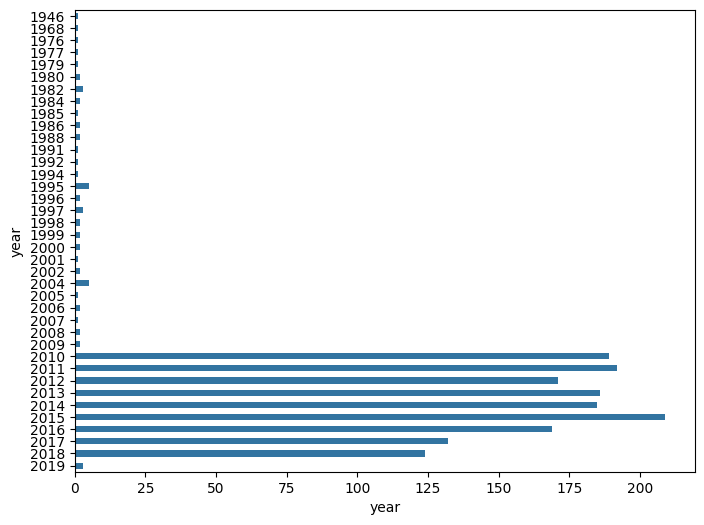

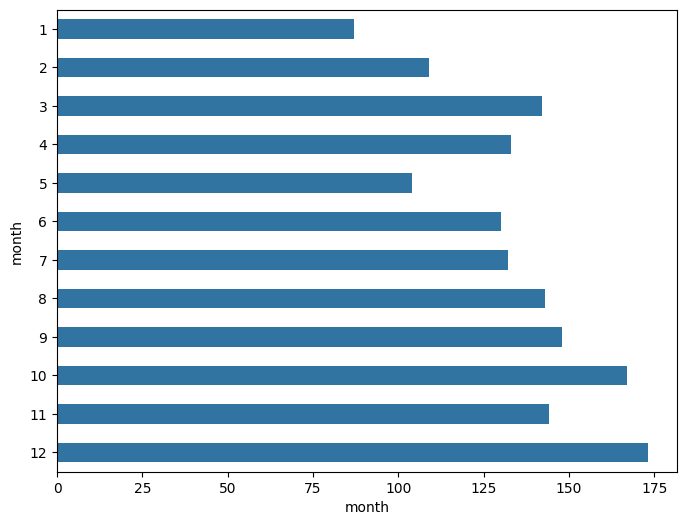

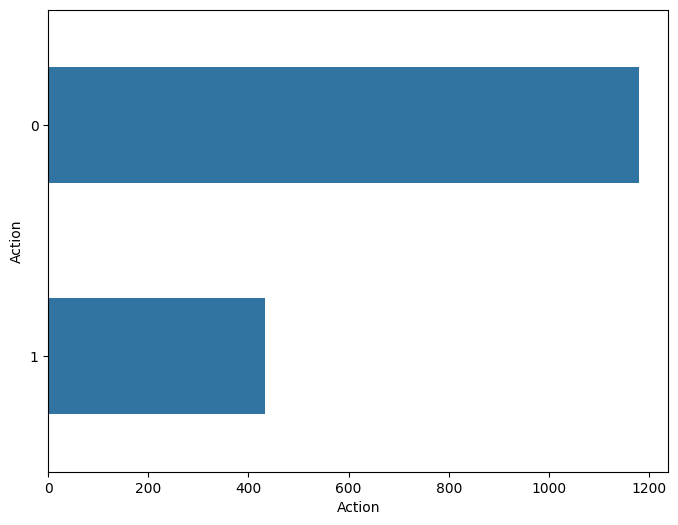

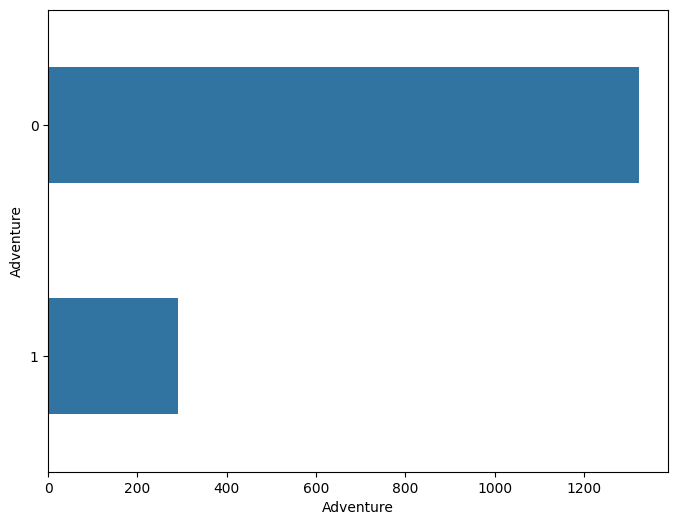

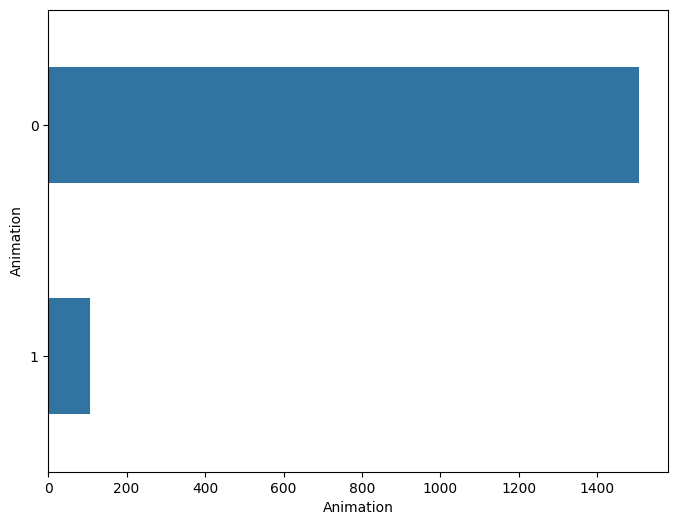

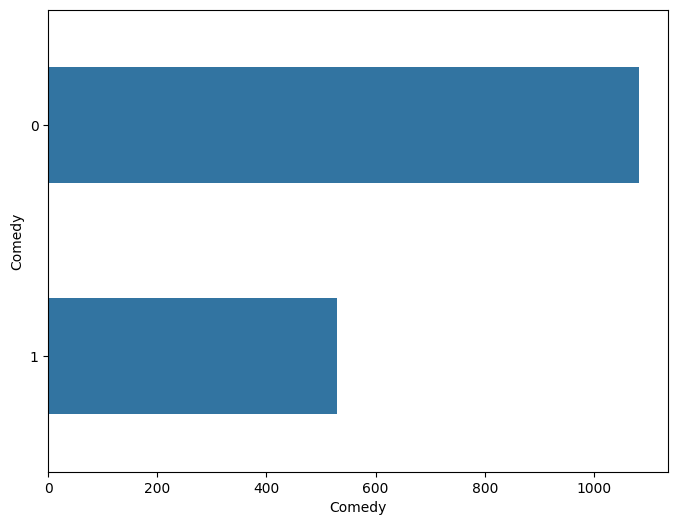

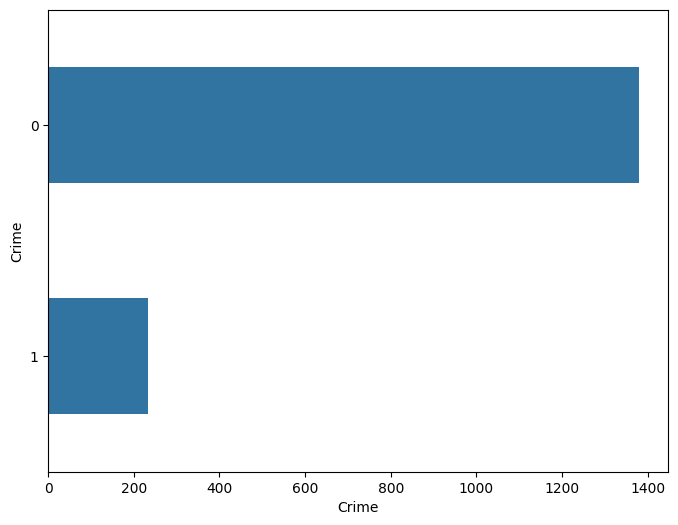

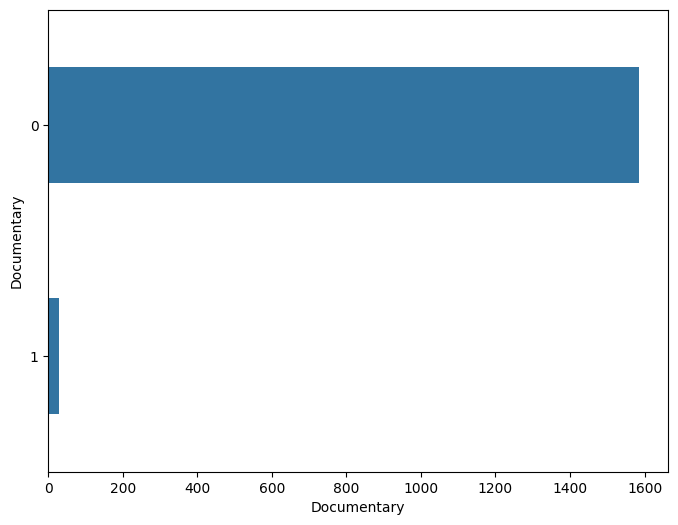

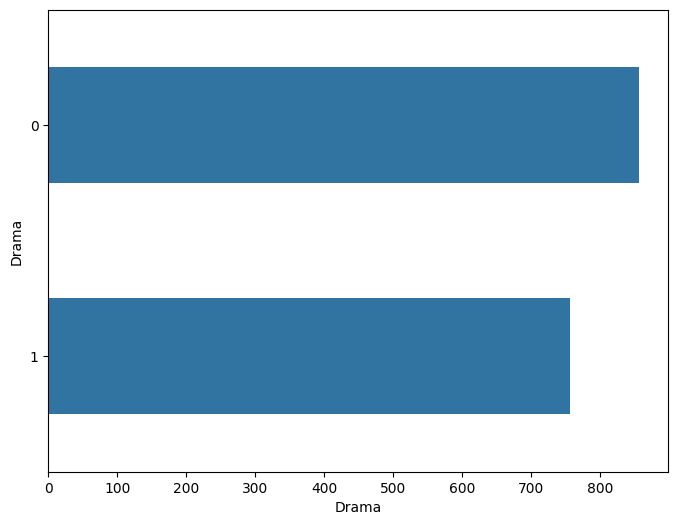

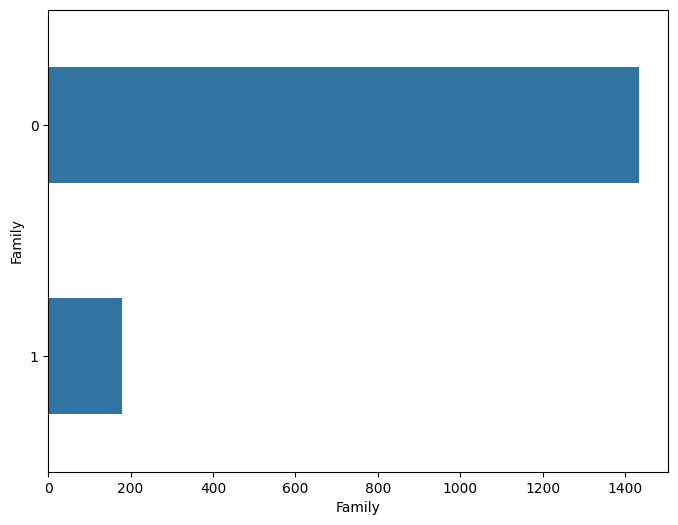

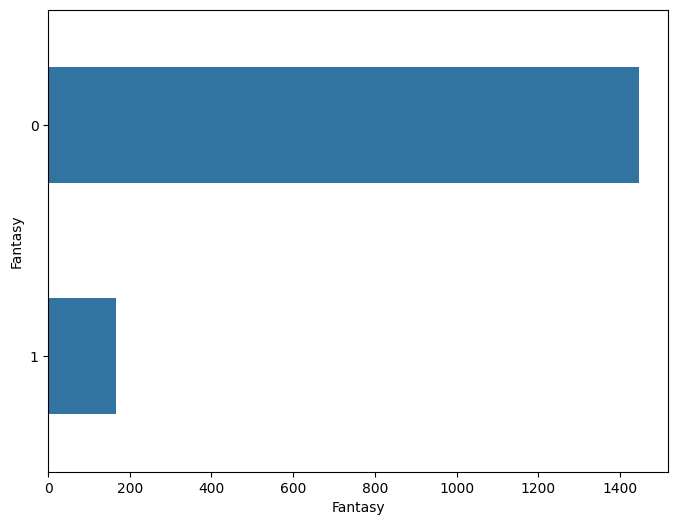

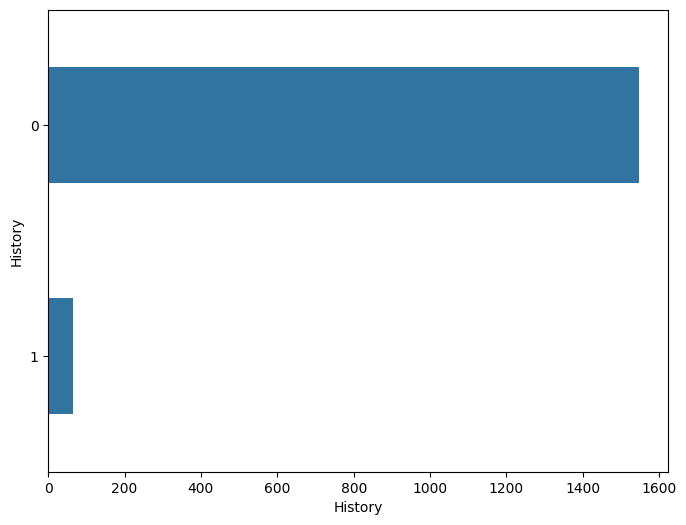

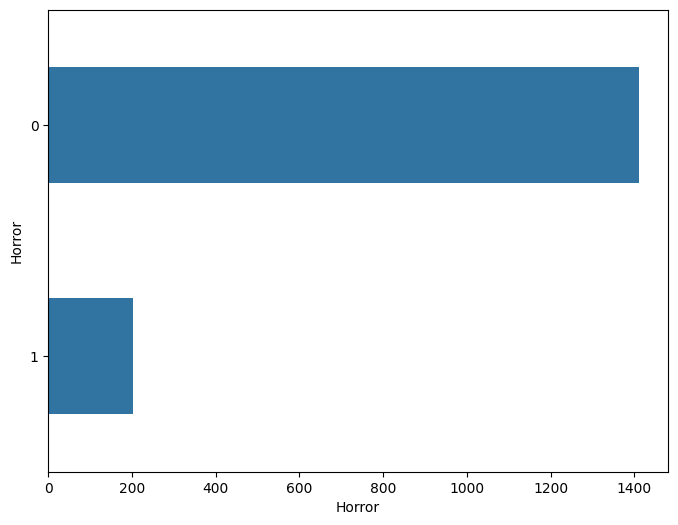

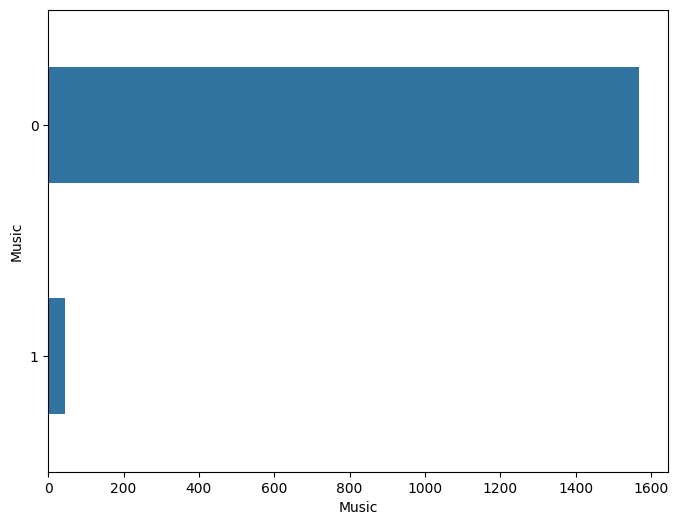

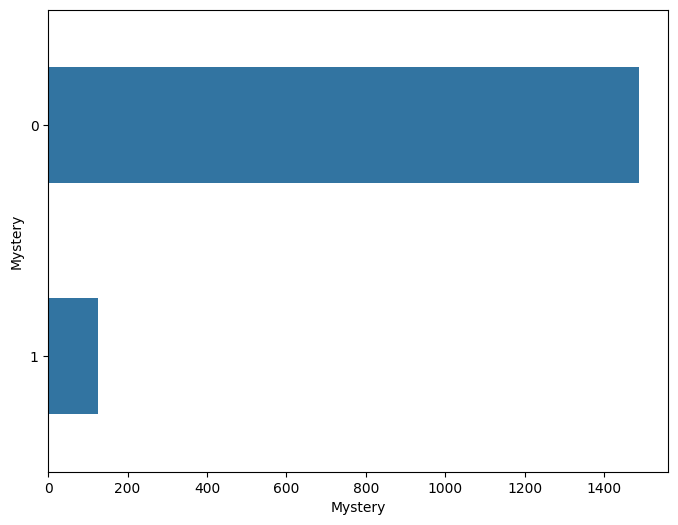

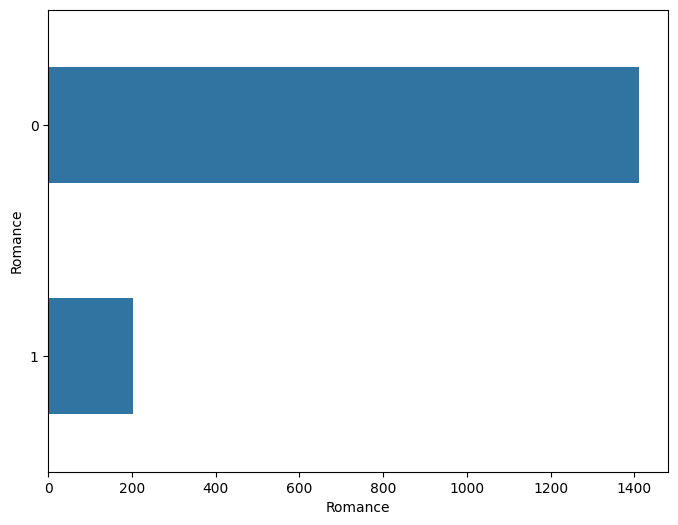

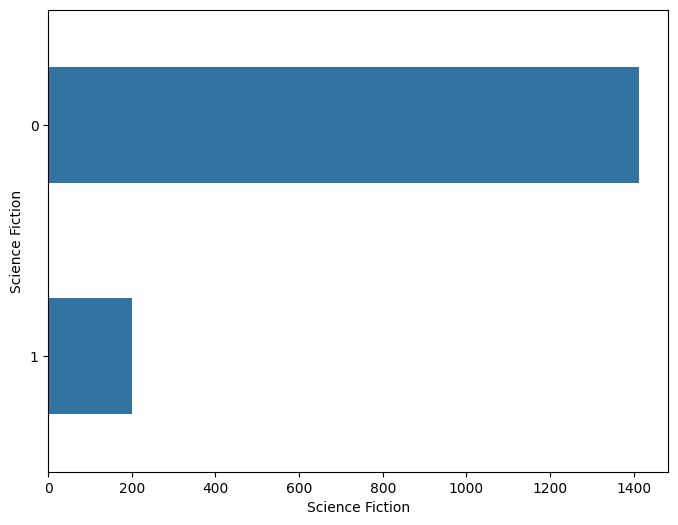

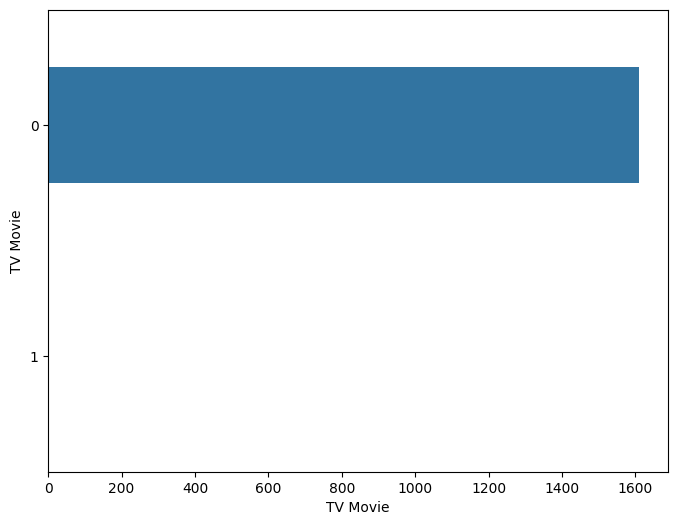

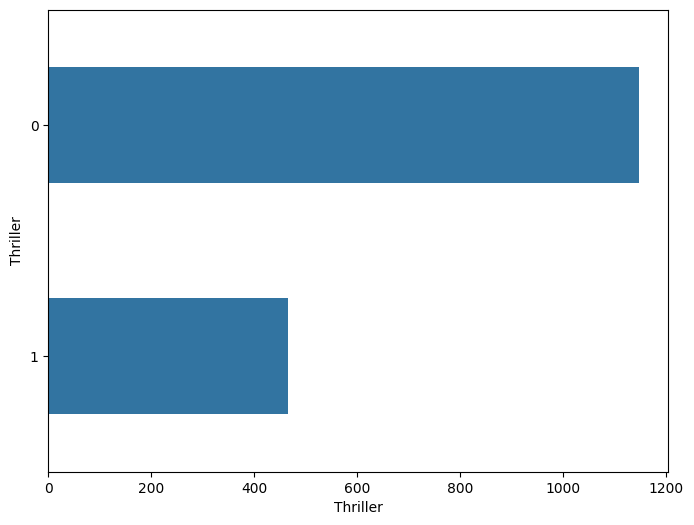

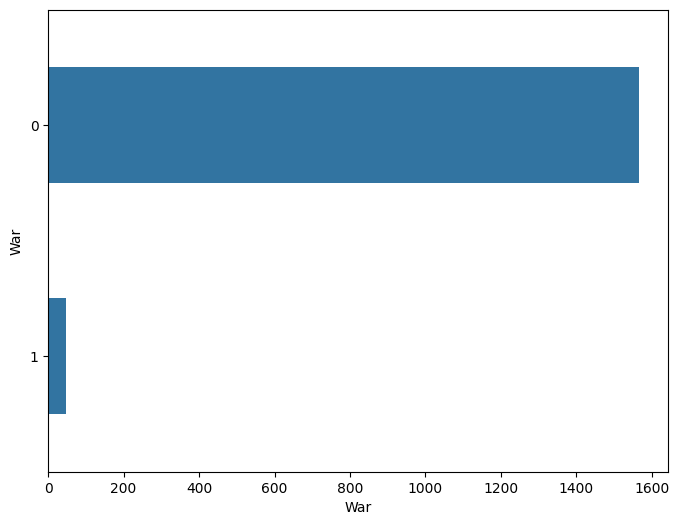

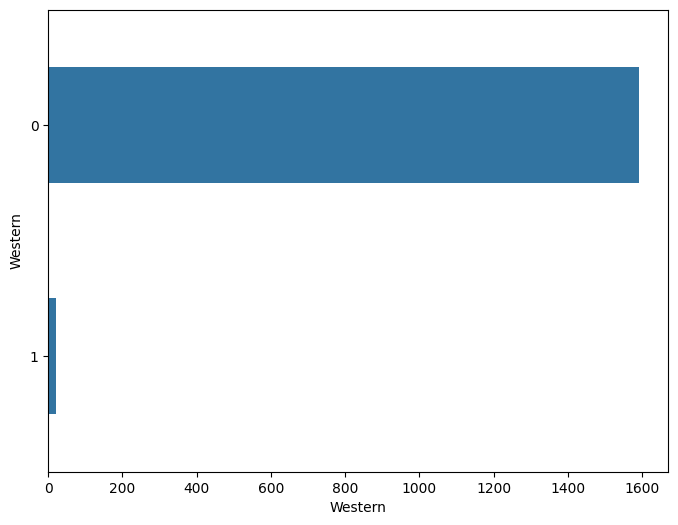

In [ ]:
for col in numerical_cols:
    if col in ['year', 'month', 'Action', 'Adventure', 'Animation', 'Comedy', 'Crime',
               'Documentary', 'Drama', 'Family', 'Fantasy', 'History',
               'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction','TV Movie', 'Thriller', 'War', 'Western']:
        plt.figure(figsize=(8, 6))
        sns.countplot(data = df, y = col, width = 0.5)
        plt.xlabel(col)
        plt.show()


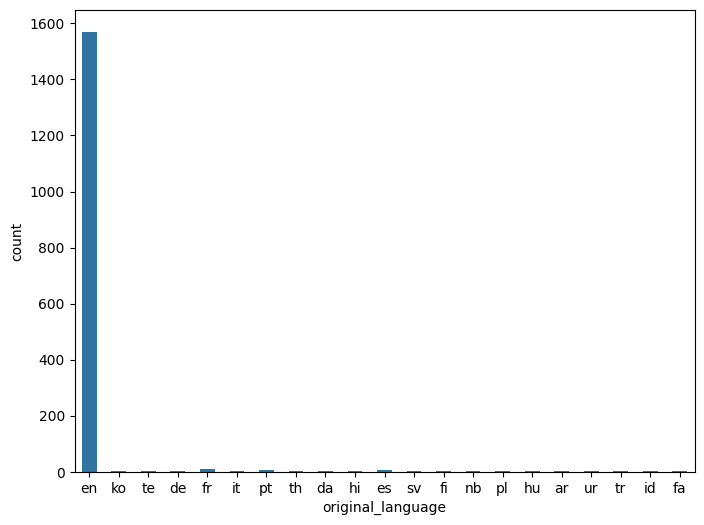

In [ ]:
for col in category_cols:
    if col in ['original_language']:
        plt.figure(figsize=(8, 6))
        sns.countplot(data = df, x = col, width = 0.5)
        plt.xlabel(col)
        plt.show()

## Multivariate Analysis.


Analyze the relationships between the variables and three key performance indicators: Worldwide Gross Revenue, Profit, and ROI (Return on Investment).


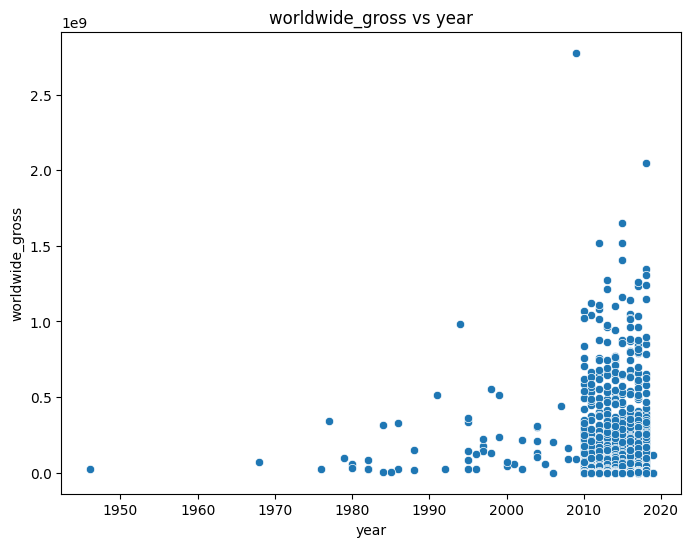

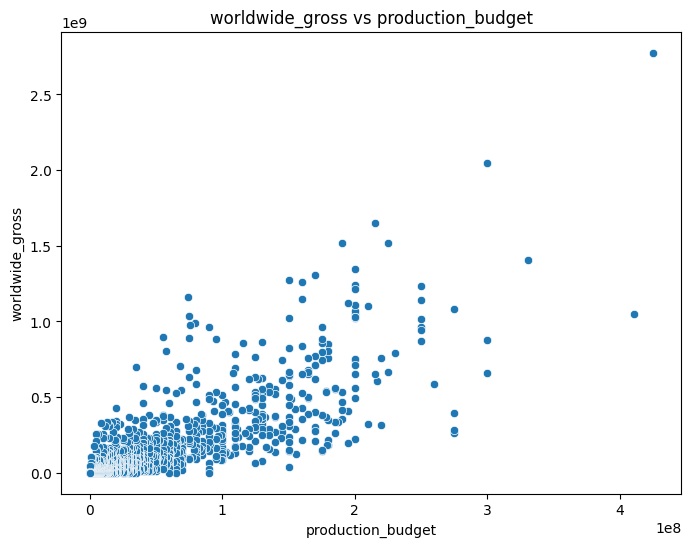

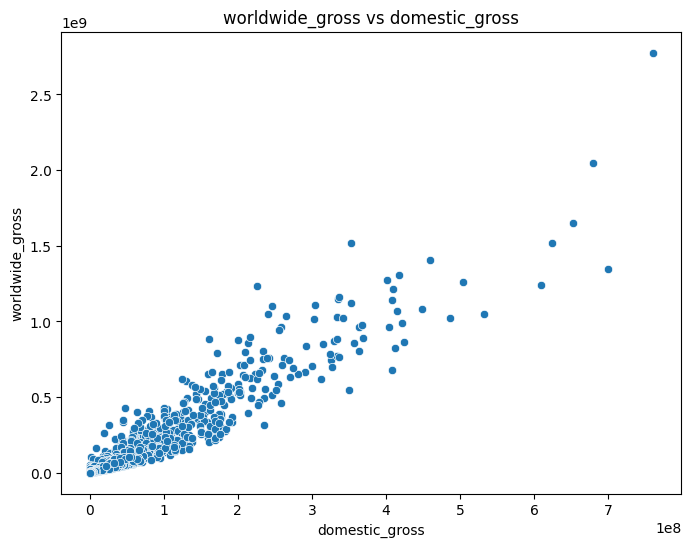

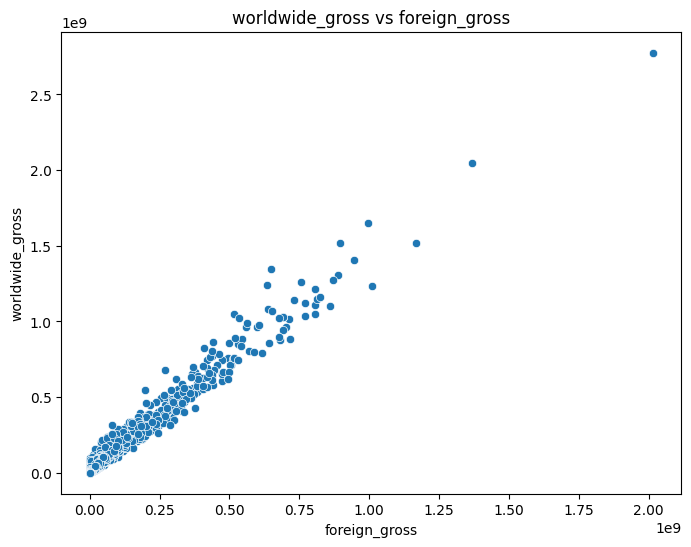

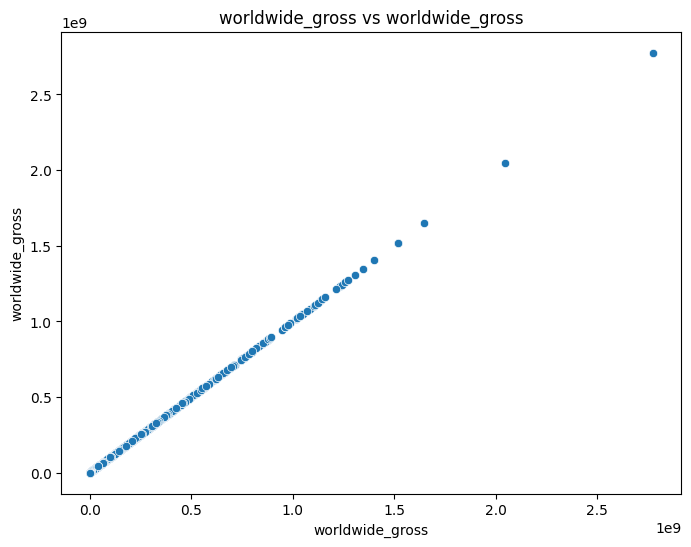

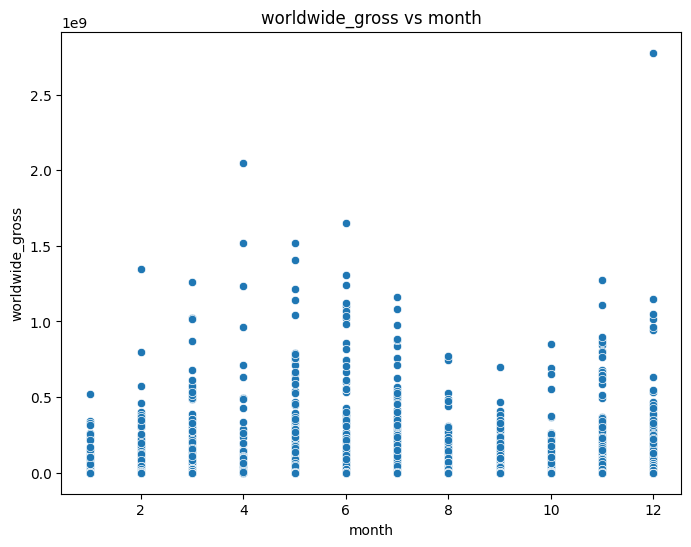

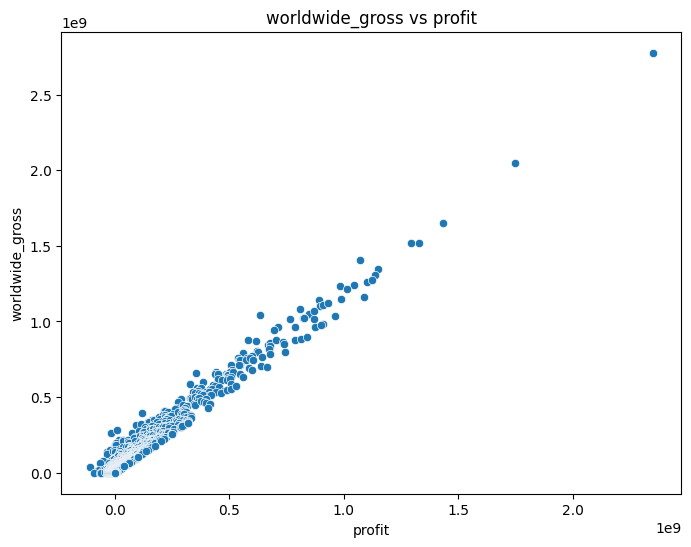

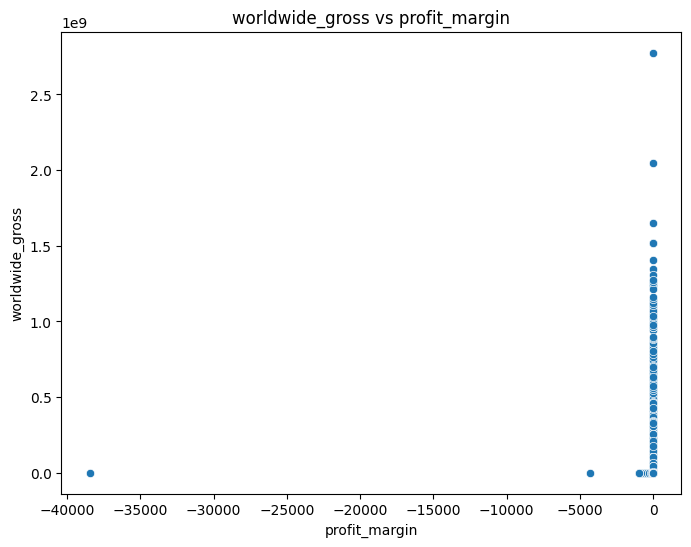

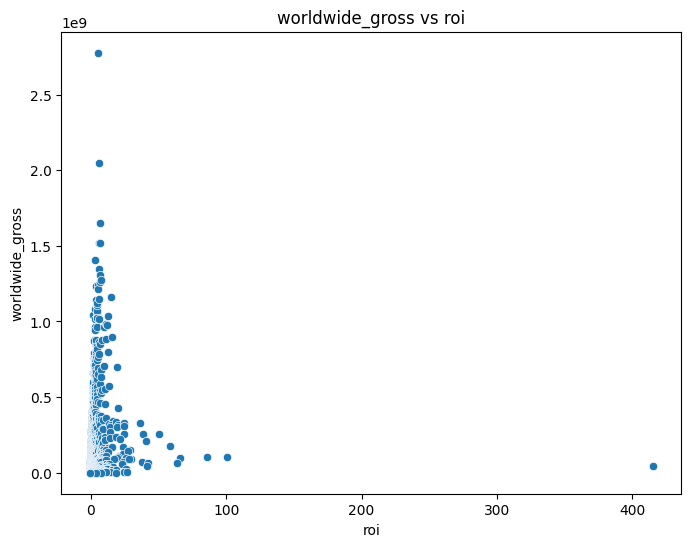

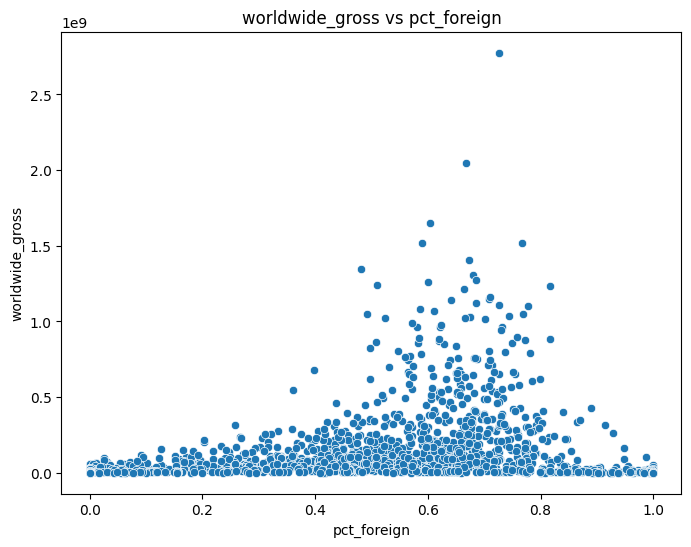

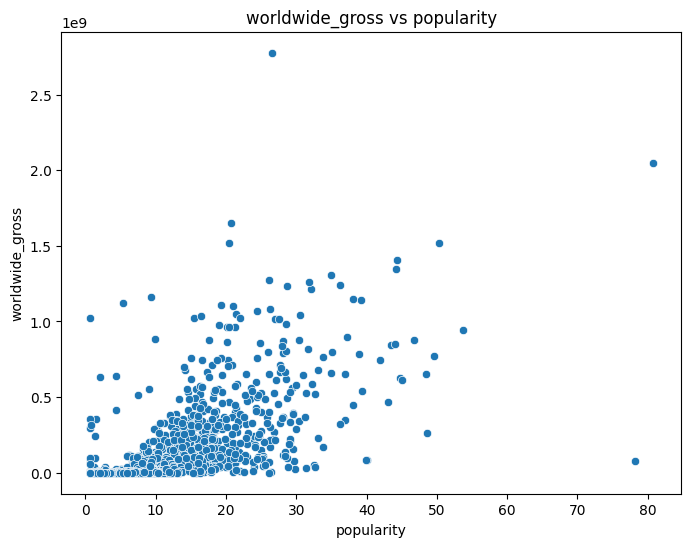

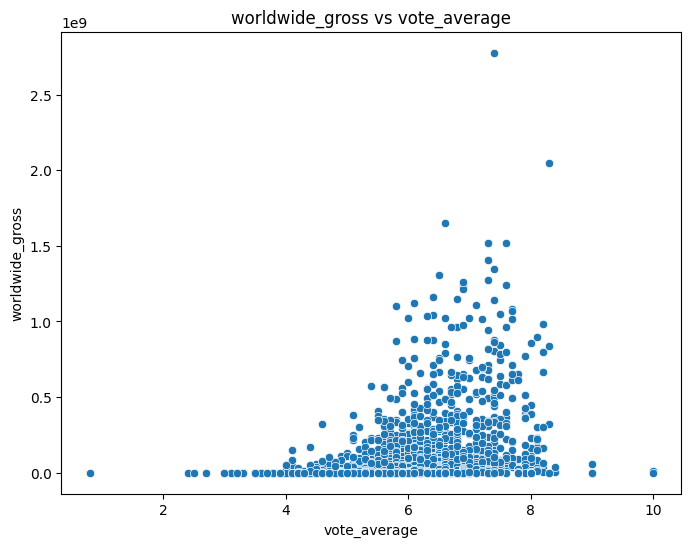

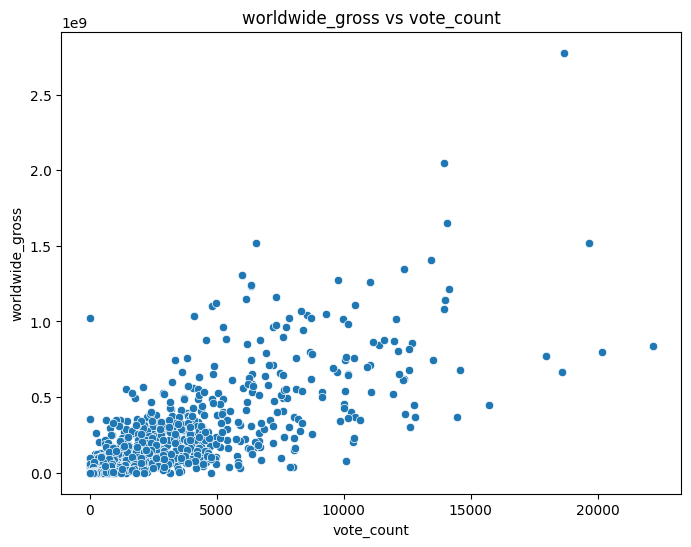

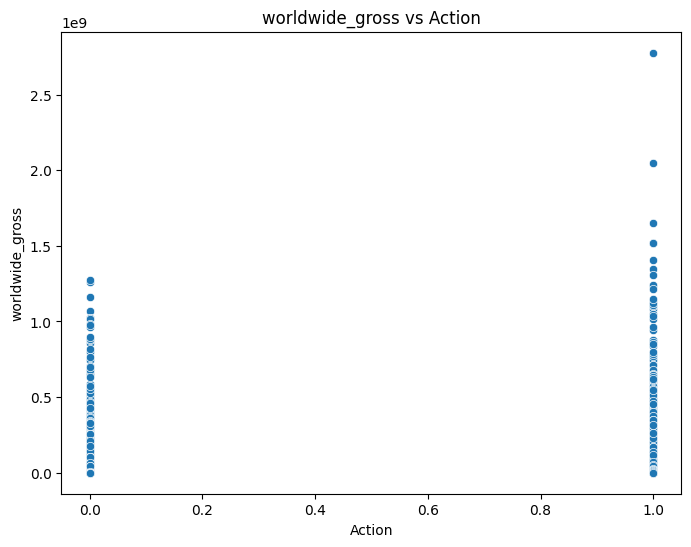

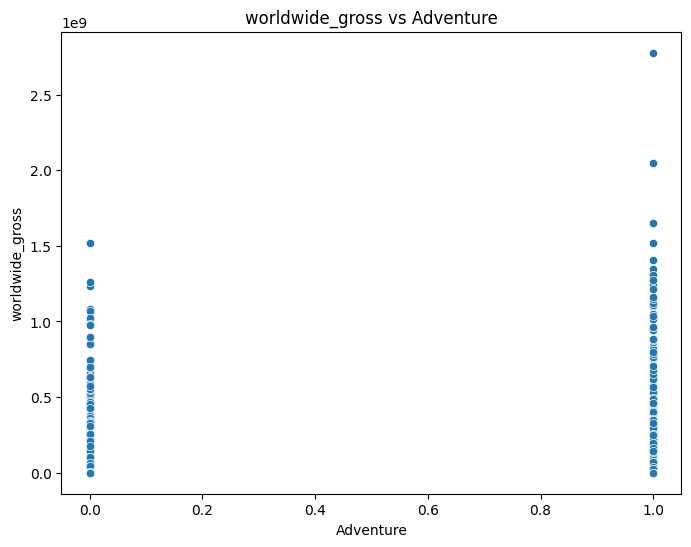

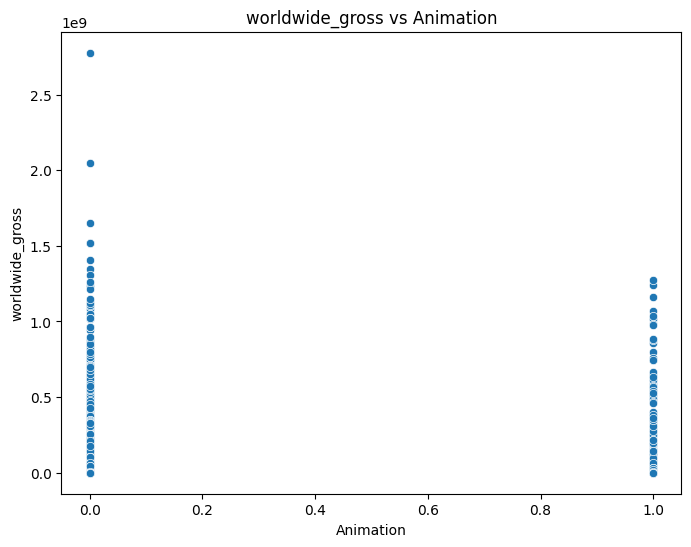

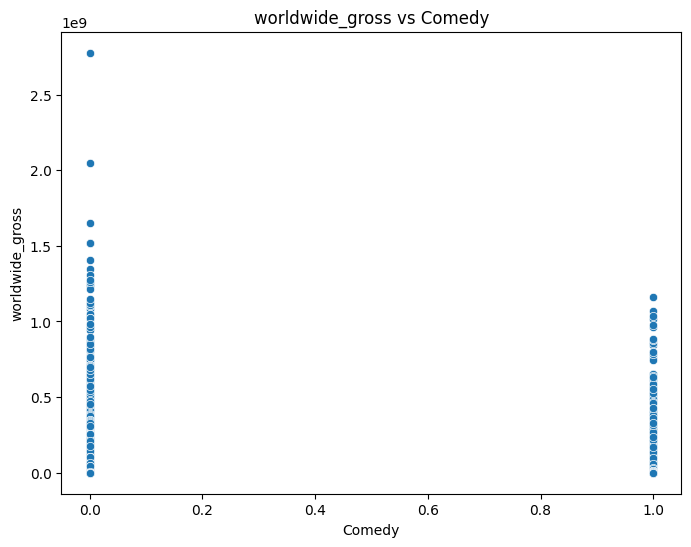

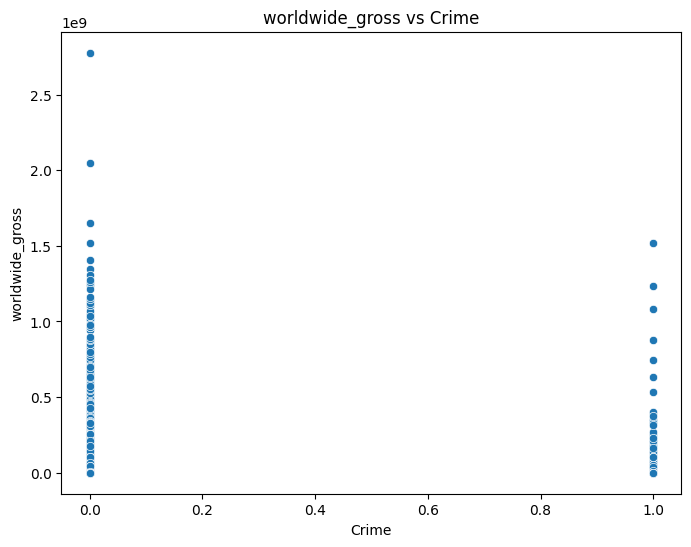

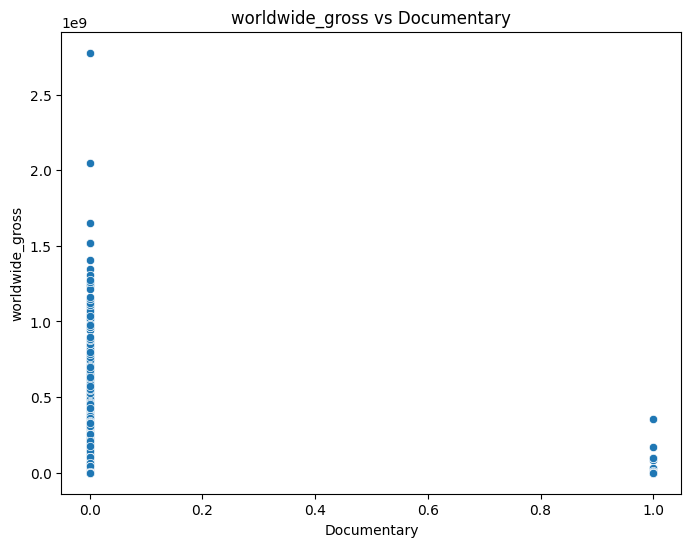

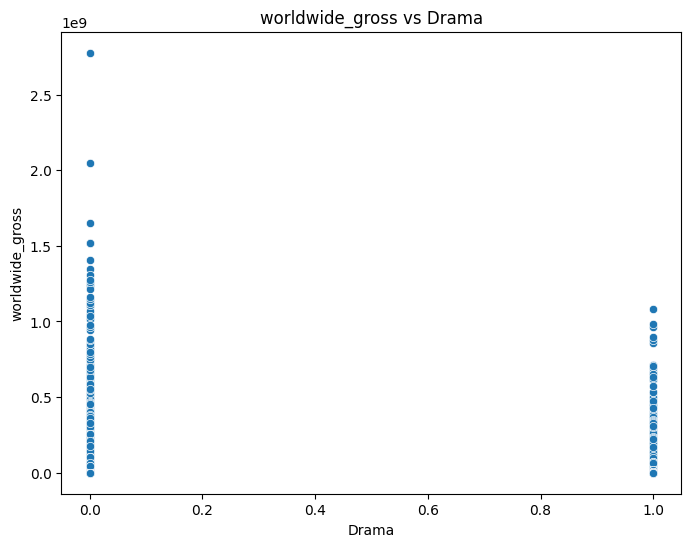

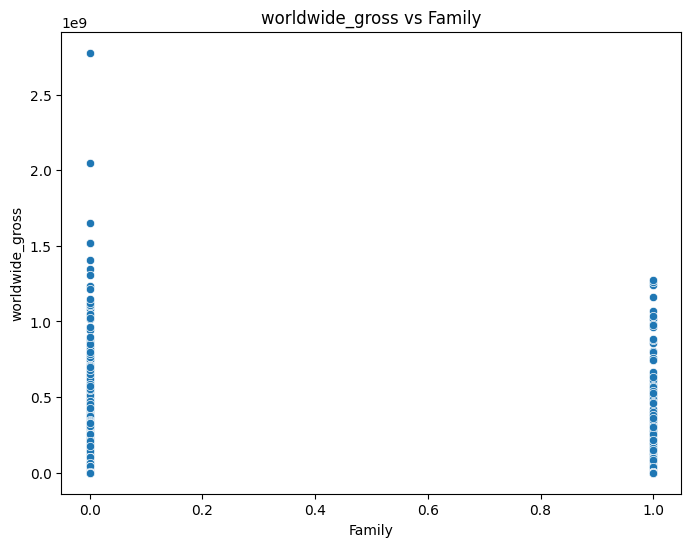

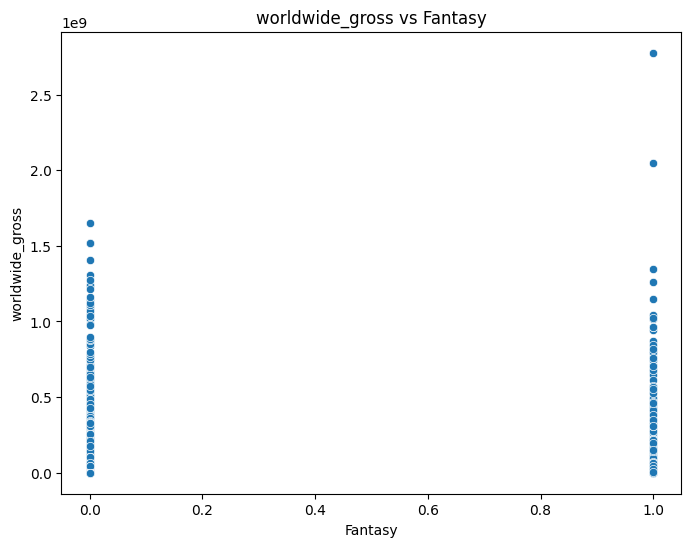

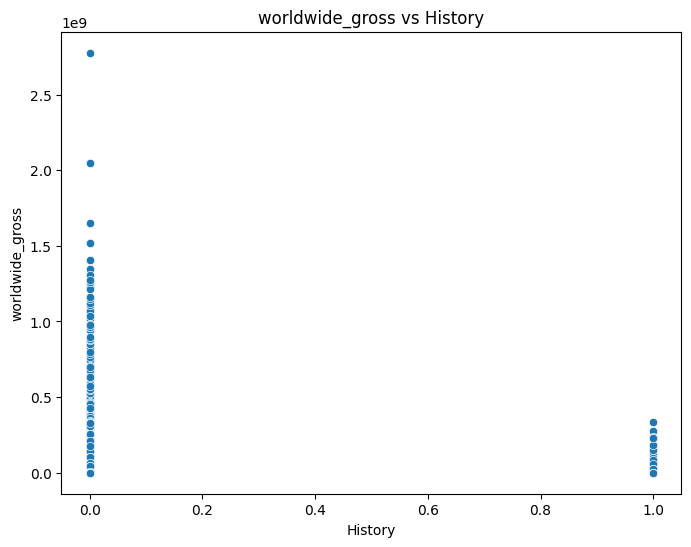

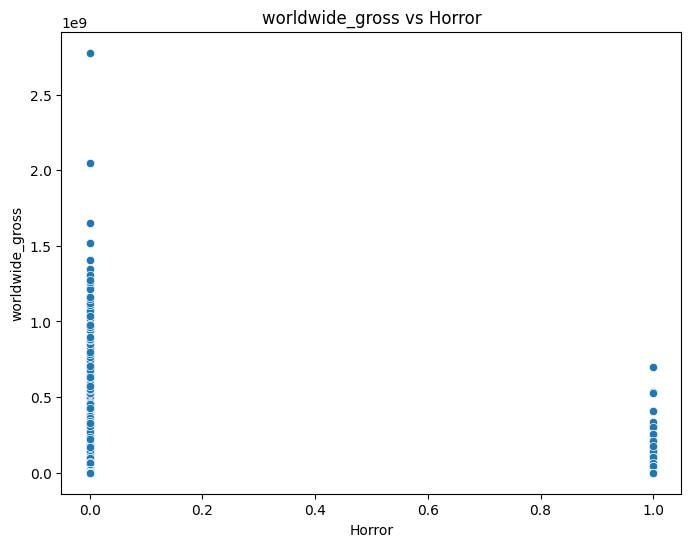

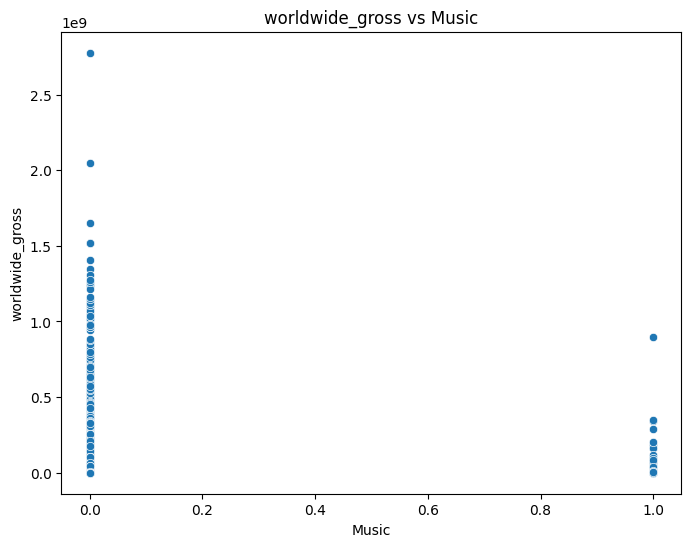

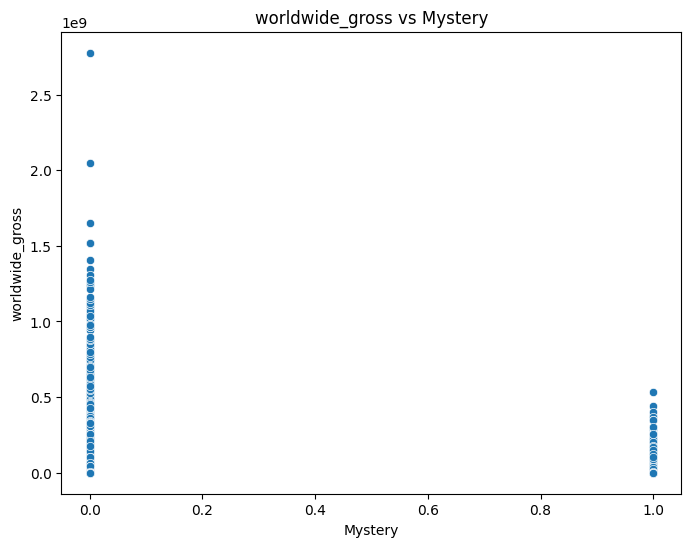

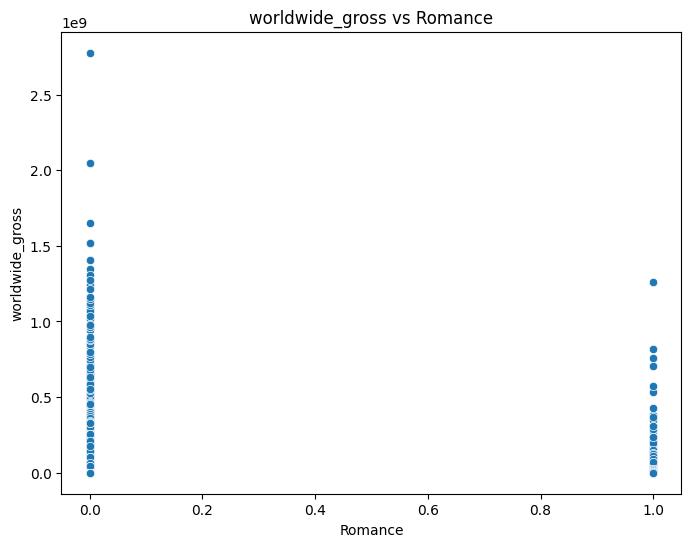

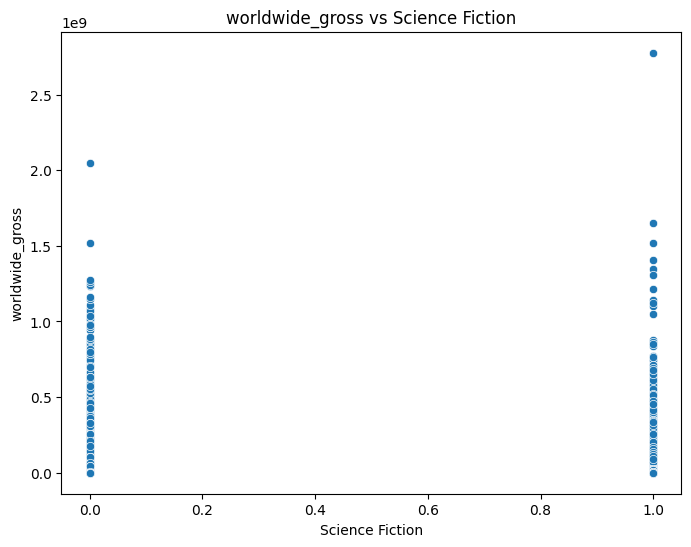

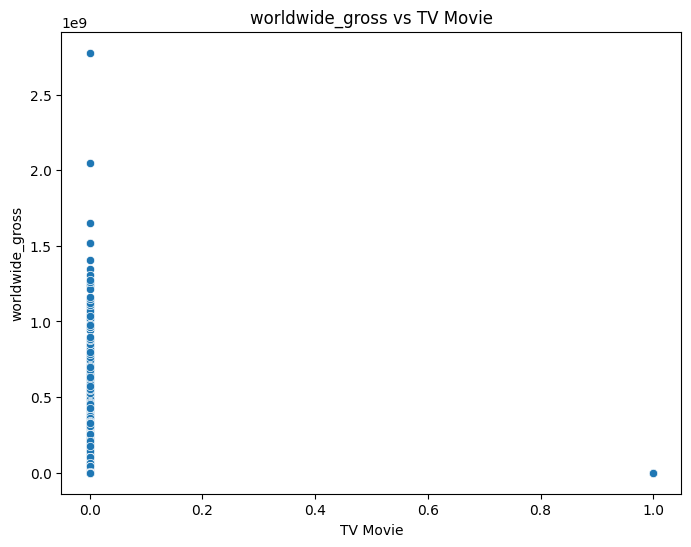

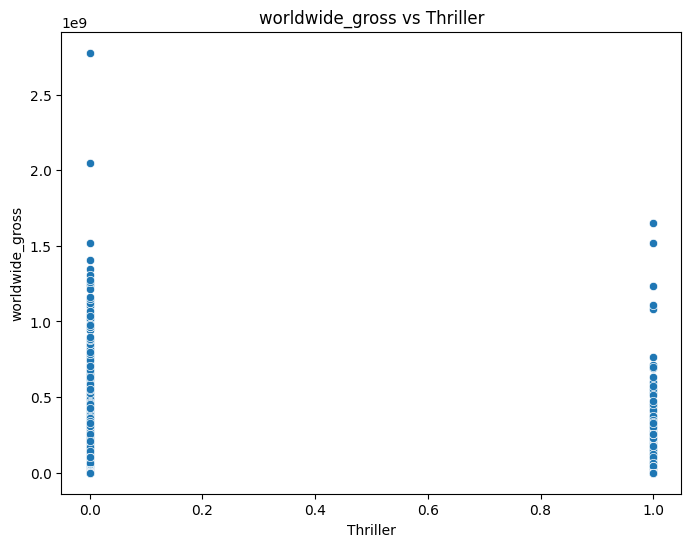

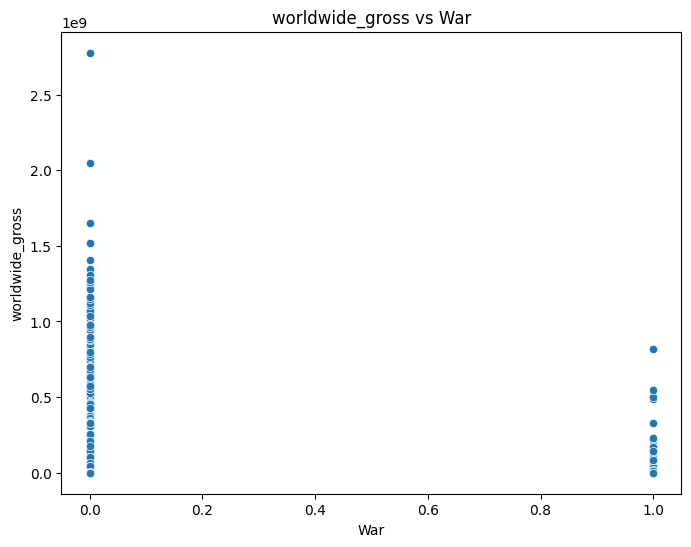

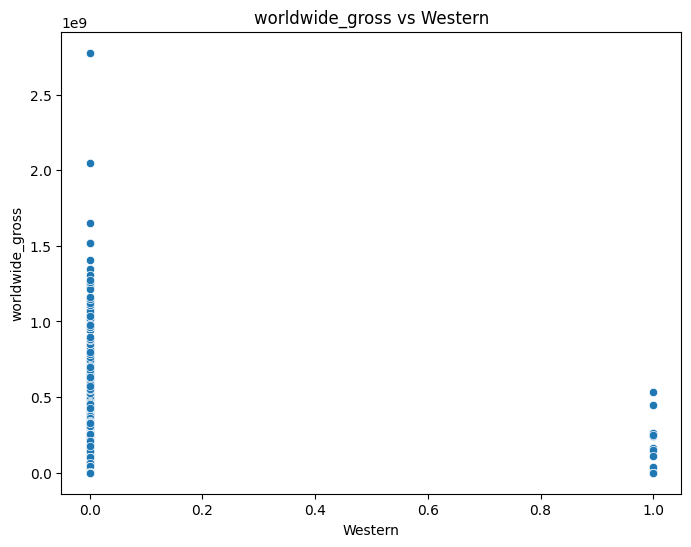

In [ ]:
for col in numerical_cols:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=df, x=col, y='worldwide_gross')
    plt.xlabel(col)
    plt.ylabel('worldwide_gross')
    plt.title(f'worldwide_gross vs {col}')
    plt.show()

After comparing the variables with Profit


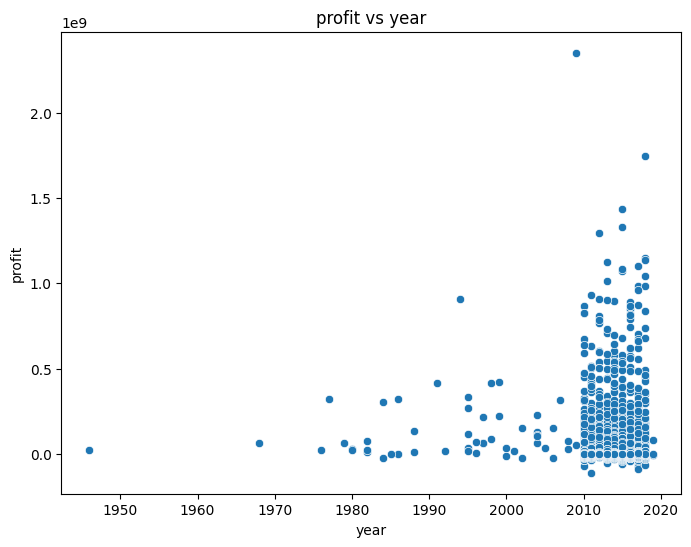

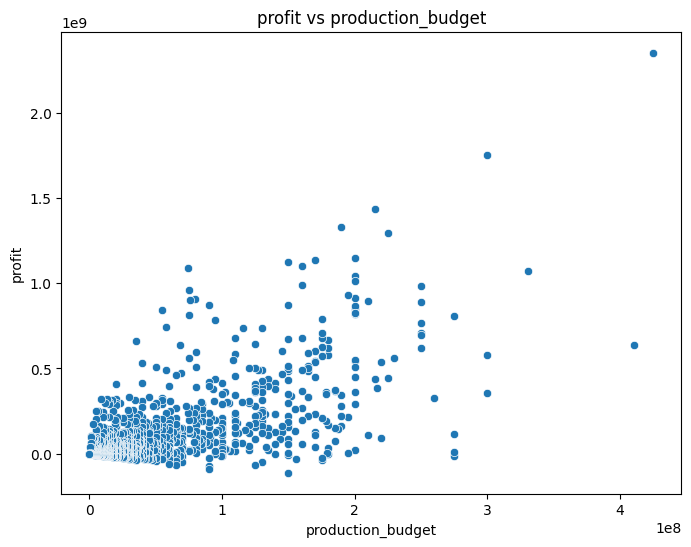

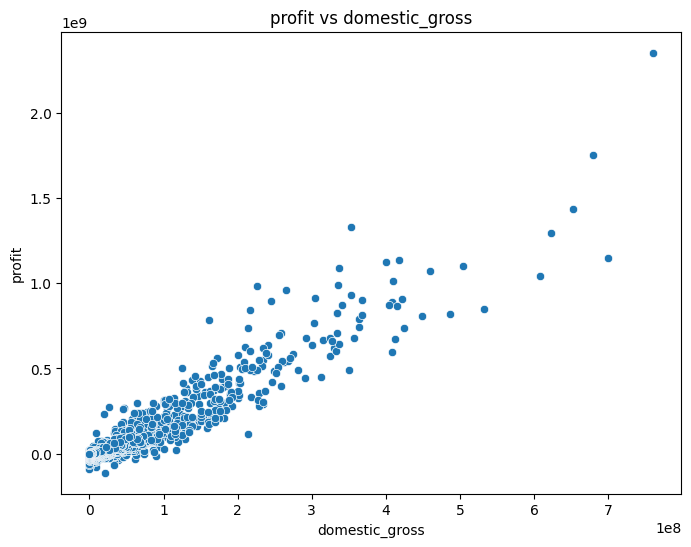

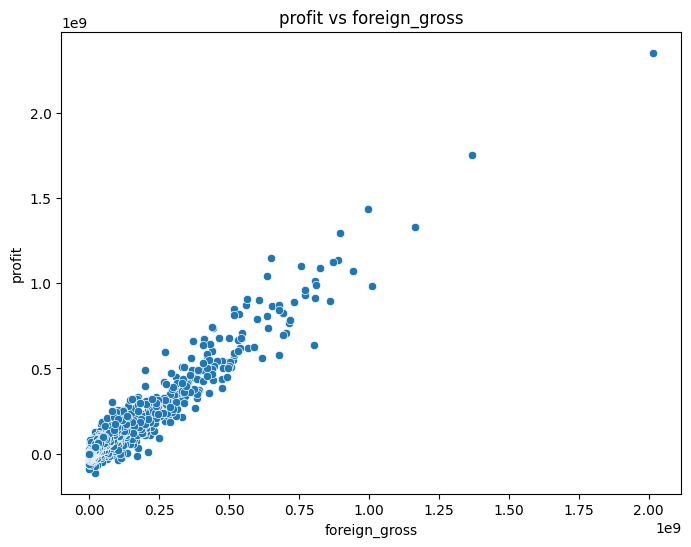

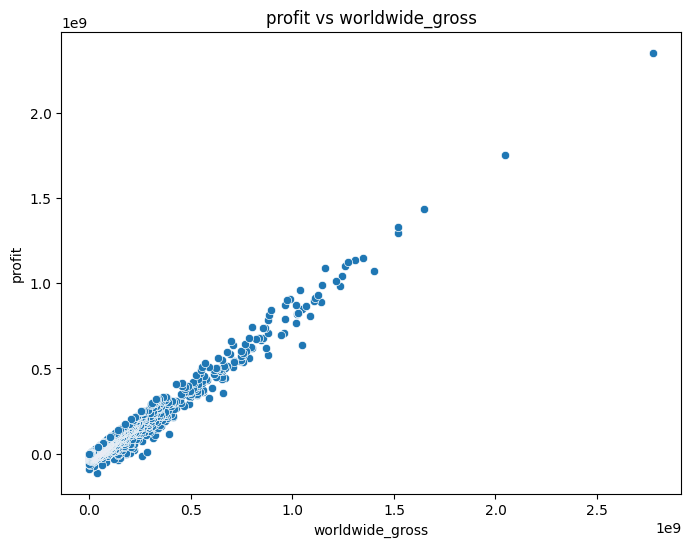

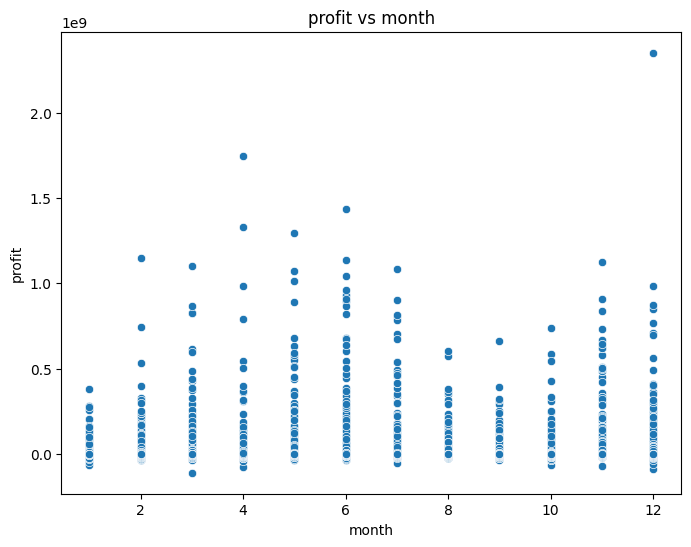

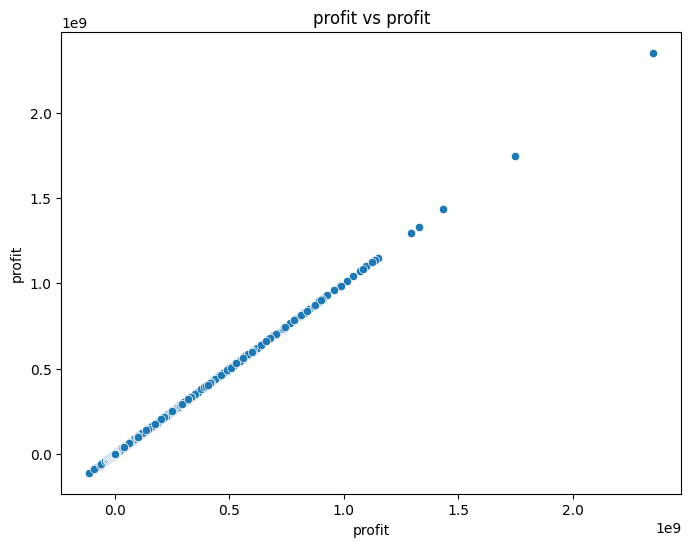

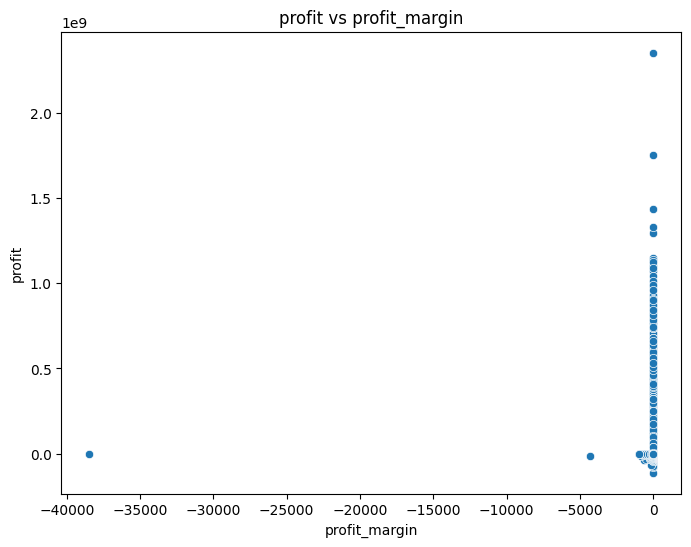

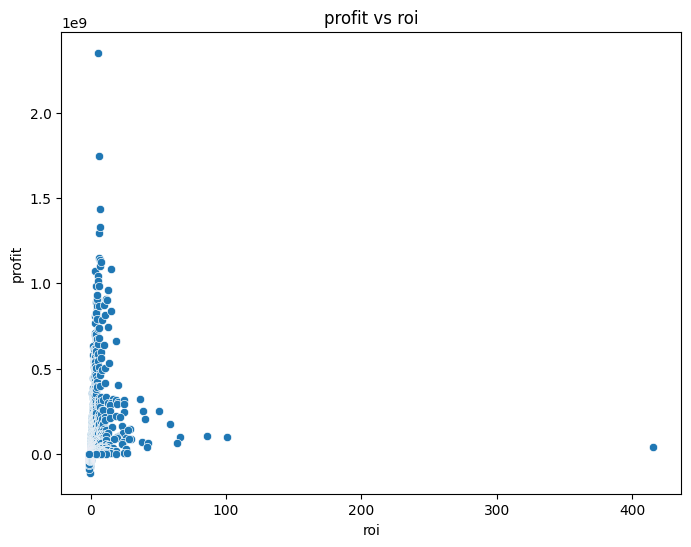

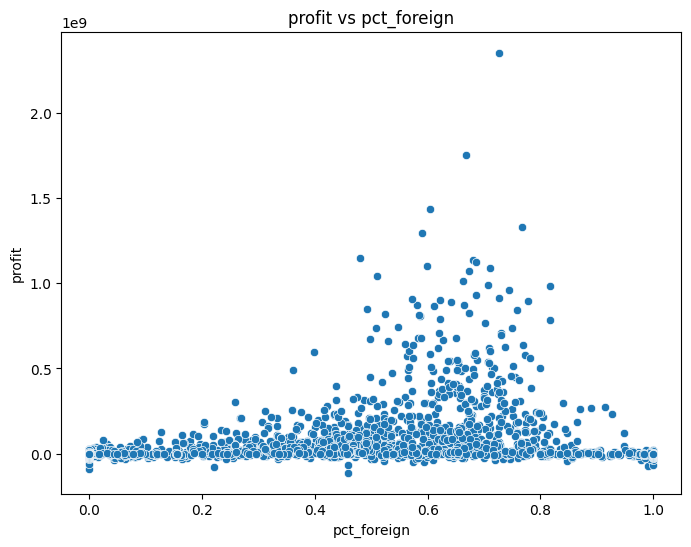

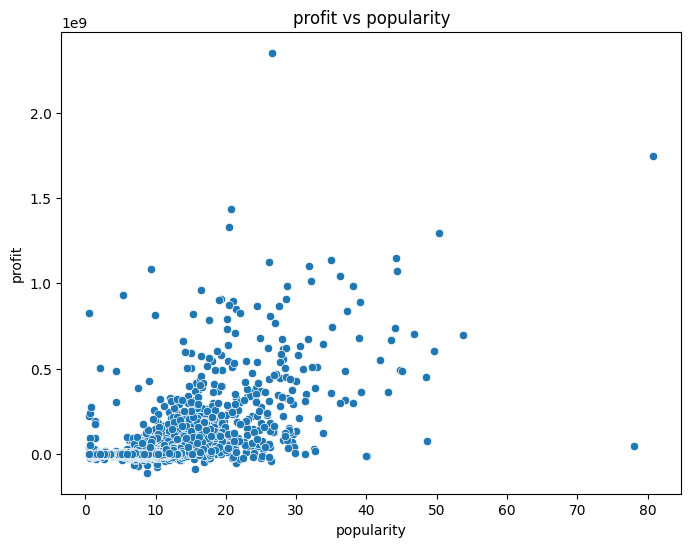

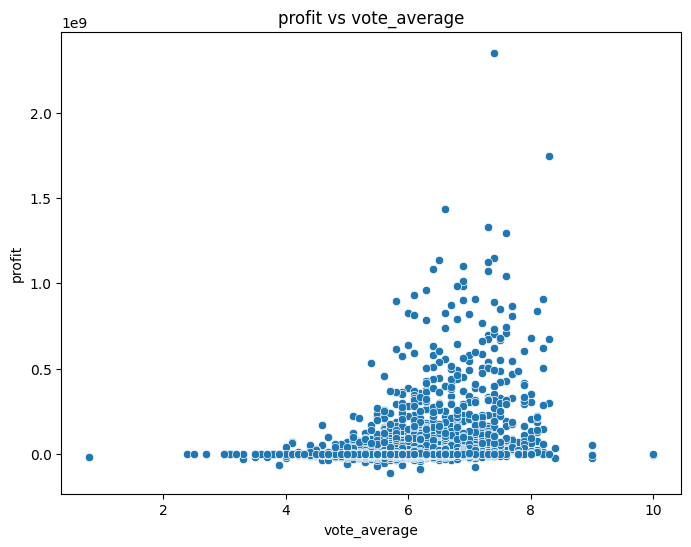

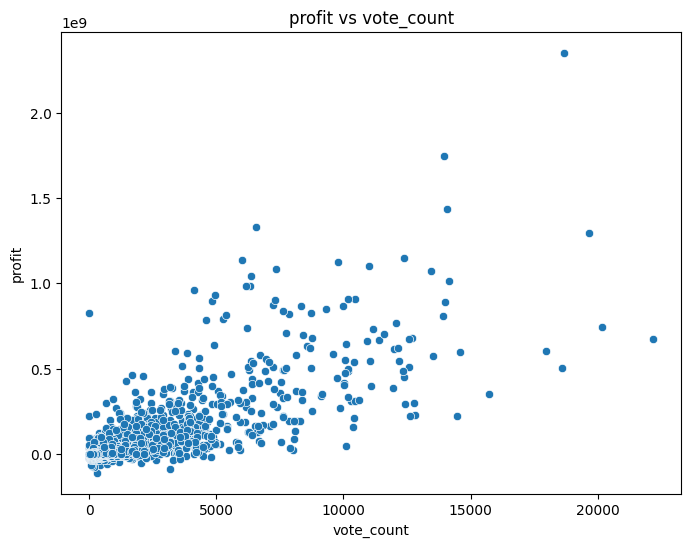

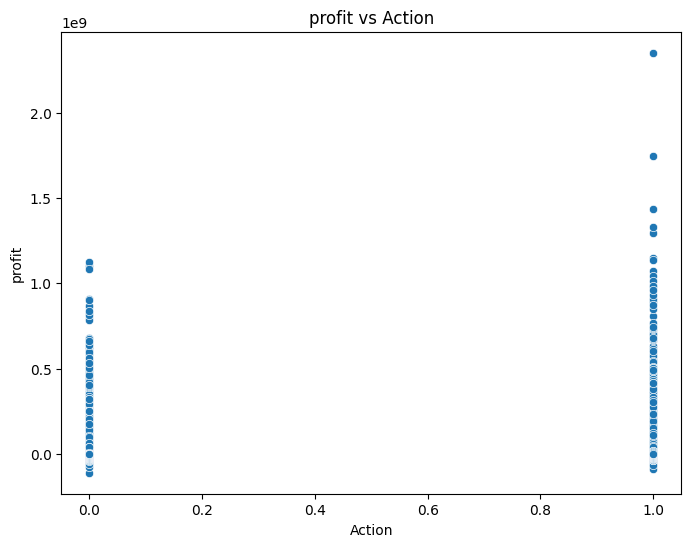

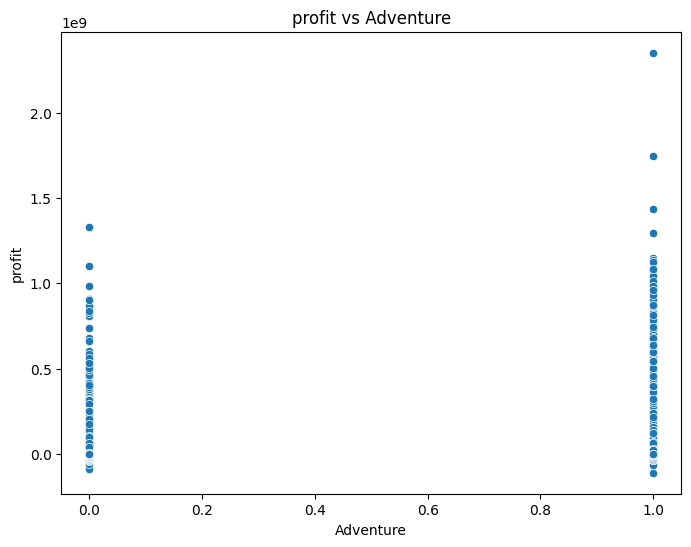

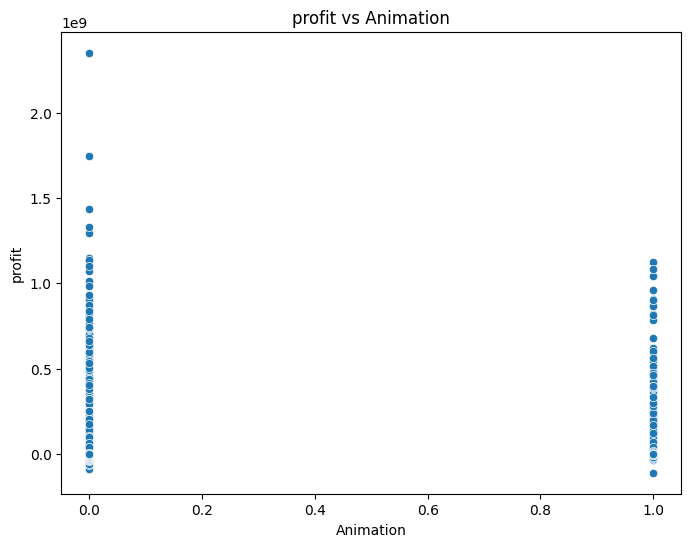

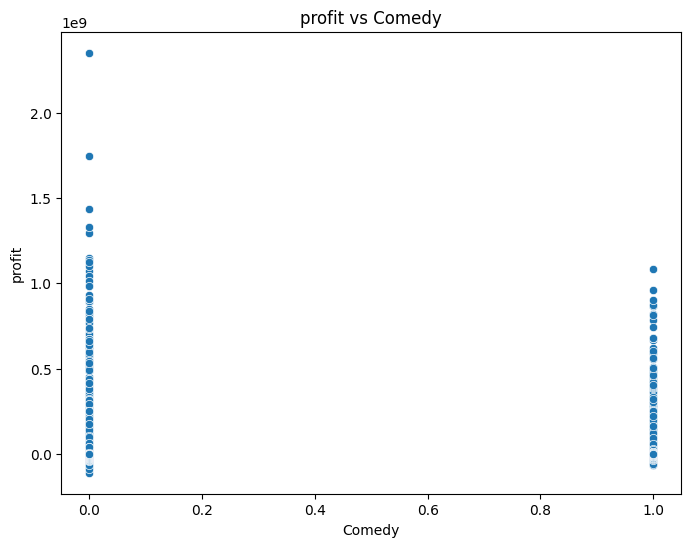

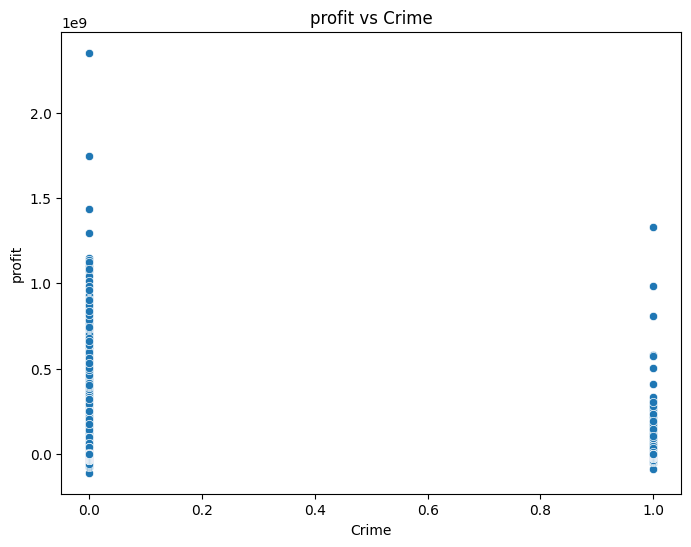

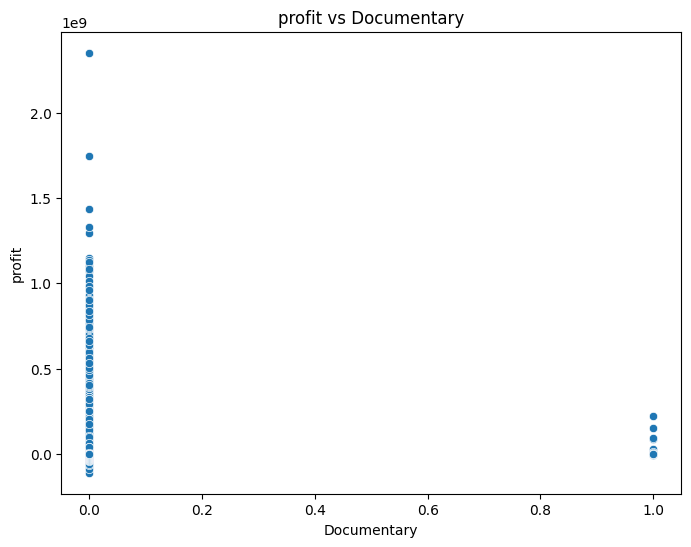

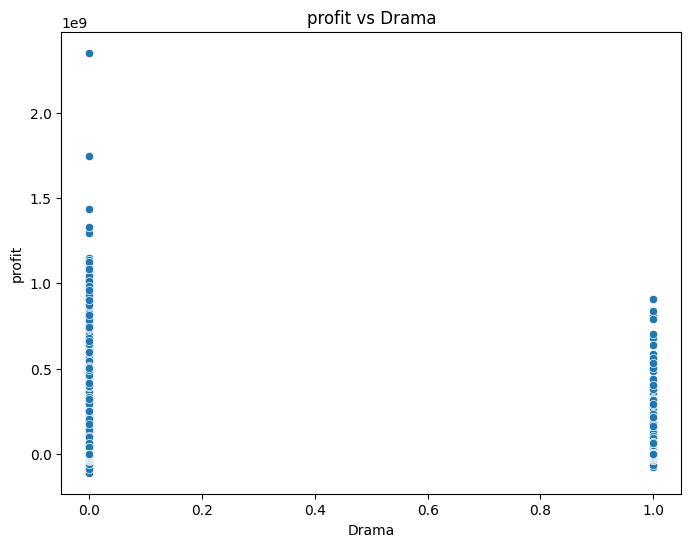

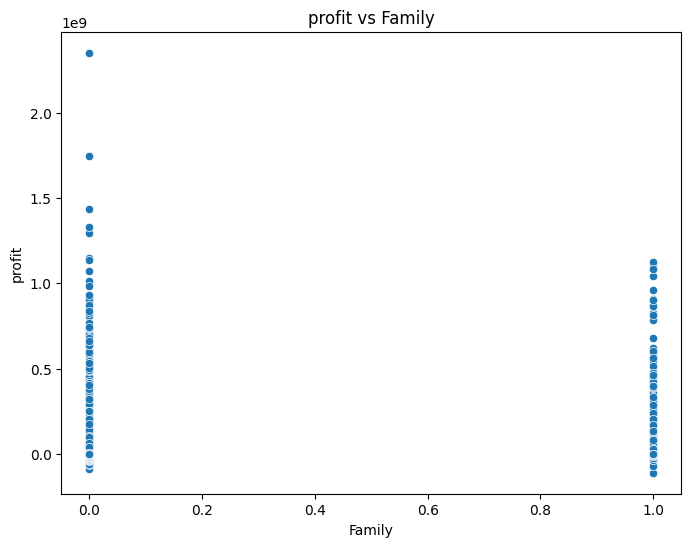

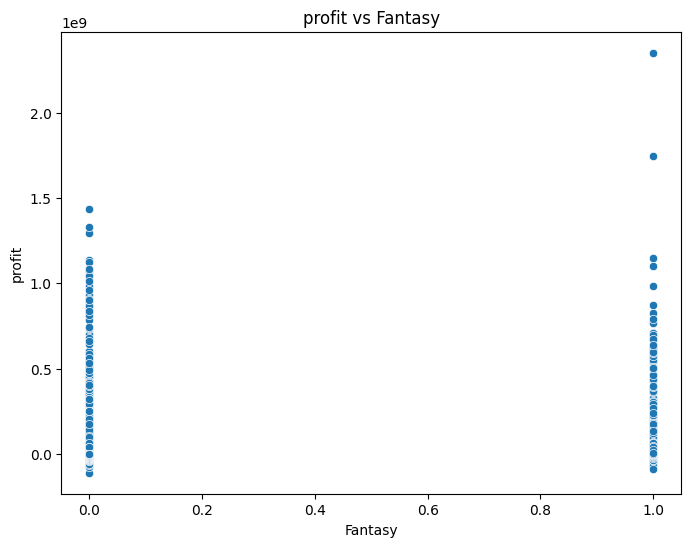

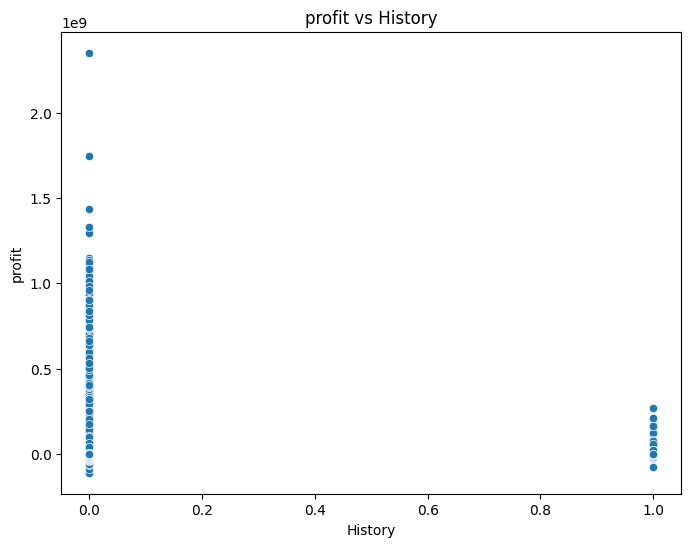

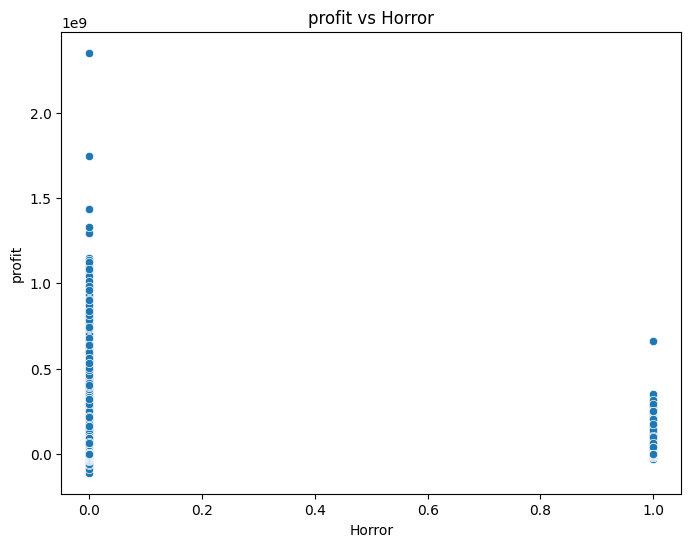

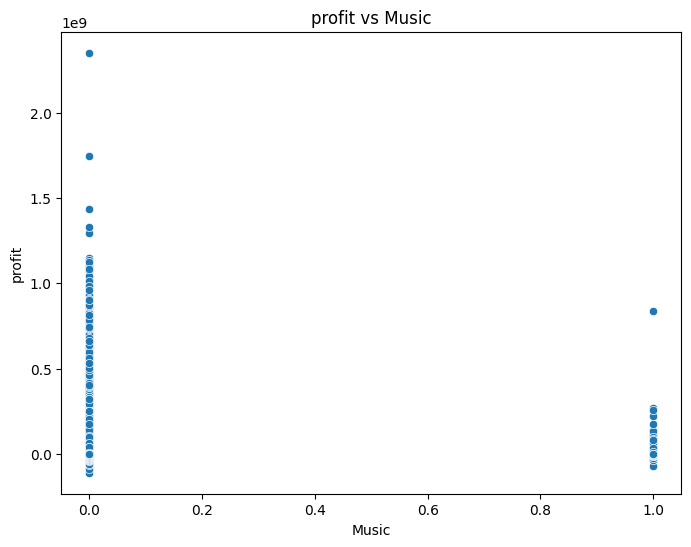

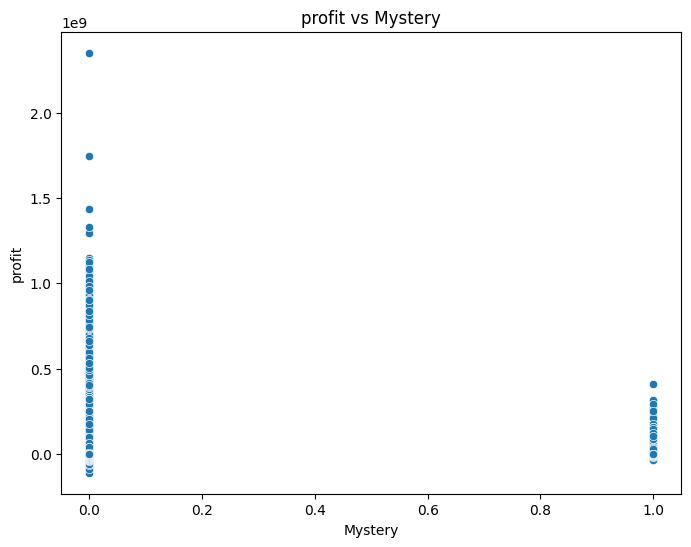

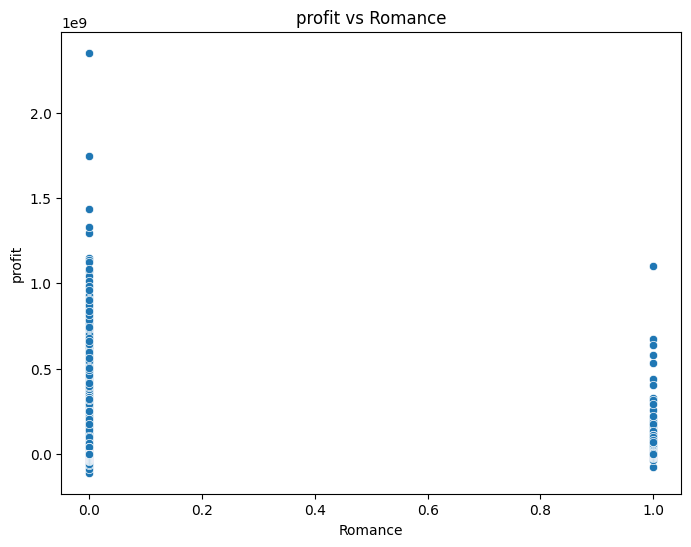

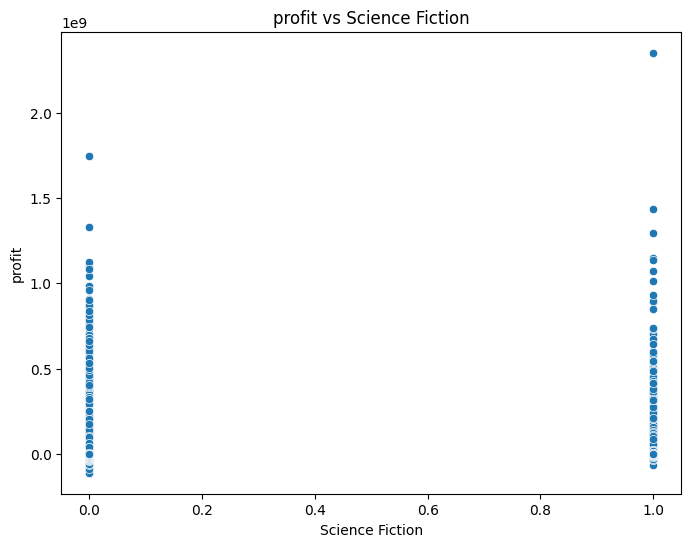

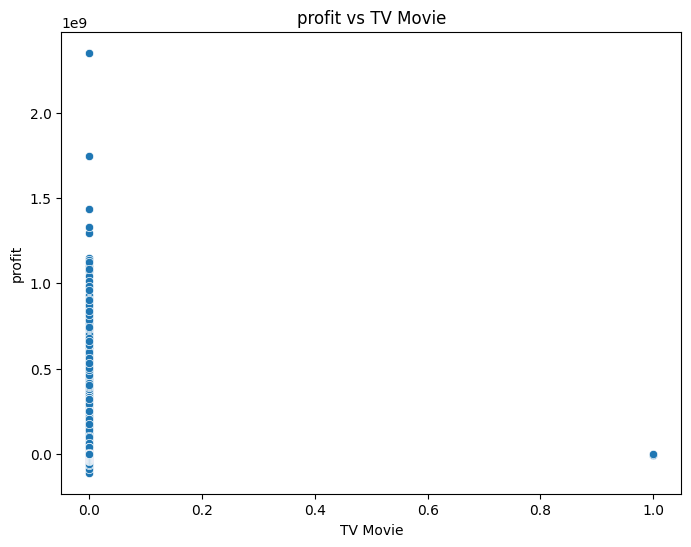

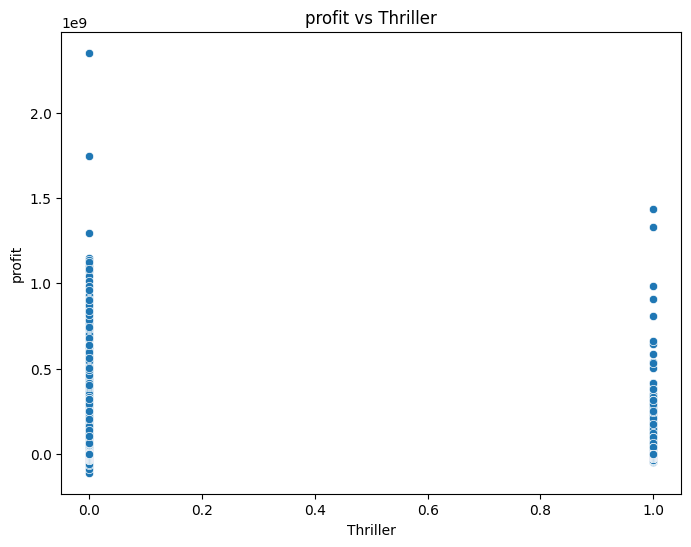

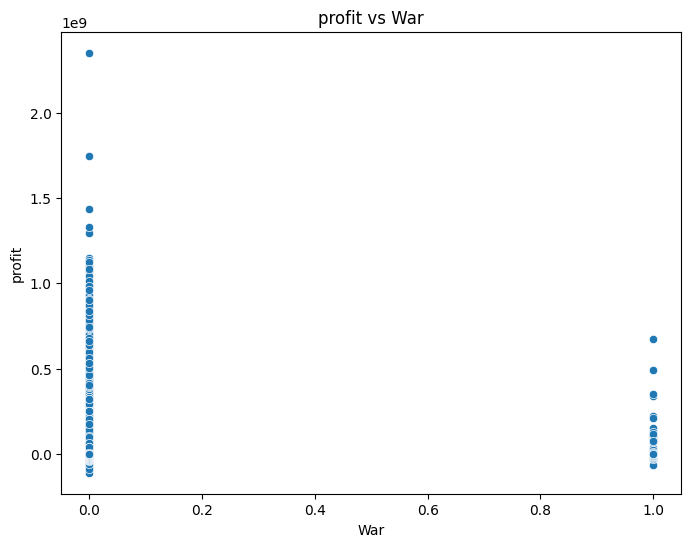

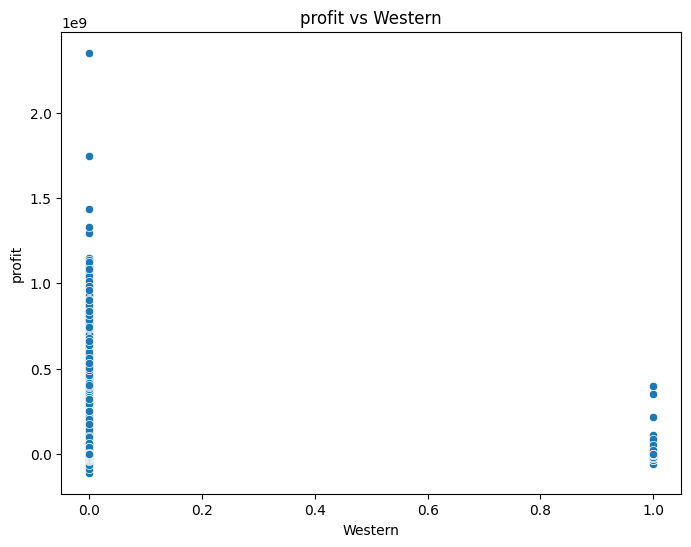

In [ ]:
for col in numerical_cols:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=df, x=col, y='profit')
    plt.xlabel(col)
    plt.ylabel('profit')
    plt.title(f'profit vs {col}')
    plt.show()

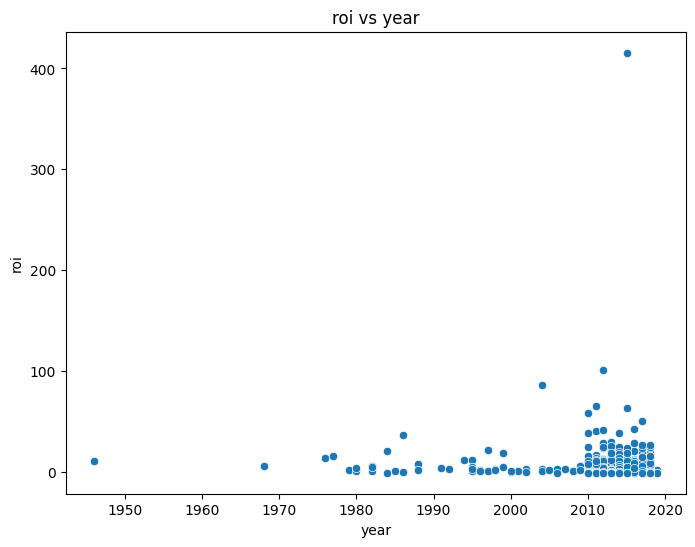

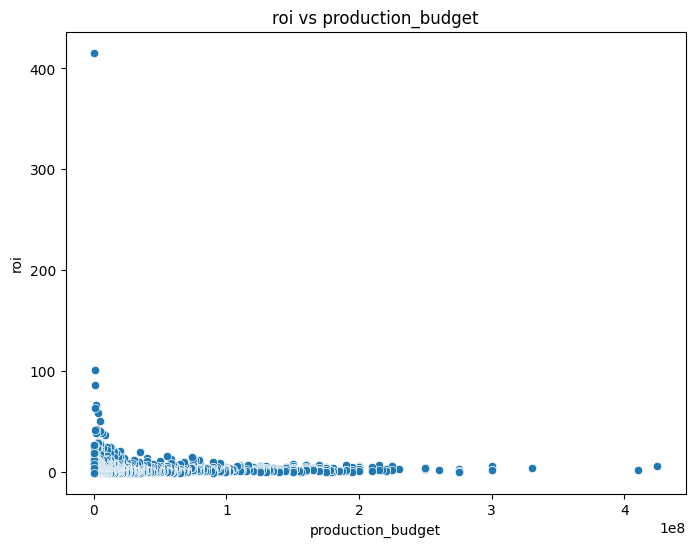

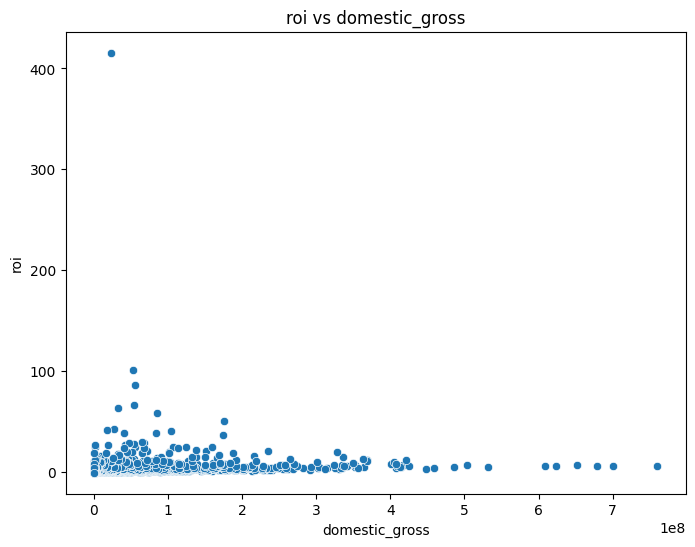

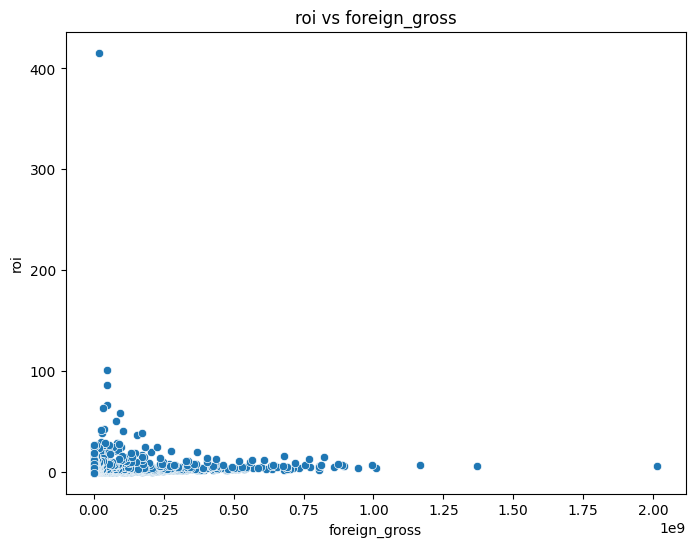

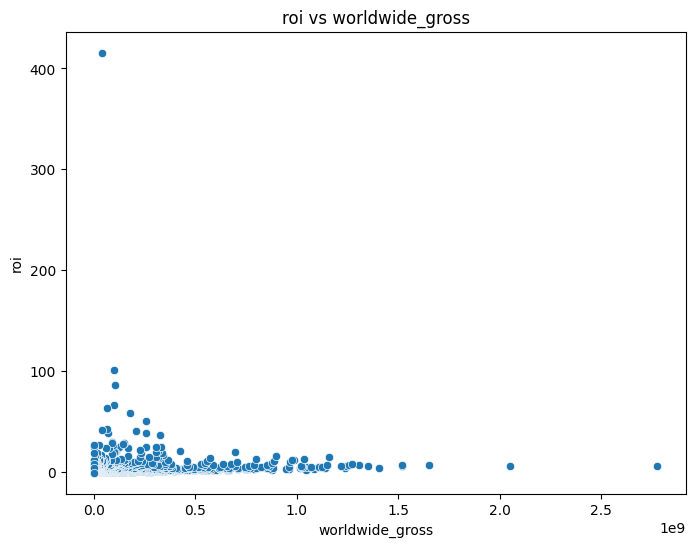

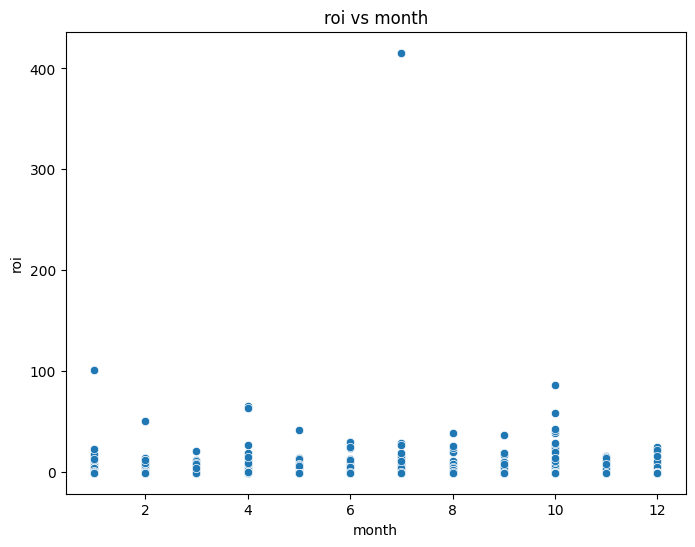

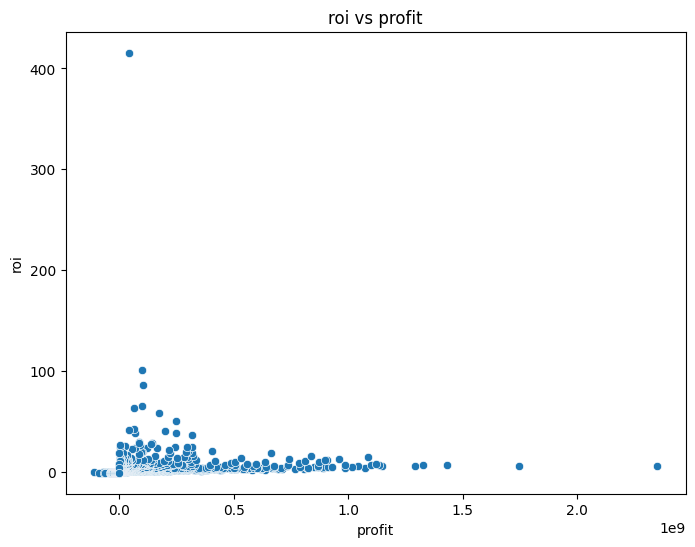

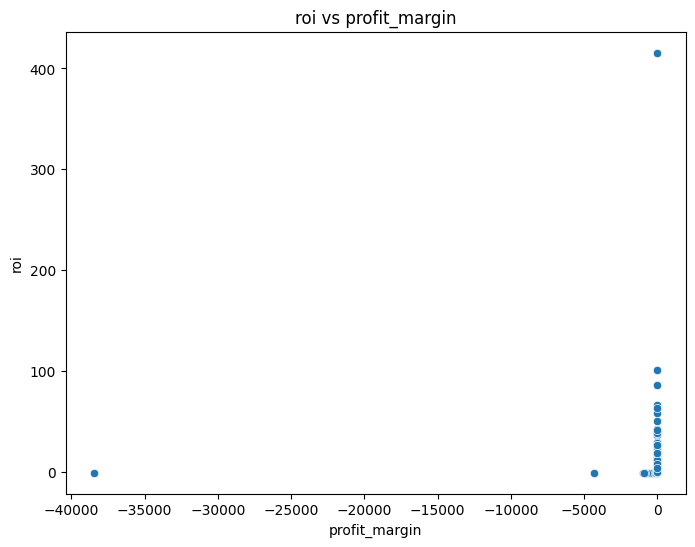

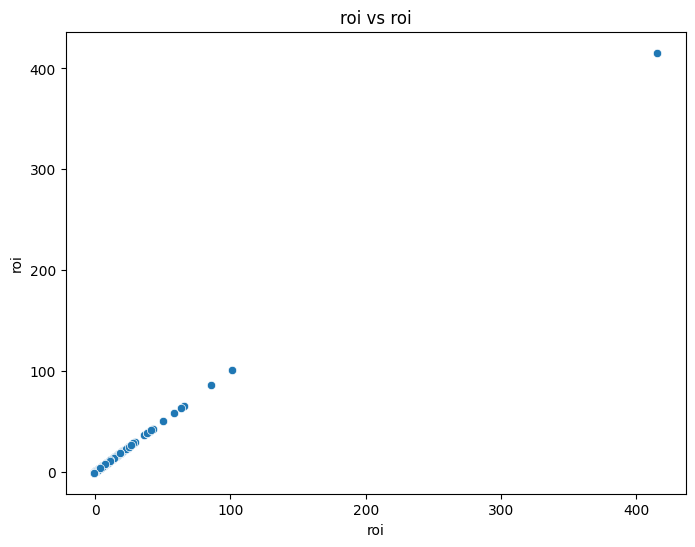

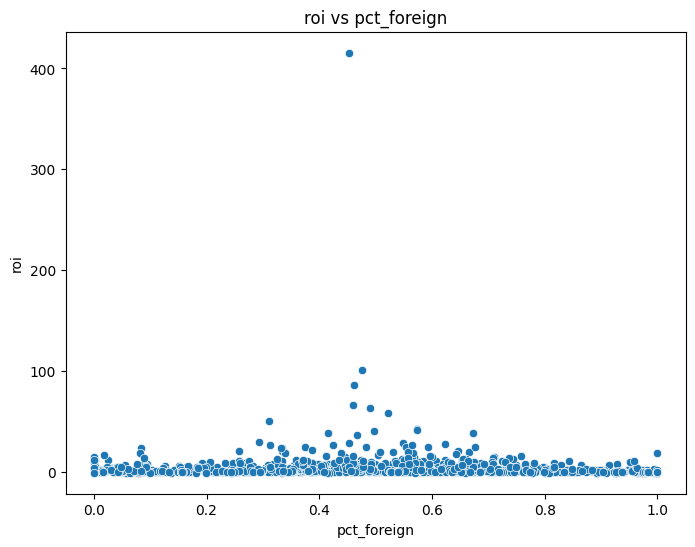

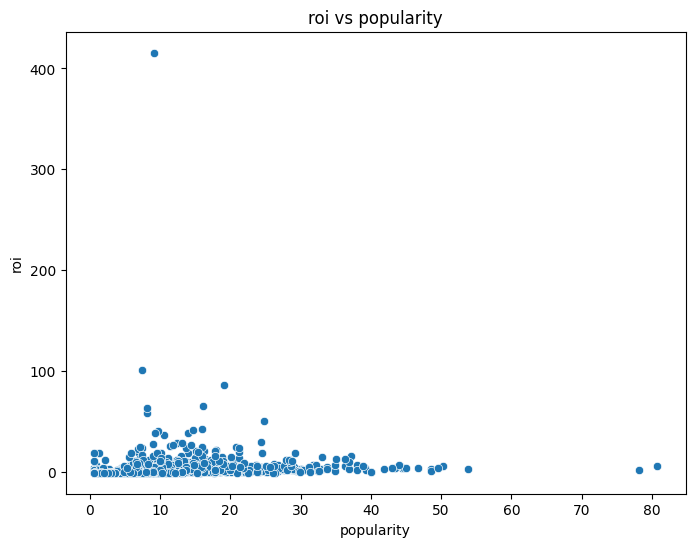

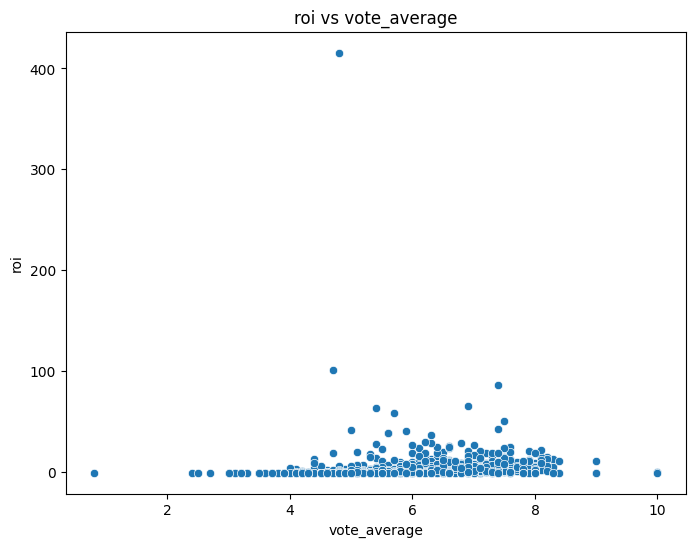

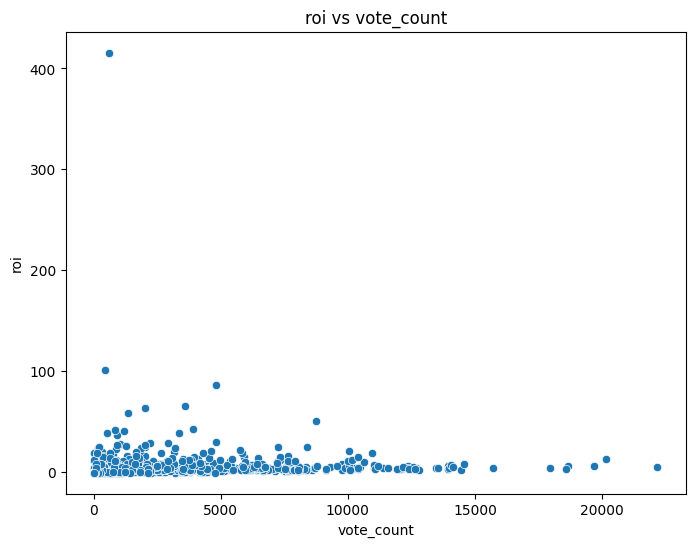

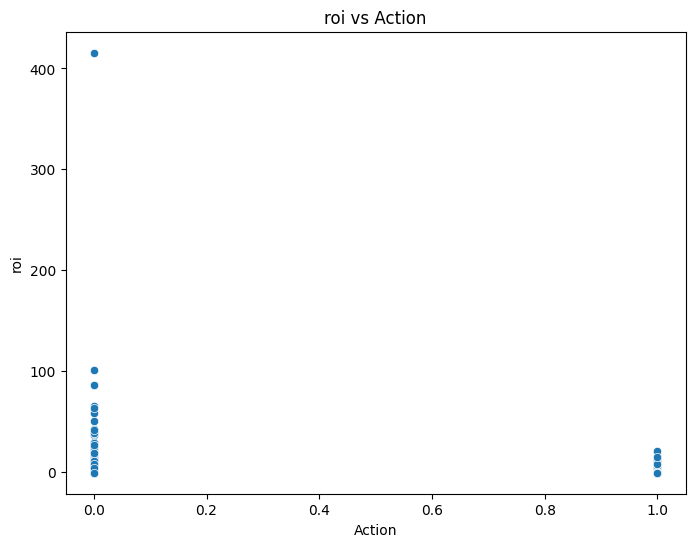

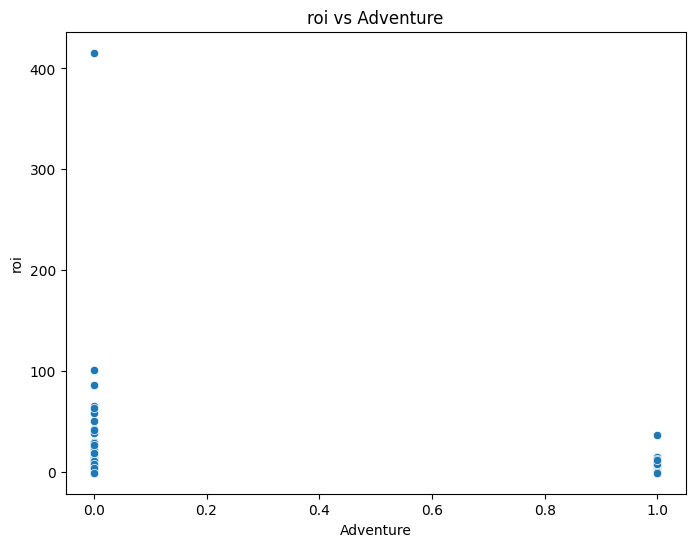

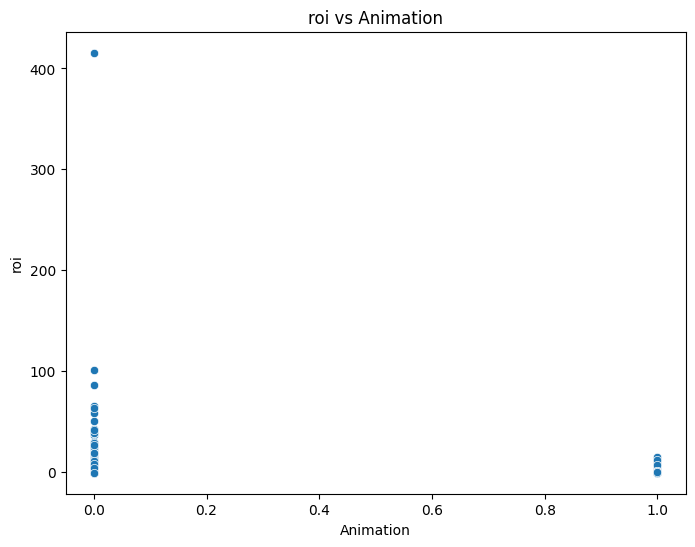

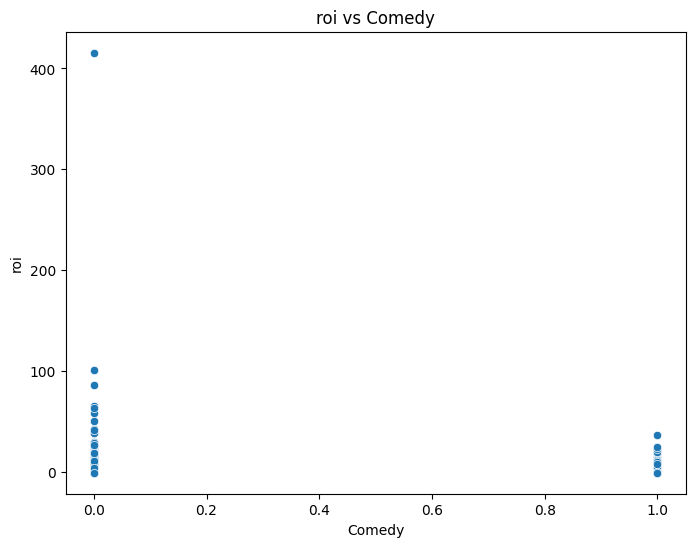

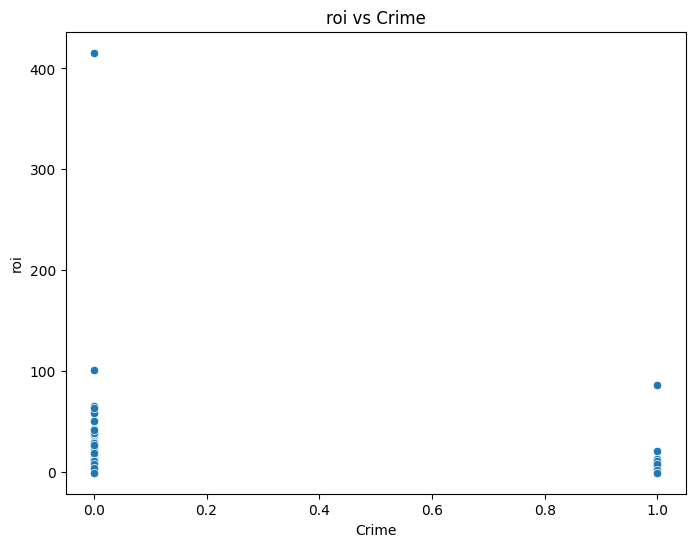

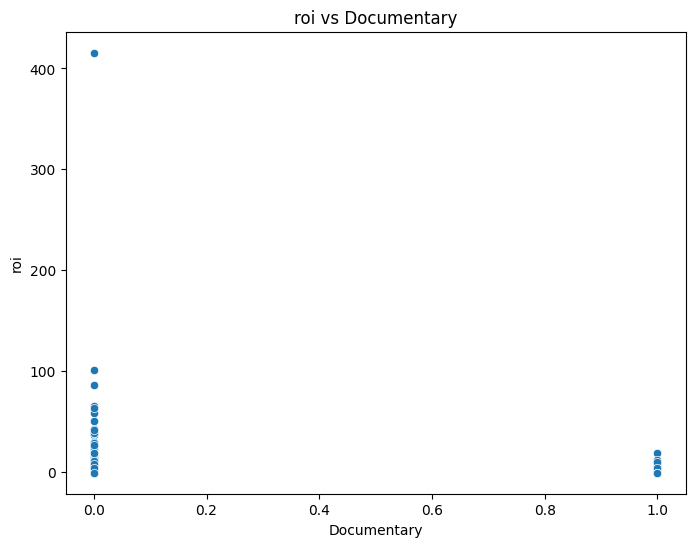

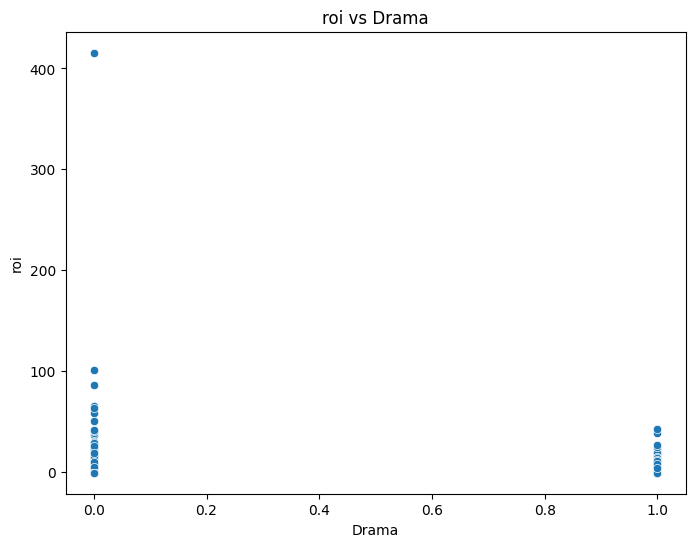

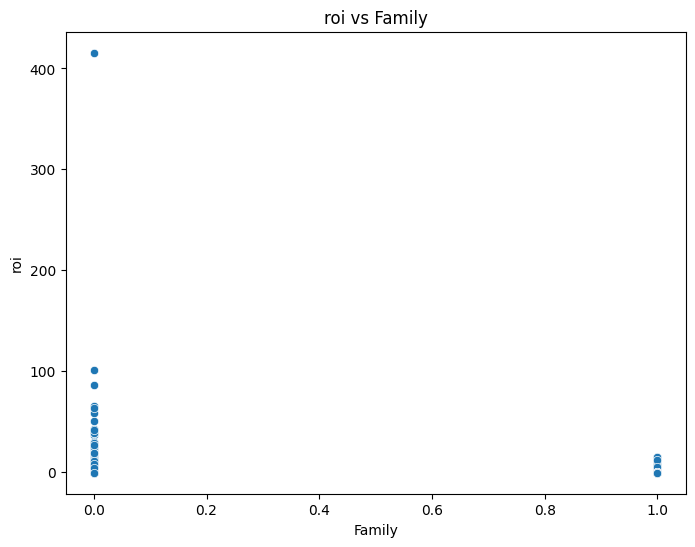

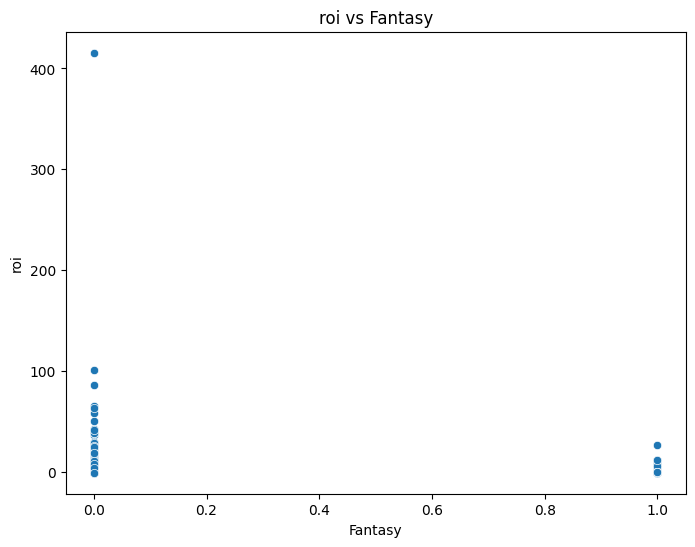

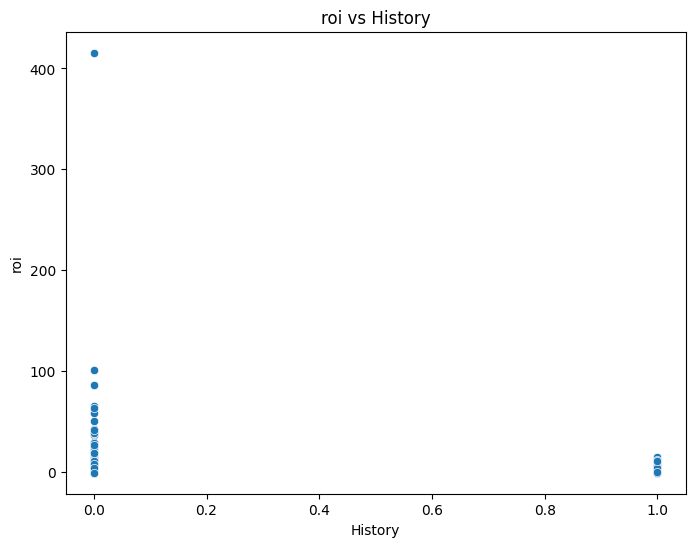

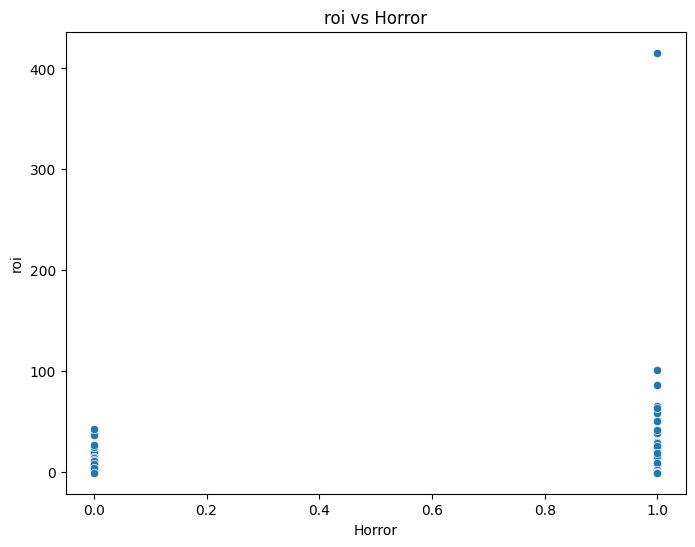

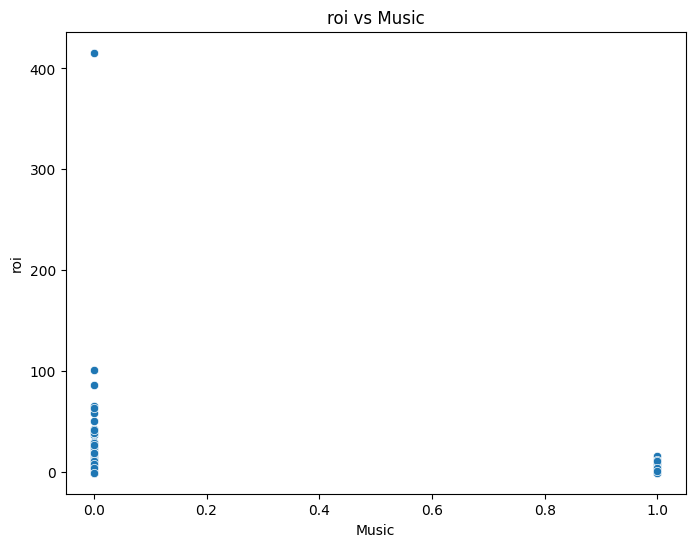

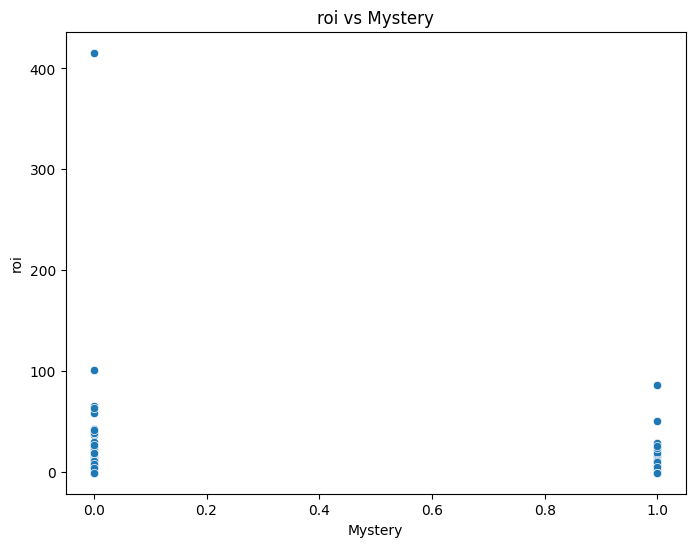

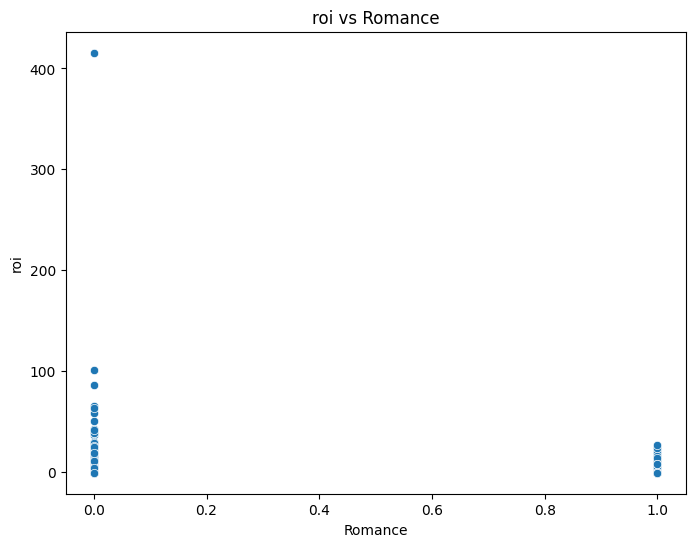

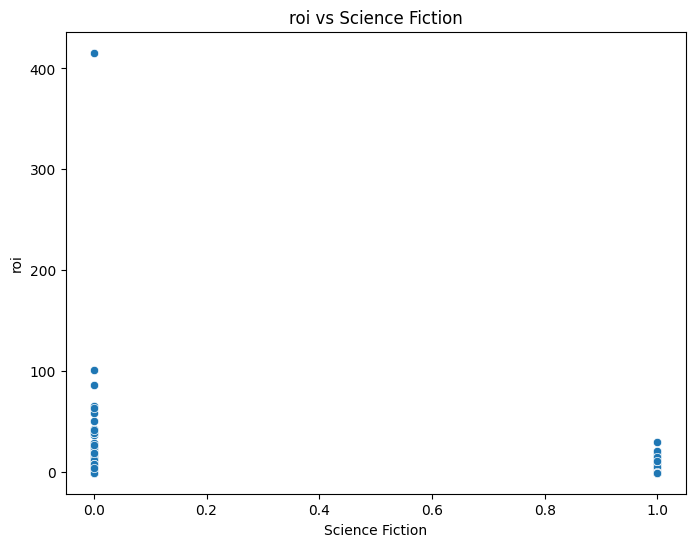

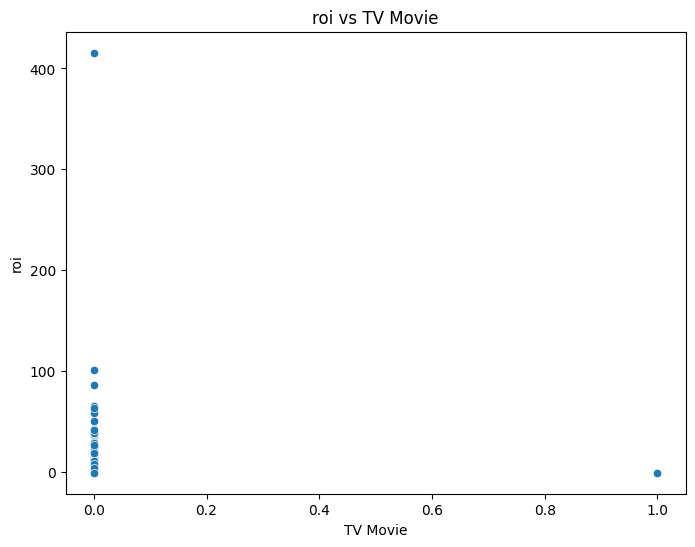

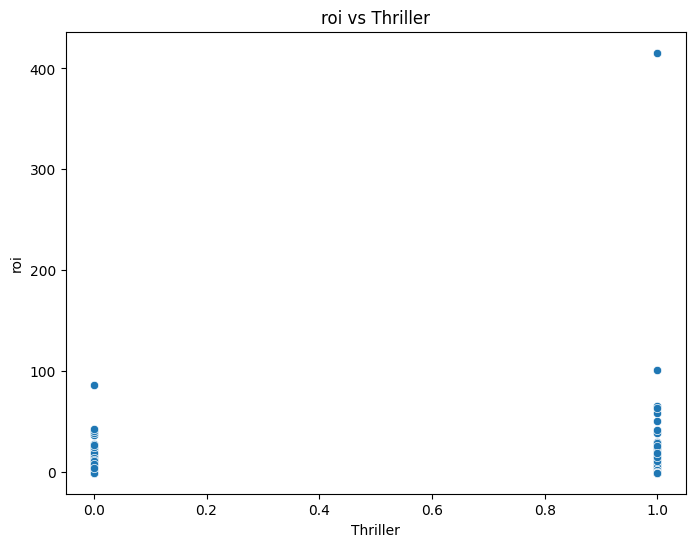

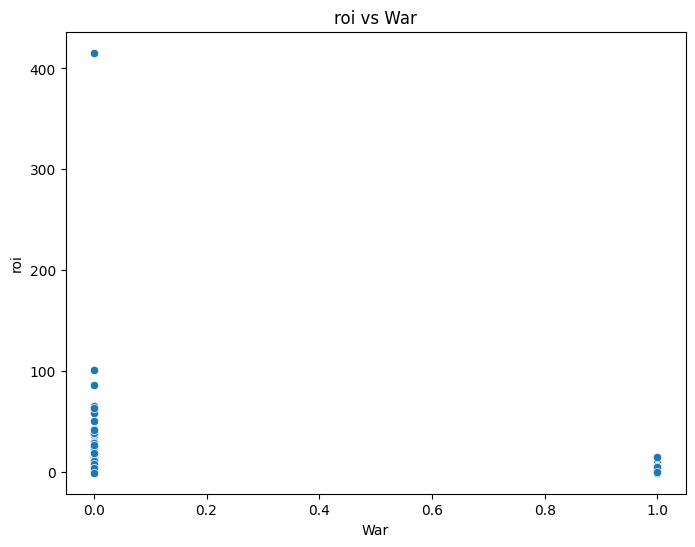

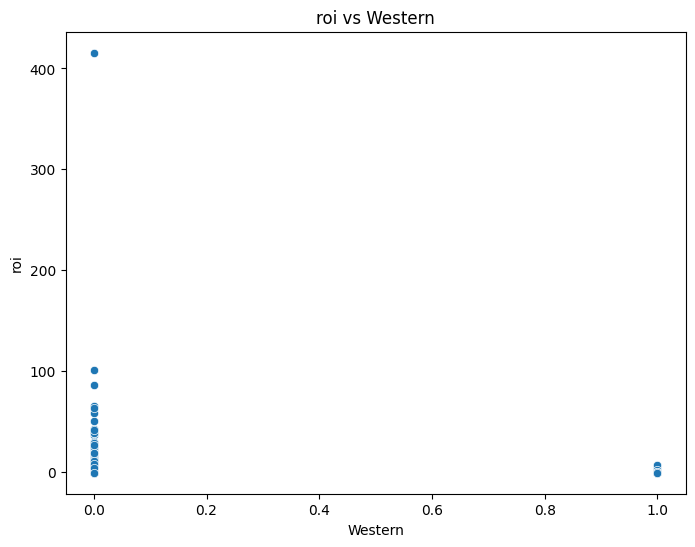

In [ ]:
for col in numerical_cols:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=df, x=col, y='roi')
    plt.xlabel(col)
    plt.ylabel('roi')
    plt.title(f'roi vs {col}')
    plt.show()

After analyzing the variables, we can observe that the relationship between revenue and profit is positive, meaning that they tend to increase together.

The relationship between budget and revenue, as well as between budget and profit, is also relatively strong.

Other findings are generally consistent with our initial expectations: when the production budget is higher, the film tends to have higher revenue. When revenue is higher, both profit and ROI also tend to be higher.

Relationship Between Profit, Gross Revenue, and ROI

Gross revenue, represented by the worldwide_gross variable, refers to the total worldwide revenue generated by a film.

Profit is calculated as:

Profit = Total Revenue − Production Budget

ROI (Return on Investment) is calculated as:

ROI = Profit / Production Budget

Based on these relationships, we can see that Profit and ROI are two important indicators for investors and film producers when evaluating whether to invest in a film project.

A higher ROI indicates that the investment generates a greater return relative to the initial production budget, which can make the project more attractive to investors and producers. Profit represents the amount earned after recovering the initial production cost.

Therefore, we can build a prediction model using either Profit or ROI as the target variable.

Since our objective is to convince investors to invest in film projects, we need to provide initial estimates of revenue, profit, and ROI based on factors such as film genre and release timing during the year.

To obtain more representative predictions of profit and ROI, we should exclude the -inf values from the dataset. This allows us to build a general prediction model based on films with valid financial outcomes.

In [ ]:
count_less_than_2010 = df_2[df_2['year'] < 2010].shape[0]

print(f"Number of rows where 'year' is less than 2010: {count_less_than_2010}")

Number of rows where 'year' is less than 2010: 51


As audience preferences and film production trends continue to evolve over time, we will exclude films released before 2010 from the analysis.

This allows us to focus on more recent films and examine how film genres and production budgets are associated with their financial performance, providing more relevant insights to support investment decisions in film projects.

In [ ]:
df_2 = df_2[df_2['year'] >= 2010]
df_2

,movie,year,production_budget,domestic_gross,foreign_gross,worldwide_gross,month,profit,profit_margin,roi,...,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
1,Pirates of the Caribbean: On Stranger Tides,2011,410600000,241063875,804600000,1045663875,5,635063875,0.607331,1.546673,...,0,0,0,0,0,0,0,0,0,0
2,Avengers: Age of Ultron,2015,330600000,459005868,944008095,1403013963,5,1072413963,0.764364,3.243841,...,0,0,0,0,0,1,0,0,0,0
3,Avengers: Infinity War,2018,300000000,678815482,1369318718,2048134200,4,1748134200,0.853525,5.827114,...,0,0,0,0,0,0,0,0,0,0
4,Justice League,2017,300000000,229024295,426920914,655945209,11,355945209,0.542645,1.186484,...,0,0,0,0,0,1,0,0,0,0
6,Spectre,2015,300000000,200074175,679546748,879620923,11,579620923,0.658944,1.932070,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1746,Tiny Furniture,2010,50000,391674,32475,424149,11,374149,0.882117,7.482980,...,0,0,0,0,1,0,0,0,0,0
1747,Counting,2015,50000,8374,0,8374,7,-41626,-4.970862,-0.832520,...,0,0,0,0,0,0,0,0,0,0
1752,Raymond Did It,2011,40000,3632,0,3632,2,-36368,-10.013216,-0.909200,...,0,1,0,0,0,0,0,0,0,0
1755,Krisha,2016,30000,144822,0,144822,3,114822,0.792849,3.827400,...,0,0,0,0,0,0,0,0,0,0


# IV. ANALYSIS



## The Impact of Budget on Profit, ROI, and Popularity

The production budget is one of the initial factors that can influence investment decisions. Different film segments require different levels of investment, and the amount of initial capital required to attract investors may vary depending on the budget range.

For this analysis, we will use df_2, after removing duplicate records, unnecessary values such as -inf, and films released before 2010.


In [ ]:
df_2['production_budget'].describe()

,production_budget
count,1.462000e+03
mean,4.498170e+07
std,5.537020e+07
min,2.500000e+04
25%,9.000000e+06
50%,2.500000e+07
75%,5.717500e+07
max,4.106000e+08


<Axes: >

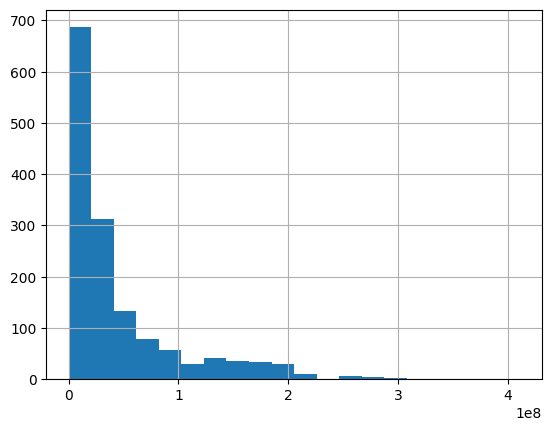

In [ ]:
df_2['production_budget'].hist(bins=20)

<Axes: >

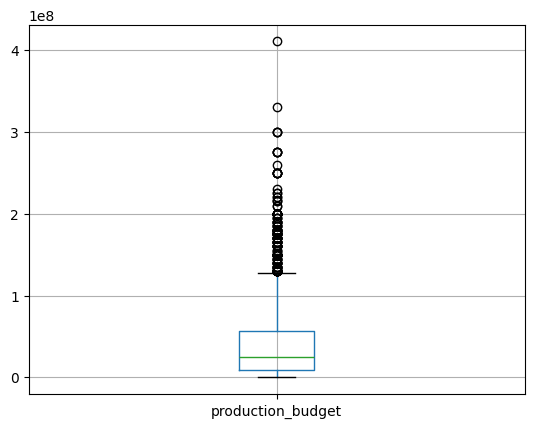

In [ ]:
df_2.boxplot(column='production_budget')

In [ ]:
q1, q2, q3, q4 = np.percentile(df_2['production_budget'], [25, 50, 75, 100])
iqr = q3 - q1

print("Interquartile range:", iqr)
print("First Quartile:", q1)
print("Second Quartile:", q2)
print("Third Quartile:", q3)
print("Fourth Quartile:", q4)

Interquartile range: 48175000.0
First Quartile: 9000000.0
Second Quartile: 25000000.0
Third Quartile: 57175000.0
Fourth Quartile: 410600000.0


The chart above shows a highly skewed distribution, with most films having a moderate production budget, while a smaller number of films have significantly higher budgets.

In addition, when comparing budget with vote_count and popularity, we can observe a potential positive relationship: as the production budget increases, both vote_count and popularity tend to increase to some extent. This may be partly related to the fact that higher-budget films generally have greater resources available for marketing and promotion, which can increase audience exposure and engagement.


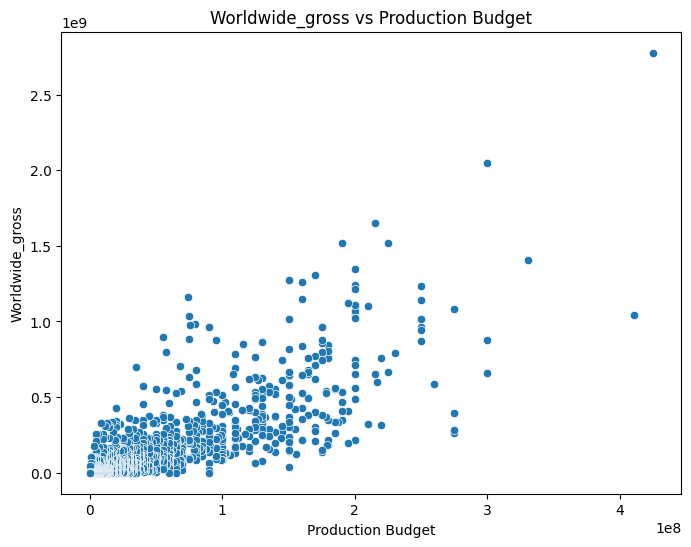

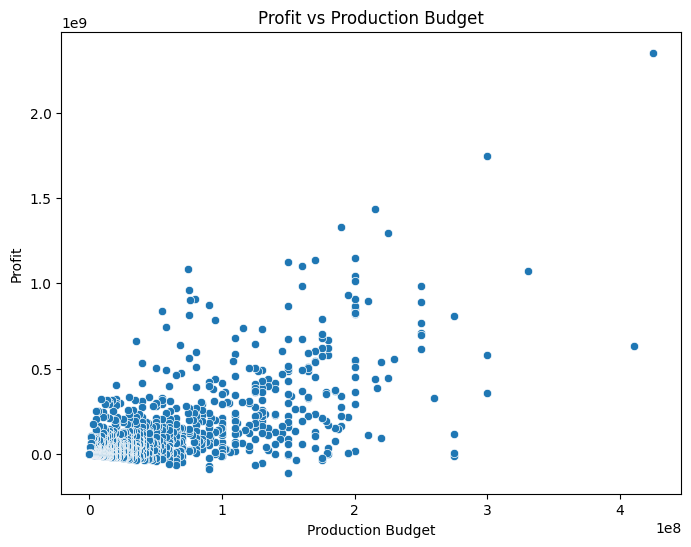

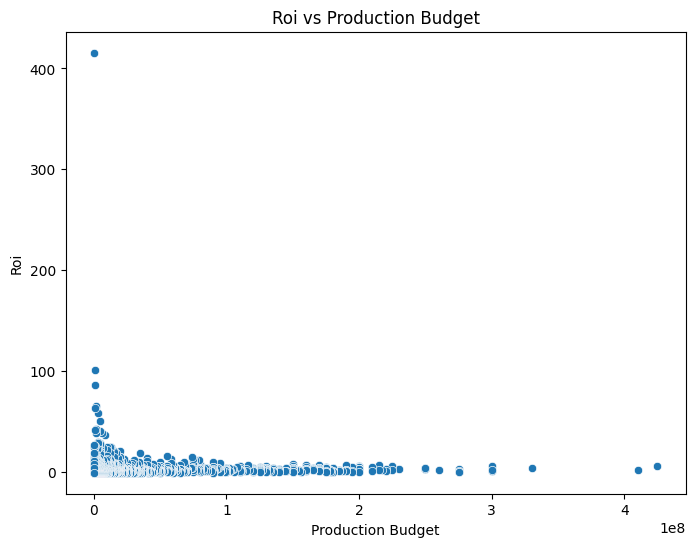

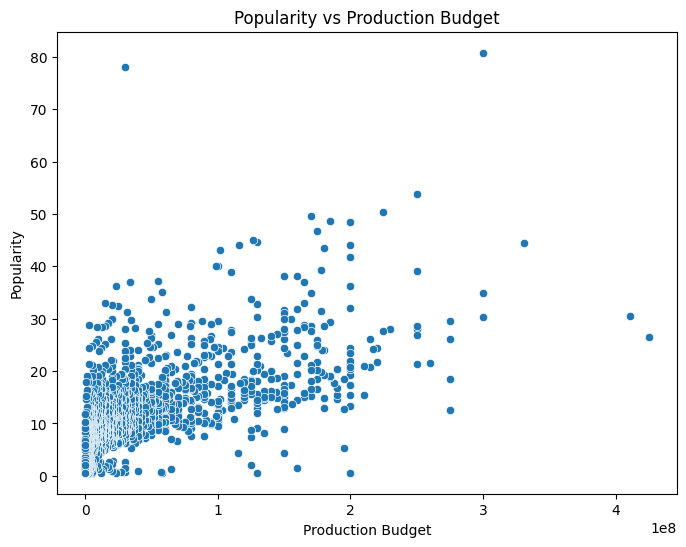

In [ ]:
for col in numerical_cols:
    if col in ['popularity', 'roi', 'profit', 'worldwide_gross']:
      plt.figure(figsize=(8, 6))
      sns.scatterplot(data=df, x='production_budget', y=col)
      plt.xlabel('Production Budget')
      plt.ylabel(col.capitalize())
      plt.title(f'{col.capitalize()} vs Production Budget')
      plt.show()

Based on the charts above, we can observe that **production budget** has a positive relationship with several key variables, including **popularity, profit, and worldwide gross revenue**.

This suggests that films with higher initial production funding tend to have better financial performance and greater audience engagement.

One possible explanation is that a larger production budget provides more resources for factors that can contribute to a film's performance, such as **actor salaries, marketing and promotional activities, production quality, and distribution**. These additional resources may create greater opportunities to attract audiences and generate stronger awareness and engagement before the film's release.

However, this should be interpreted as a **positive association rather than a causal relationship**, as other factors may also influence a film's popularity and financial performance.




## Analyze revenue by season and month

In [ ]:
season = pd.DataFrame()

season['month'] = list(set(df_2['month']))
season['month_str'] = [datetime.datetime.strptime(str(month), "%m").strftime("%b")
                       for month in season['month']]
season['avg_dom_gross'] = [(df_2['domestic_gross'][df_2['month']==month].mean())
                                for month in season['month']]
season['avg_fn_gross'] = [(df_2['foreign_gross'][df_2['month']==month].mean())
                                for month in season['month']]
season['avg_ww_gross'] = [(df_2['worldwide_gross'][df_2['month']==month].mean())
                                for month in season['month']]
season['avg_budget'] = [(df_2['production_budget'][df_2['month']==month].mean())
                                for month in season['month']]
season['roi'] = [(df_2['roi'][df_2['month']==month].median())
                                for month in season['month']]
season['pct_foreign'] = [(df_2['pct_foreign'][df_2['month']==month].mean())
                                for month in season['month']]

season = season.sort_values('month')

In [ ]:
season

,month,month_str,avg_dom_gross,avg_fn_gross,avg_ww_gross,avg_budget,roi,pct_foreign
0,1,Jan,3.858362e+07,5.025821e+07,8.884183e+07,3.480494e+07,1.383301,0.466883
1,2,Feb,5.601479e+07,6.888159e+07,1.248964e+08,4.089950e+07,1.312788,0.472813
2,3,Mar,6.227237e+07,9.073882e+07,1.530112e+08,5.410961e+07,1.160763,0.441851
3,4,Apr,4.398053e+07,7.204750e+07,1.160280e+08,3.198126e+07,0.801742,0.440023
4,5,May,9.017801e+07,1.543003e+08,2.444783e+08,7.582881e+07,1.587309,0.498849
5,6,Jun,9.025691e+07,1.416907e+08,2.319476e+08,6.231008e+07,1.335259,0.485721
6,7,Jul,7.383044e+07,1.218508e+08,1.956813e+08,5.615975e+07,1.738794,0.529194
7,8,Aug,4.162185e+07,4.836631e+07,8.998815e+07,3.332727e+07,1.050663,0.435779
8,9,Sep,3.215068e+07,3.909364e+07,7.124432e+07,2.681451e+07,0.838612,0.469522
9,10,Oct,3.109949e+07,4.727931e+07,7.837880e+07,2.625764e+07,0.635236,0.504784


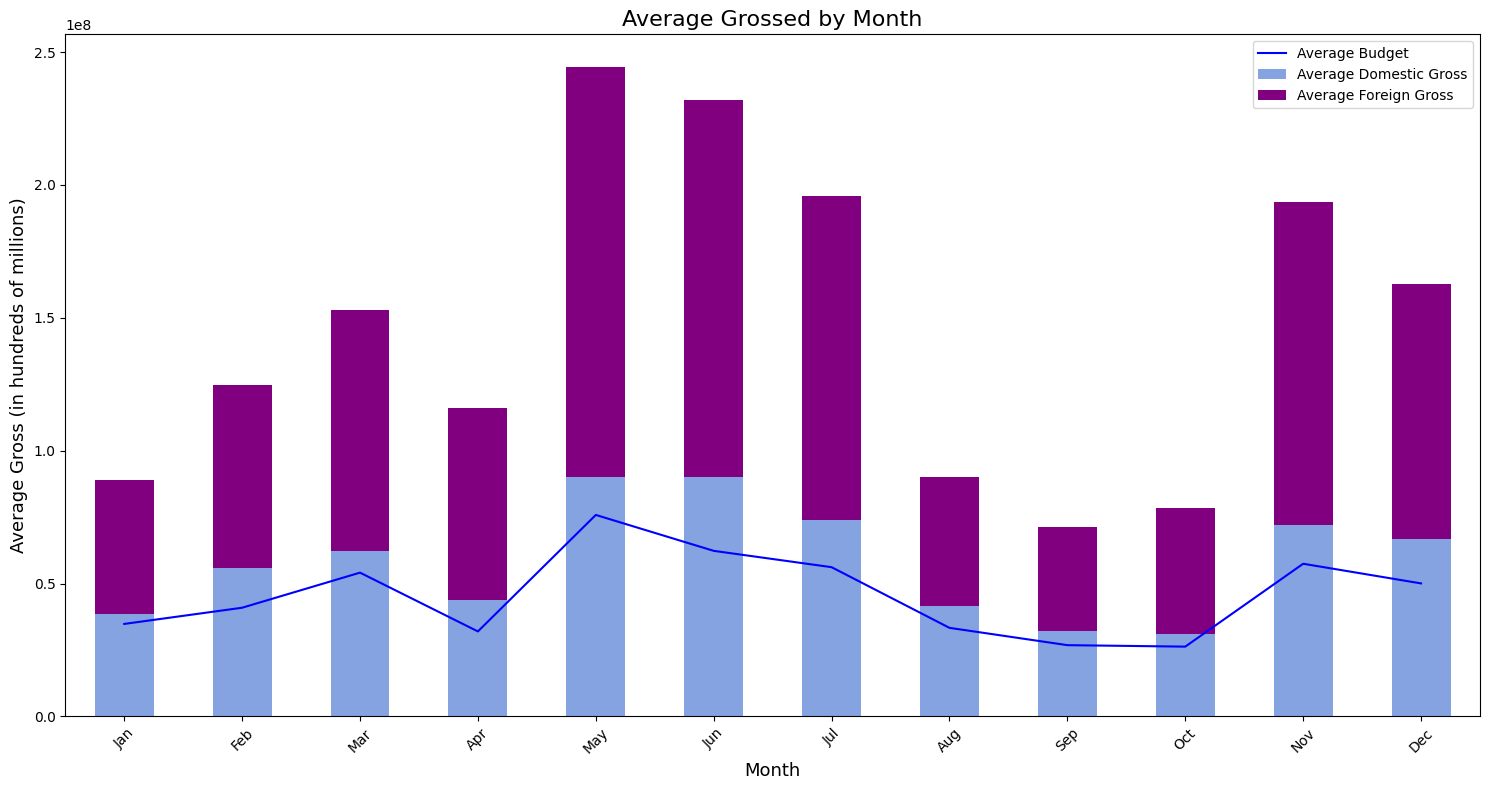

In [ ]:
ax = season[['month_str', 'avg_dom_gross', 'avg_fn_gross']].plot(x='month_str', kind='bar',
                                                                 figsize=(15,8), stacked=True,
                                                                 color=[(0.2, 0.4, 0.8, 0.6), 'purple'])
season.plot(y='avg_budget', x='month_str', ax=ax, color='blue')
plt.xlabel('Month', fontsize=13)
plt.xticks(rotation = 45)
plt.ylabel('Average Gross (in hundreds of millions)', fontsize=13)
plt.title('Average Grossed by Month', fontsize=16)
plt.legend(labels=['Average Budget', 'Average Domestic Gross', 'Average Foreign Gross'])
plt.tight_layout()
plt.savefig("seasons.png", format='png',dpi=150)

## Analyze ROI by season and month

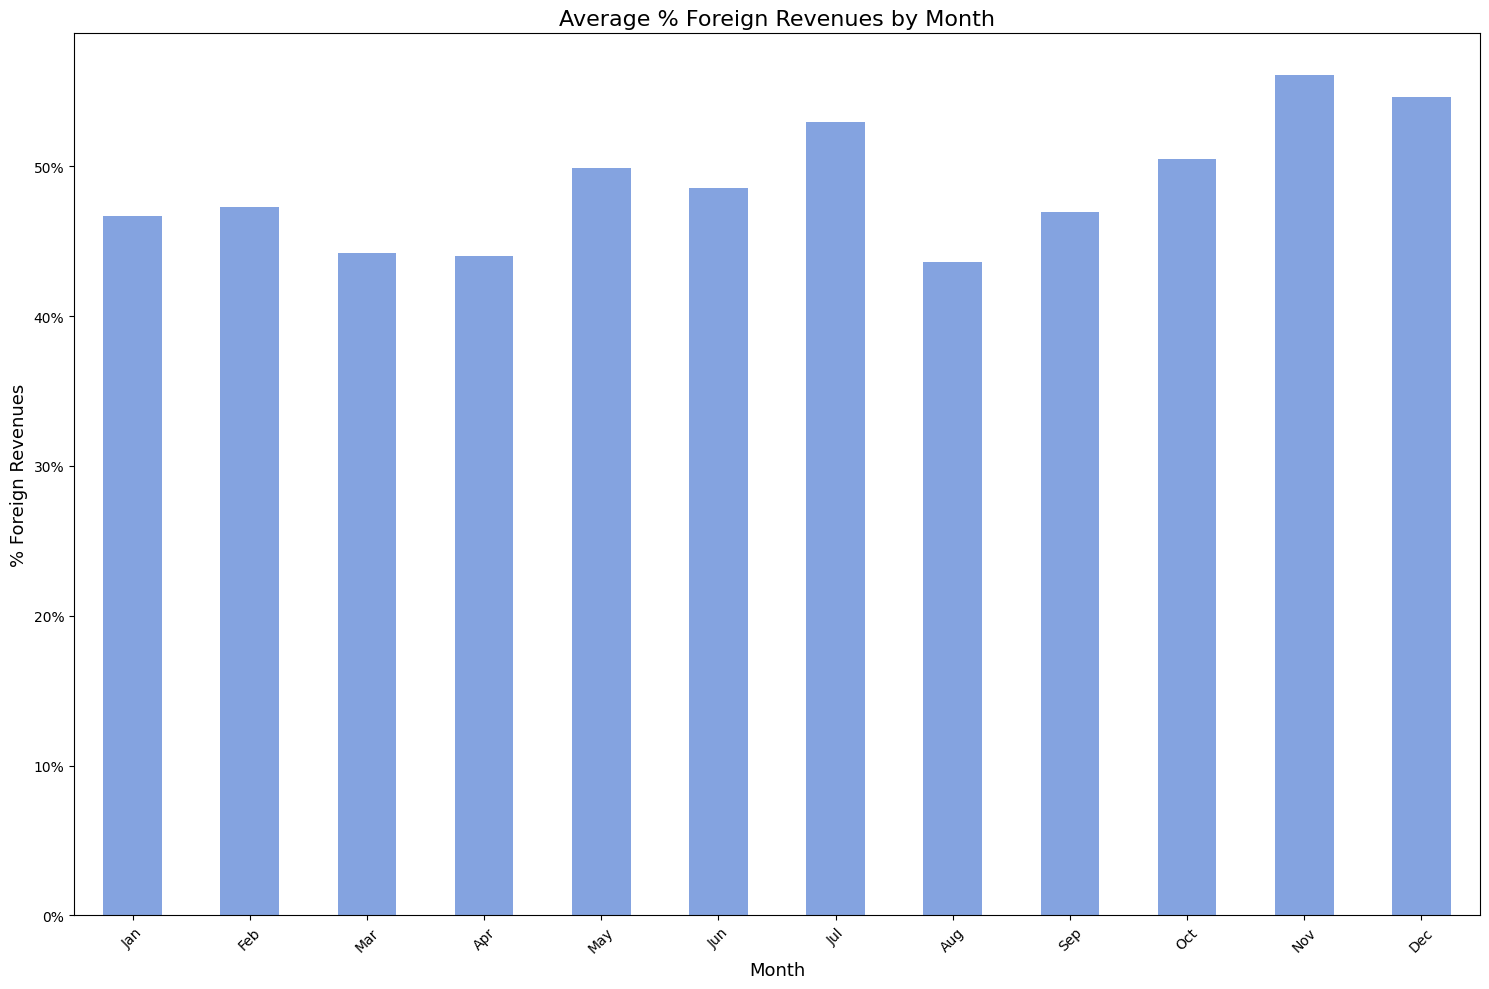

In [ ]:
import matplotlib.ticker as mtick

ax = season[['month_str', 'pct_foreign']].plot(x='month_str', kind='bar', figsize=(15,10), color=(0.2, 0.4, 0.8, 0.6))
plt.xlabel('Month', fontsize=13)
plt.ylabel('% Foreign Revenues', fontsize=13)
plt.title('Average % Foreign Revenues by Month', fontsize=16)
plt.xticks(rotation = 45)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.get_legend().remove()
plt.tight_layout()
plt.savefig("seasons3.png", format='png',dpi=150)


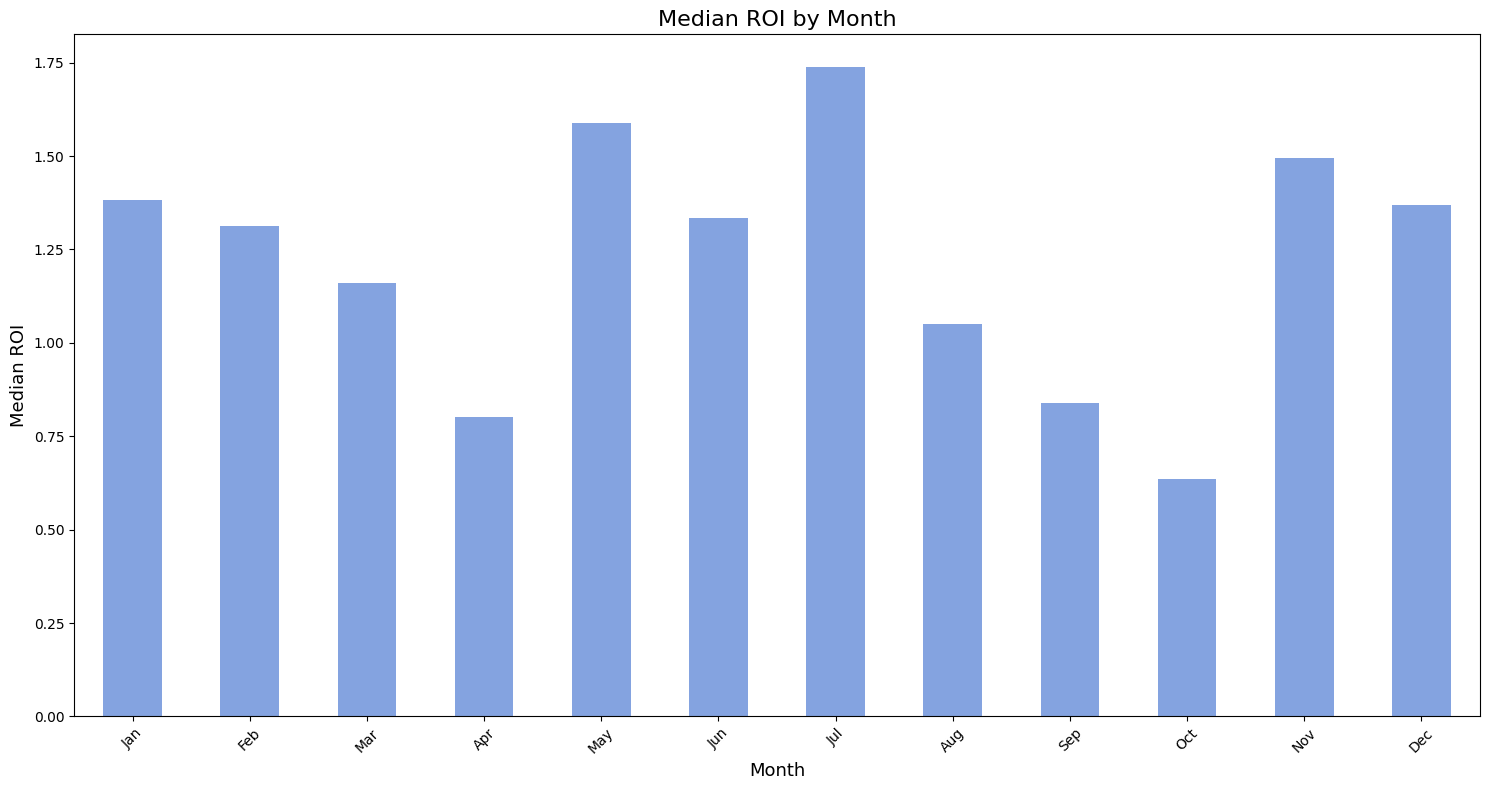

In [ ]:
ax = season[['month_str', 'roi']].plot(x='month_str', kind='bar', figsize=(15,8), color=(0.2, 0.4, 0.8, 0.6))
plt.xlabel('Month', fontsize=13)
plt.ylabel('Median ROI', fontsize=13)
plt.title('Median ROI by Month', fontsize=16)
plt.legend(labels=['ROI'])
plt.xticks(rotation = 45)
ax.get_legend().remove()
plt.tight_layout()
plt.savefig("seasons2.png", format='png',dpi=150)

### Consistent with the current film market, high-budget films with extensive marketing campaigns tend to be concentrated around mid-year and year-end release periods.

Higher marketing investment, supported by larger production budgets, may help maintain strong audience awareness and exposure both before and after the film's release.

The average ROI by season also shows relatively similar patterns during these periods.

Therefore, release timing can be considered a factor for investors when evaluating film projects. Investors may consider the expected release period to identify opportunities for higher potential returns while also assessing the level of risk associated with investing in a particular film project.


## How Do Film Genres Affect Key Variables?




In [ ]:
print("Movies with more than one genre: " + str(len(df_2[df_2['genre_list'].str.len() > 1])))
print("Movies with one genre: " + str(len(df_2[df_2['genre_list'].str.len() == 1])))
print("Movies with no genre: " + str(len(df_2[df_2['genre_list'].str.len() == 0])))

Movies with more than one genre: 1462
Movies with one genre: 0
Movies with no genre: 0


### Try Create a DataFrame summarizing information about film genres, along with the budget, profit, and ROI of each genre.

This can be created using code or Excel.

Use the df_2 dataset to build it.

In [ ]:
link = 'https://drive.google.com/file/d/1brezr_Nlwao_AO5QyrvFKmN3M1bckETb/view?usp=sharing'
path = 'https://drive.google.com/uc?export=download&id='+link.split('/')[-2]
df_2_genres = pd.read_csv(path)

In [ ]:
df_2_genres

,Genres,Count,Sum _Production_Budget,Avg_Production_Budget,Sum_Worldwide_Gross,Avg_Worldwide_Gross,Sum_Profit,Avg_Profit,Avg _roi,Avg_Popularity,Avg_pct_foreign
0,Horror,169,3387895000,2.004672e+07,1.333093e+10,7.888124e+07,9943034089,5.883452e+07,9.714851,11.975911,0.534023
1,Thriller,410,14449232650,3.524203e+07,4.241548e+10,1.034524e+08,27966244572,6.821035e+07,4.467253,13.481954,0.541078
2,Mystery,110,3333427650,3.030389e+07,1.004560e+10,9.132360e+07,6712168360,6.101971e+07,3.693693,13.408236,0.544557
3,Documentary,25,318325000,1.273300e+07,9.540536e+08,3.816214e+07,635728625,2.542914e+07,2.867927,4.469520,0.254024
4,Romance,191,5244615000,2.745872e+07,1.726709e+10,9.040360e+07,12022472933,6.294488e+07,2.746861,10.820885,0.474363
5,Animation,99,9629500000,9.726768e+07,3.741408e+10,3.779200e+08,27784579744,2.806523e+08,2.722340,15.627051,0.618449
6,Science Fiction,184,16404825000,8.915666e+07,5.402737e+10,2.936270e+08,37622548053,2.044704e+08,2.517788,18.410750,0.583627
7,Family,166,14359000000,8.650000e+07,5.032524e+10,3.031641e+08,35966243276,2.166641e+08,2.381846,14.506765,0.558090
8,Comedy,491,19754465000,4.023313e+07,6.698453e+10,1.364247e+08,47230066624,9.619158e+07,2.342793,12.010745,0.434462
9,Music,42,1107400000,2.636667e+07,3.651778e+09,8.694710e+07,2544378236,6.058043e+07,2.293839,10.040000,0.330722


In [ ]:
df_2_genres.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Genres                  18 non-null     object 
 1   Count                   18 non-null     int64  
 2   Sum _Production_Budget  18 non-null     int64  
 3   Avg_Production_Budget   18 non-null     float64
 4   Sum_Worldwide_Gross     18 non-null     float64
 5   Avg_Worldwide_Gross     18 non-null     float64
 6   Sum_Profit              18 non-null     int64  
 7   Avg_Profit              18 non-null     float64
 8   Avg _roi                18 non-null     float64
 9   Avg_Popularity          18 non-null     float64
 10  Avg_pct_foreign         18 non-null     float64
dtypes: float64(7), int64(3), object(1)
memory usage: 1.7+ KB


In [ ]:
df_2_genres.describe()

,Count,Sum _Production_Budget,Avg_Production_Budget,Sum_Worldwide_Gross,Avg_Worldwide_Gross,Sum_Profit,Avg_Profit,Avg _roi,Avg_Popularity,Avg_pct_foreign
count,18.000000,1.800000e+01,1.800000e+01,1.800000e+01,1.800000e+01,1.800000e+01,1.800000e+01,18.000000,18.000000,18.000000
mean,207.888889,1.108360e+10,5.350726e+07,3.547508e+10,1.690095e+08,2.439146e+10,1.155022e+08,2.695206,13.443892,0.508027
std,183.603758,1.008484e+10,3.270384e+07,3.264686e+10,1.178103e+08,2.264725e+10,8.618536e+07,1.968521,3.563204,0.096339
min,18.000000,3.183250e+08,1.273300e+07,9.540536e+08,3.816214e+07,6.357286e+08,2.542914e+07,0.657305,4.469520,0.254024
25%,72.000000,2.285957e+09,2.821618e+07,6.307368e+09,8.781123e+07,4.021411e+09,6.040911e+07,1.883372,11.958347,0.468074
50%,167.500000,8.575920e+09,3.785793e+07,2.886552e+10,1.079628e+08,2.028960e+10,6.643915e+07,2.318316,13.257201,0.532980
75%,255.500000,1.635383e+10,8.607796e+07,5.344161e+10,2.860258e+08,3.584555e+10,1.979554e+08,2.740731,15.346979,0.573723
max,701.000000,3.290700e+10,1.134922e+08,1.027080e+11,3.803984e+08,7.206467e+10,2.806523e+08,9.714851,18.990100,0.618449


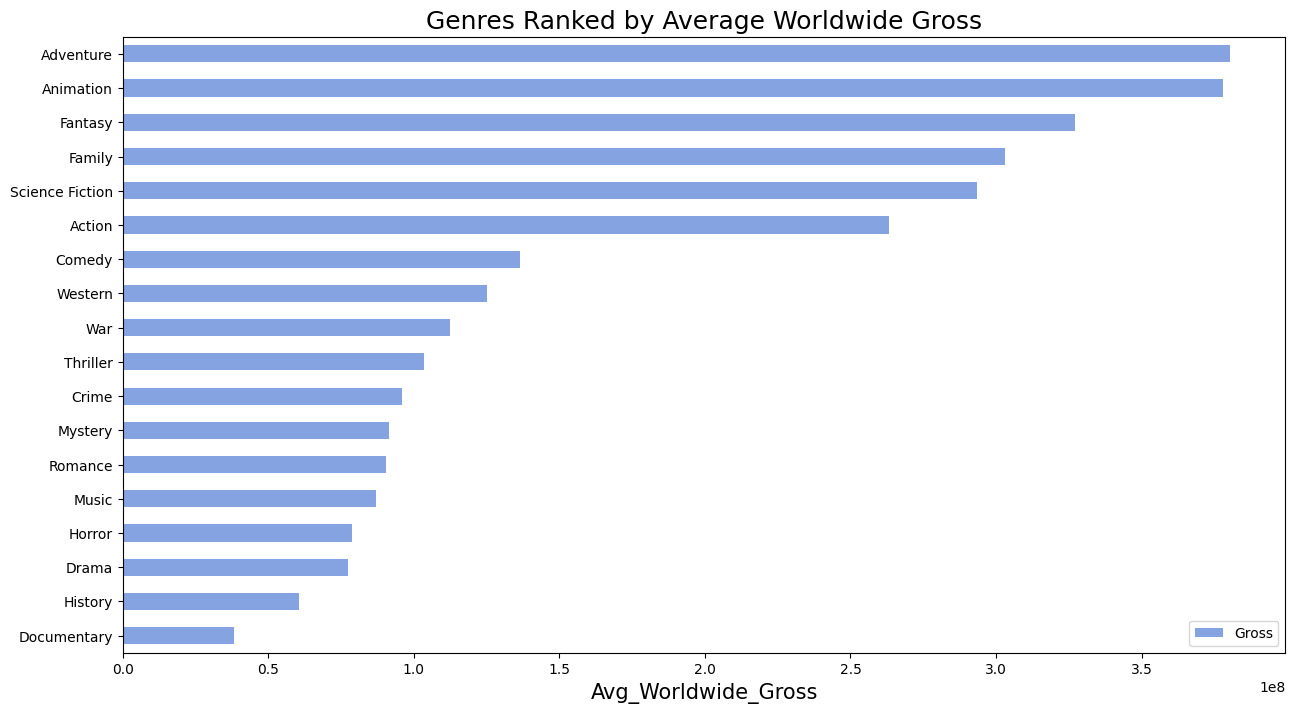

In [ ]:
# Genre ranked by ROI
df_2_genres[['Genres', 'Avg_Worldwide_Gross']].sort_values('Avg_Worldwide_Gross', ascending=True).plot(x='Genres', kind='barh', figsize=(15,8),
                                                                 stacked=True, color=(0.2, 0.4, 0.8, 0.6))
plt.xlabel('Avg_Worldwide_Gross', fontsize=15)
plt.ylabel('Genres', fontsize=15).set_visible(False)
plt.title('Genres Ranked by Average Worldwide Gross',fontsize=18)
plt.legend(labels=['Gross'])
plt.savefig("genres_AvgWorldGross.png", format='png',dpi=150)

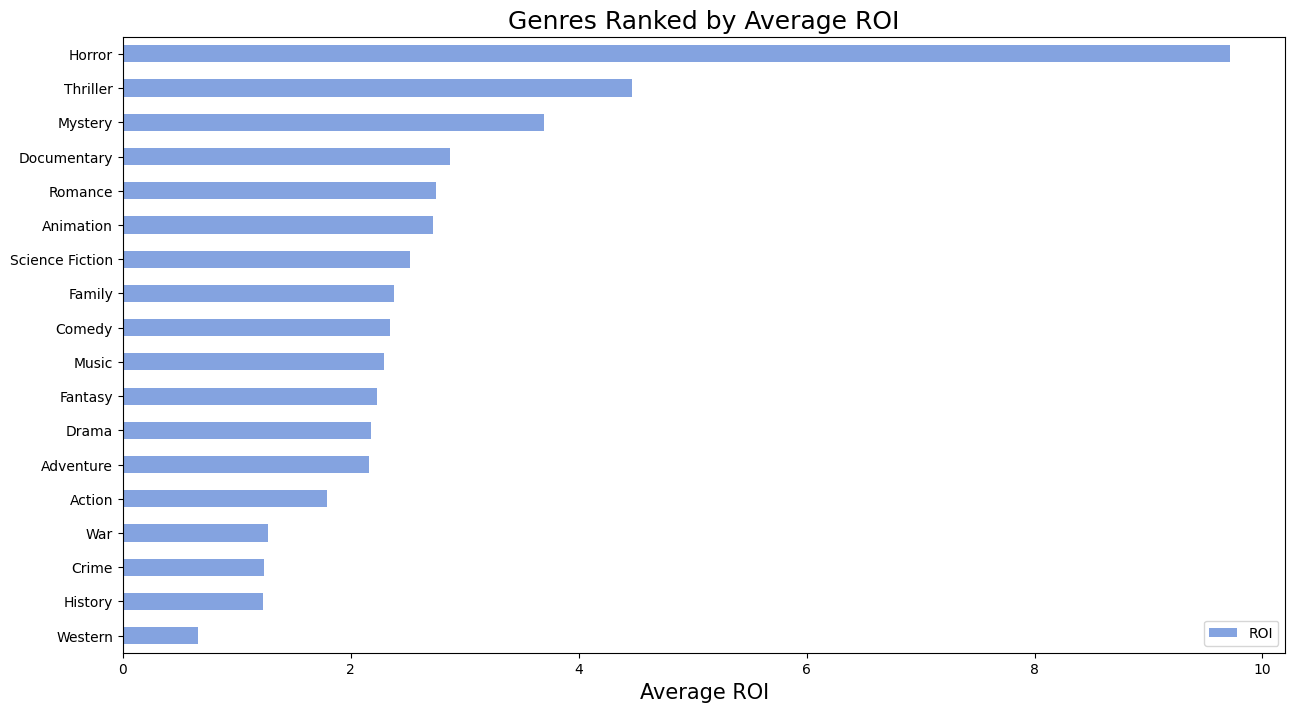

In [ ]:
# Genre ranked by ROI
df_2_genres[['Genres', 'Avg _roi']].sort_values('Avg _roi', ascending=True).plot(x='Genres', kind='barh', figsize=(15,8),
                                                                 stacked=True, color=(0.2, 0.4, 0.8, 0.6))
plt.xlabel('Average ROI', fontsize=15)
plt.ylabel('Genres', fontsize=15).set_visible(False)
plt.title('Genres Ranked by Average ROI',fontsize=18)
plt.legend(labels=['ROI'])
plt.savefig("genre_roi.png", format='png',dpi=150)

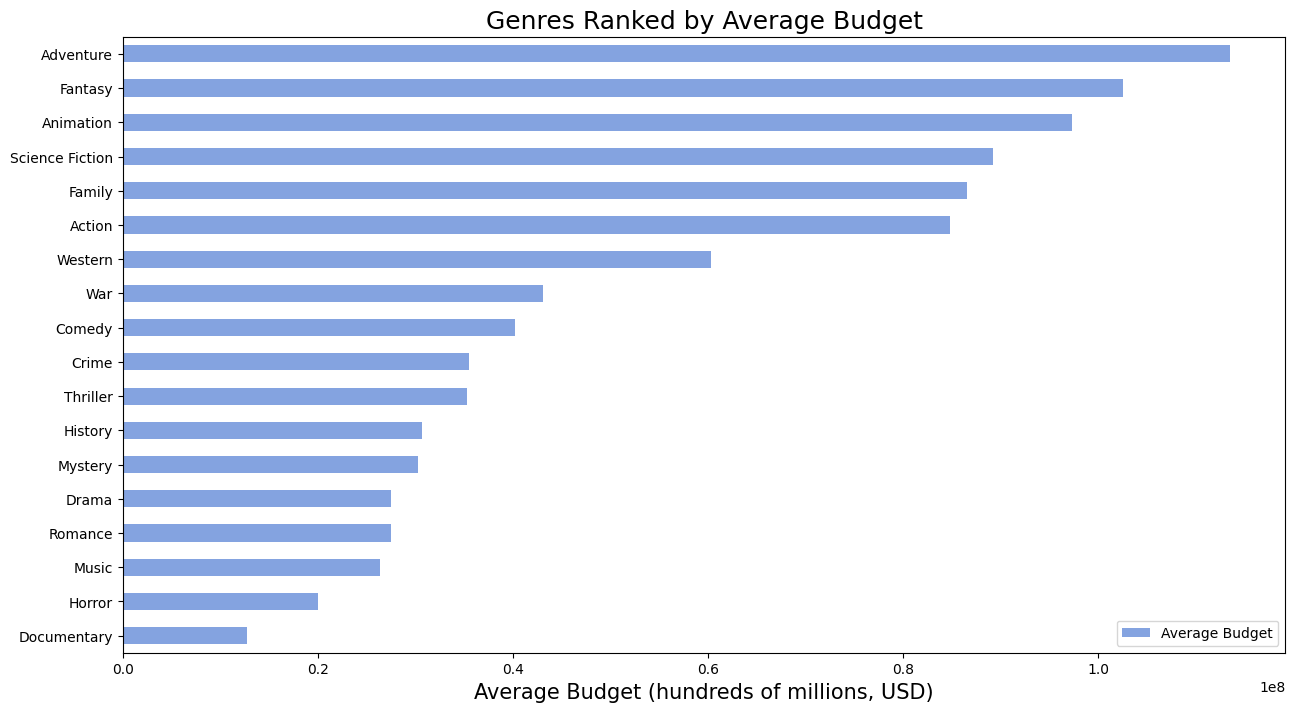

In [ ]:
df_2_genres[['Genres', 'Avg_Production_Budget']].sort_values('Avg_Production_Budget', ascending=True).plot(x='Genres', kind='barh',
                                                                               figsize=(15,8), stacked=True,
                                                                               color=(0.2, 0.4, 0.8, 0.6))
plt.ylabel('Genres', fontsize=15).set_visible(False)
plt.xlabel('Average Budget (hundreds of millions, USD)', fontsize=15)
plt.title('Genres Ranked by Average Budget',fontsize=18)
plt.legend(labels=['Average Budget'])
plt.savefig("genre_budget.png", format='png',dpi=150)

### Conclusion on Film Genres

The first important point about film genres is that modern films are not usually classified into only one genre. Instead, a film often belongs to at least two genres.

Based on the charts above, we can understand how film genres are associated with factors such as profit, production budget, and ROI (Return on Investment).

Genres such as Action, Adventure, Fantasy, Animation, Family, and Science Fiction generally have higher production budgets while also generating relatively high profits. The higher production costs can be attributed to expenses such as special effects, post-production, and marketing. These genres also tend to appeal to a broad audience, so higher investment in production and promotion may create greater opportunities to attract viewers and generate higher profits.

However, this pattern does not necessarily apply to genres such as Horror, Thriller, Mystery, Documentary, and Romance. These films often have much lower production costs, sometimes less than one-tenth of the budgets of the genres mentioned above, while still attracting a considerable audience.

For example, in the Horror genre, The Gallows had an initial production budget of approximately $100,000, but generated around $43 million in profit. This represents an exceptionally large return compared with its initial production cost.

Therefore, film genre is associated to some extent with production cost, profit, and ROI. These factors can provide useful information for investors when evaluating which types of film projects may be suitable for investment.



In [ ]:
# genres = pd.DataFrame()
# genres['genre'] = list(set([item for sublist in df_2['genre_list'] for item in sublist]))

# genres = genres[~genres['genre'].isnull()].reset_index(drop=True)

# genres['count'] = [sum(df_2[f'{genre}']) for genre in genres['genre']]

# genres['gross'] = [sum(df_2['worldwide_gross'][df_2[f'{genre}']==1])
#                    for genre in genres['genre']]
# genres['profit'] = [sum(df_2['profit'][df_2[f'{genre}']==1])
#                     for genre in genres['genre']]
# genres['avg_profit_per_movie'] = genres['profit'] / genres['count']
# genres['avg_budget'] = [df_2['production_budget'][df_2[f'{genre}']==1].mean()
#                         for genre in genres['genre']]
# genres['roi'] = [df_2['roi'][df_2[f'{genre}']==1].mean() for genre in genres['genre']]
# genres['pct_foreign'] = [df_2['pct_foreign'][df_2[f'{genre}']==1].mean()
#                          for genre in genres['genre']]
# genres['profit_margin'] = genres['profit'] / genres['gross']
# genres['vote_avg'] = [df_2['vote_average'][df_2[f'{genre}']==1].mean()
#                       for genre in genres['genre']]
# genres['popularity'] = [df_2['popularity'][df_2[f'{genre}']==1].mean()
#                         for genre in genres['genre']]

# genre

# V. OVERALL ANALYSIS SUMMARY

Investing in a film project always involves risks, but it can also generate substantial profits.

The following factors may help investors decide whether to invest in a film project:

### 1. Production Cost and Potential Profit

As analyzed above, films with higher production budgets tend to have wider popularity and generate higher profits.

The return on investment compared with the initial investment is also relatively stable.

This can be an attractive factor and a significant opportunity for investors with strong financial resources who are seeking higher potential returns.

### 2. Film Release Timing

The release date is an important factor to consider when investing in a film.

For example, if we invest in a blockbuster film planned for release in July, we need to ensure that there are not too many strong competitors being released around the same time.

It is also important to anticipate unexpected risks or production issues to ensure that the film can be released as scheduled and achieve the expected profit.

If an issue causes the release date to be postponed, careful planning is necessary to avoid unnecessary additional costs.

Investors can consider months with lower levels of competition depending on their initial investment objectives.

### 3. Return on Investment

If investors are particularly focused on ROI (Return on Investment), they may consider film genres with higher returns.

As analyzed above, some film genres require relatively low initial investment while still generating considerable profits and achieving high returns.

This can be a suitable option for smaller investors or those who prefer a lower-risk investment approach.


# VI. MODEL BUILDING

## .1. Dataset selection

Dataset Selection

Since the objective is to predict profit and ROI (Return on Investment) to support investment decisions for future film projects, cancelled films, as mentioned above, will not be included in the model.

Therefore, we will use the df_2 dataset, which has had the -inf values representing cancelled films removed.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.metrics import r2_score

In [ ]:
df_2

,movie,year,production_budget,domestic_gross,foreign_gross,worldwide_gross,month,profit,profit_margin,roi,...,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
1,Pirates of the Caribbean: On Stranger Tides,2011,410600000,241063875,804600000,1045663875,5,635063875,0.607331,1.546673,...,0,0,0,0,0,0,0,0,0,0
2,Avengers: Age of Ultron,2015,330600000,459005868,944008095,1403013963,5,1072413963,0.764364,3.243841,...,0,0,0,0,0,1,0,0,0,0
3,Avengers: Infinity War,2018,300000000,678815482,1369318718,2048134200,4,1748134200,0.853525,5.827114,...,0,0,0,0,0,0,0,0,0,0
4,Justice League,2017,300000000,229024295,426920914,655945209,11,355945209,0.542645,1.186484,...,0,0,0,0,0,1,0,0,0,0
6,Spectre,2015,300000000,200074175,679546748,879620923,11,579620923,0.658944,1.932070,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1746,Tiny Furniture,2010,50000,391674,32475,424149,11,374149,0.882117,7.482980,...,0,0,0,0,1,0,0,0,0,0
1747,Counting,2015,50000,8374,0,8374,7,-41626,-4.970862,-0.832520,...,0,0,0,0,0,0,0,0,0,0
1752,Raymond Did It,2011,40000,3632,0,3632,2,-36368,-10.013216,-0.909200,...,0,1,0,0,0,0,0,0,0,0
1755,Krisha,2016,30000,144822,0,144822,3,114822,0.792849,3.827400,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
df_2_numeric_columns = df_2.select_dtypes(include=['int64', 'float64']).columns

data = df_2[df_2_numeric_columns].corr()

data

,year,production_budget,domestic_gross,foreign_gross,worldwide_gross,month,profit,profit_margin,roi,pct_foreign,...,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
year,1.000000,0.043712,0.077617,0.085717,0.085424,-0.041642,0.090997,-0.015370,0.028896,-0.043397,...,0.090379,0.036305,0.008735,0.006346,-0.100633,0.066698,NaN,-0.015580,0.047361,-0.003832
production_budget,0.043712,1.000000,0.717380,0.797031,0.792743,-0.022025,0.673869,0.028642,-0.052530,0.294063,...,-0.055076,-0.162864,-0.057838,-0.075638,-0.122723,0.302825,NaN,-0.109850,-0.006251,0.030943
domestic_gross,0.077617,0.717380,1.000000,0.870946,0.944391,-0.012317,0.938803,0.026362,0.093976,0.124237,...,-0.066903,-0.100643,-0.029851,-0.064527,-0.076048,0.225662,NaN,-0.120860,-0.006326,-0.003726
foreign_gross,0.085717,0.797031,0.870946,1.000000,0.984091,-0.001514,0.964062,0.021453,0.063665,0.304202,...,-0.076291,-0.094823,-0.045979,-0.060163,-0.090338,0.242397,NaN,-0.094274,-0.031857,-0.011153
worldwide_gross,0.085424,0.792743,0.944391,0.984091,1.000000,-0.005466,0.984576,0.023887,0.076582,0.248488,...,-0.075243,-0.099844,-0.041562,-0.063591,-0.087949,0.243800,NaN,-0.106786,-0.023605,-0.008810
month,-0.041642,-0.022025,-0.012317,-0.001514,-0.005466,1.000000,-0.000304,-0.040081,-0.008631,0.096035,...,0.048049,-0.046959,0.026007,0.002326,-0.055488,-0.058561,NaN,-0.031269,-0.014432,0.063328
profit,0.090997,0.673869,0.938803,0.964062,0.984576,-0.000304,1.000000,0.020733,0.107904,0.216792,...,-0.075395,-0.074276,-0.033776,-0.055370,-0.071380,0.208595,NaN,-0.097907,-0.026818,-0.019561
profit_margin,-0.015370,0.028642,0.026362,0.021453,0.023887,-0.040081,0.020733,1.000000,0.012550,-0.043712,...,0.007751,0.007499,0.004981,-0.001907,0.009939,-0.069319,NaN,0.010385,0.005425,0.003917
roi,0.028896,-0.052530,0.093976,0.063665,0.076582,-0.008631,0.107904,0.012550,1.000000,0.003544,...,-0.030071,0.196126,-0.009659,0.016191,-0.007605,-0.014456,NaN,0.074394,-0.024709,-0.021010
pct_foreign,-0.043397,0.294063,0.124237,0.304202,0.248488,0.096035,0.216792,-0.043712,0.003544,1.000000,...,0.004410,0.059092,-0.098176,0.057474,-0.020173,0.130000,NaN,0.117946,-0.020711,0.017407


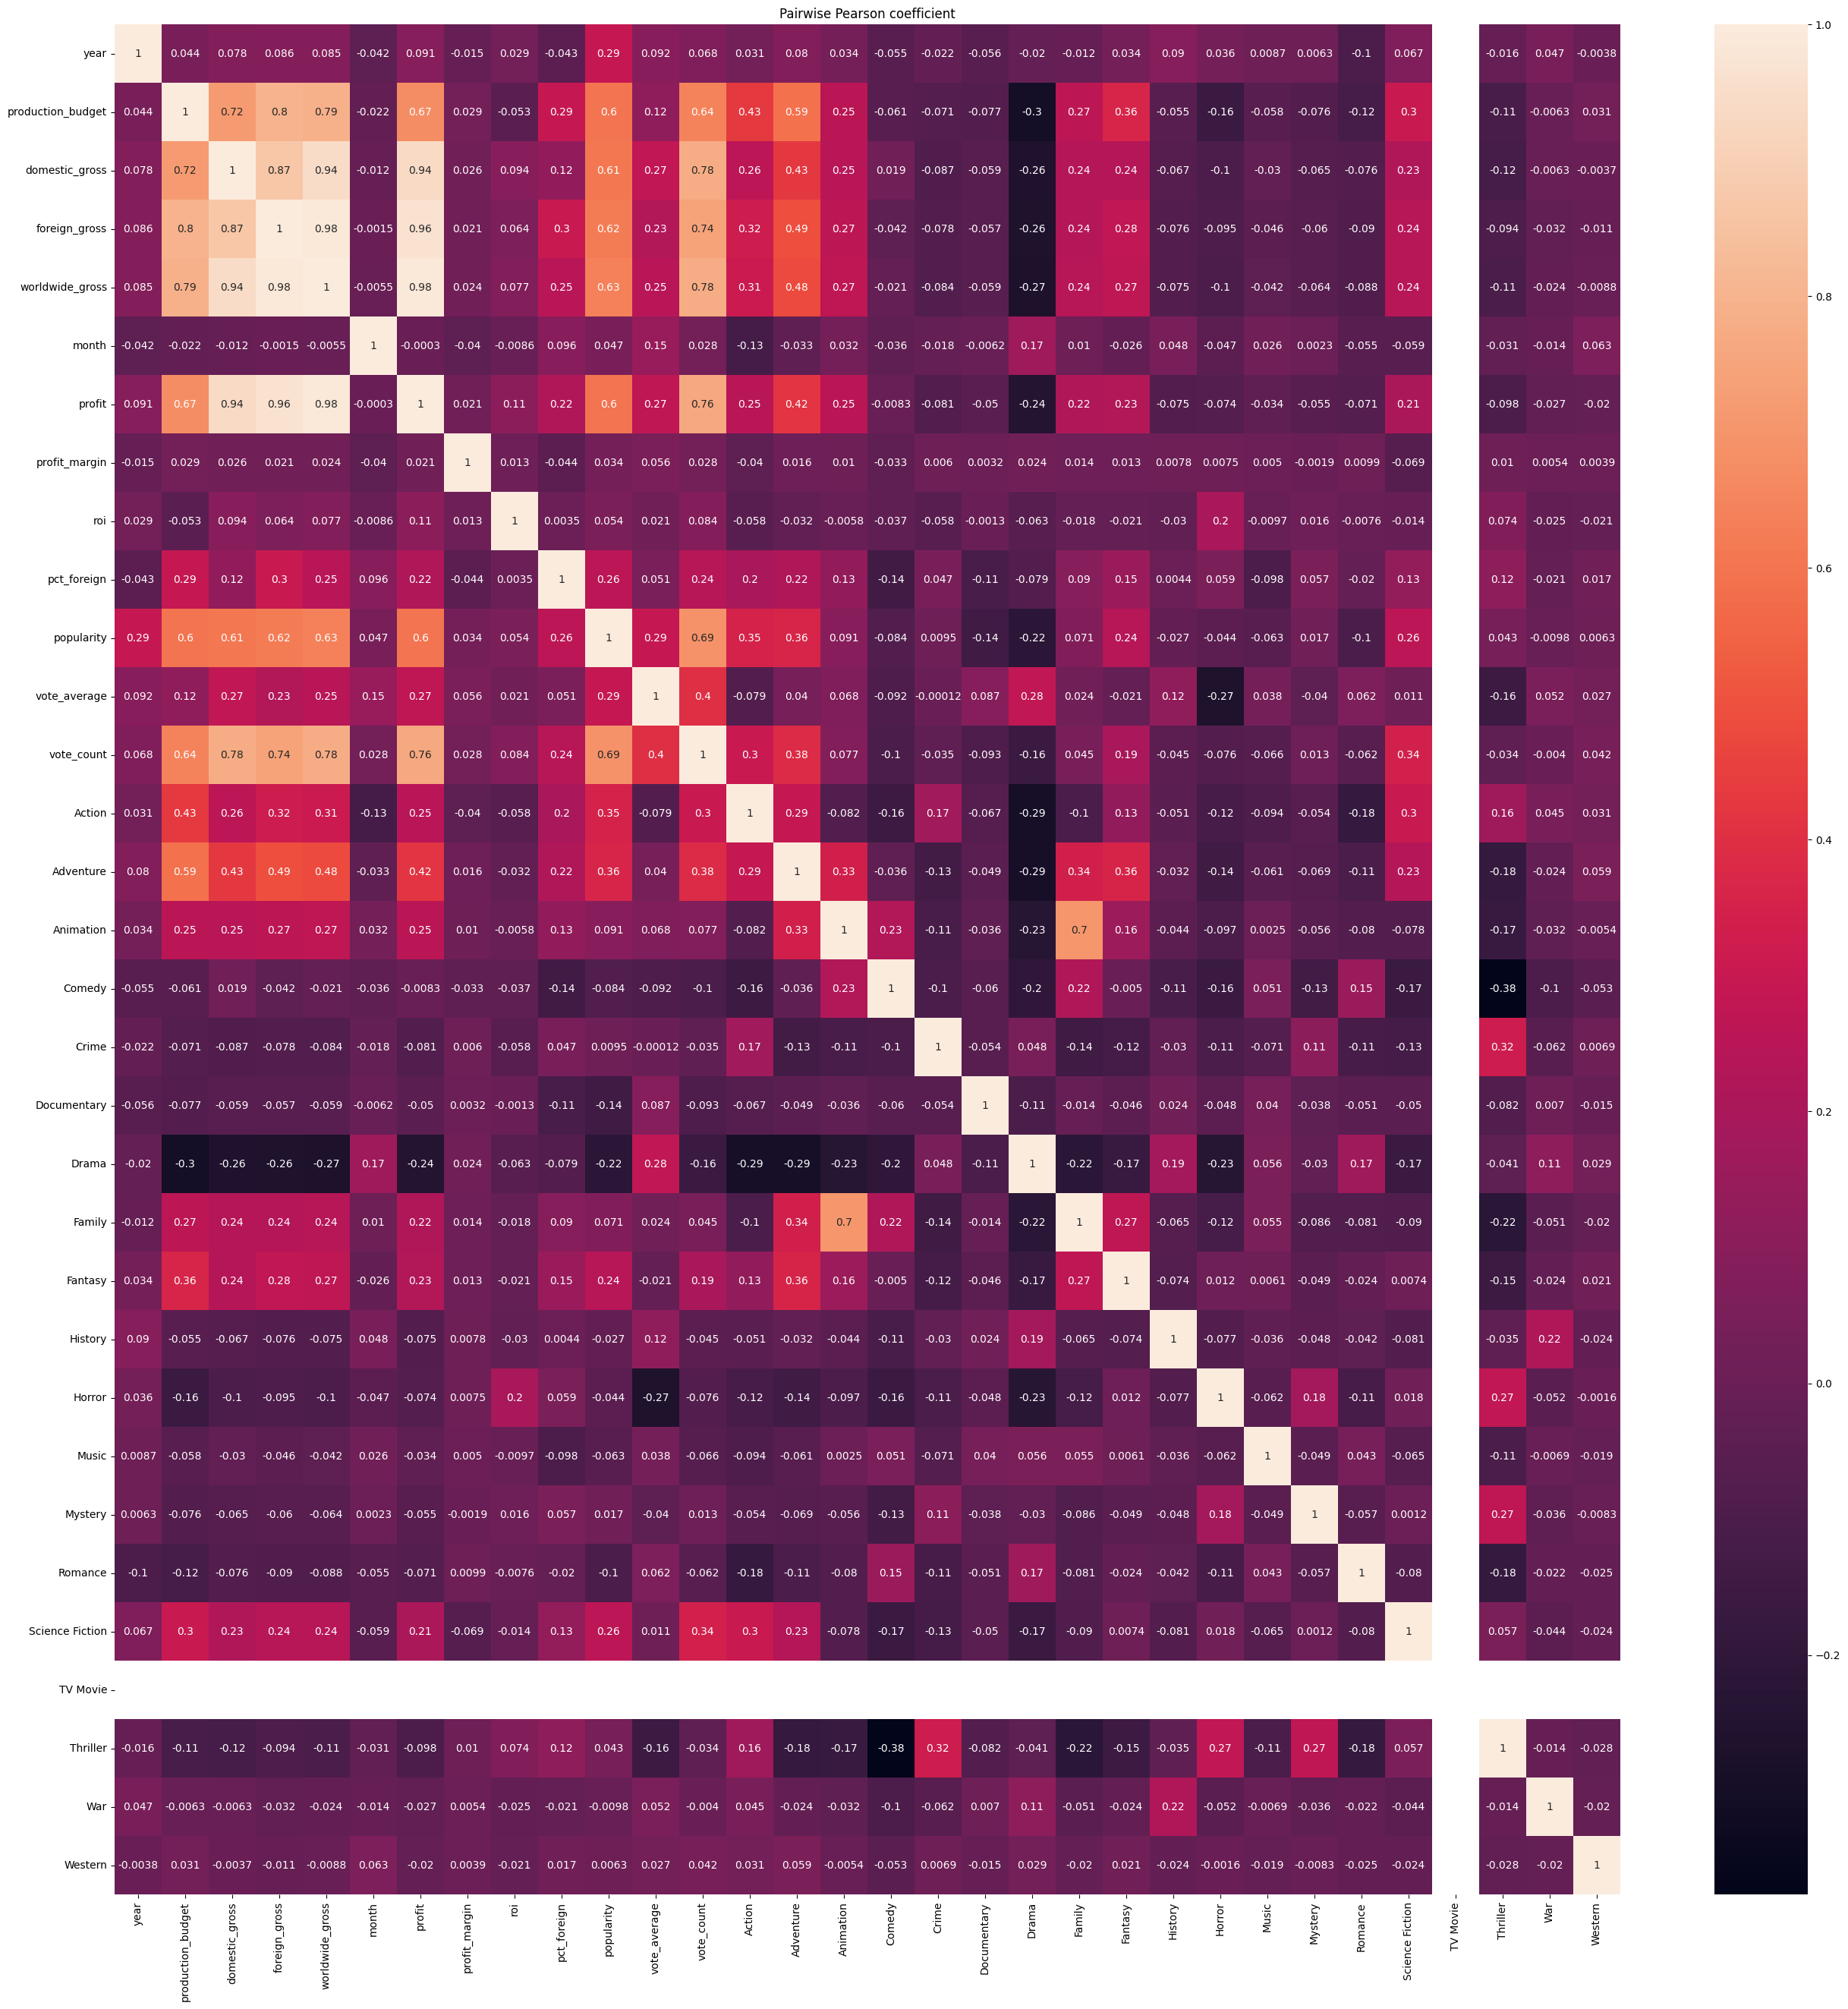

In [ ]:
fig, ax = plt.subplots(figsize=(32,32))
ax = sns.heatmap(data, annot=True)
ax.set_title('Pairwise Pearson coefficient')
plt.show()

## .2. Data splitting

In [ ]:
x = df_2[['production_budget','month', 'Action', 'Adventure', 'Animation', 'Comedy', 'Crime',
               'Documentary', 'Drama', 'Family', 'Fantasy', 'History',
               'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction', 'Thriller', 'War', 'Western']]
y = df_2['worldwide_gross']

In [ ]:
x.head()

,production_budget,month,Action,Adventure,Animation,Comedy,Crime,Documentary,Drama,Family,Fantasy,History,Horror,Music,Mystery,Romance,Science Fiction,Thriller,War,Western
1,410600000,5,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
2,330600000,5,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
3,300000000,4,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
4,300000000,11,1,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0
6,300000000,11,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
y.head()

,worldwide_gross
1,1045663875
2,1403013963
3,2048134200
4,655945209
6,879620923


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=42)

In [ ]:
x_train.shape

(1169, 20)

In [ ]:
x_test.shape

(293, 20)

In [ ]:
y_train.shape

(1169,)

In [ ]:
y_test.shape

(293,)

## .3. Training the Model Based on Worldwide Gross Revenue

In [ ]:
scaling = StandardScaler()

x_train_scale = scaling.fit_transform(x_train)
x_test_scale = scaling.fit_transform(x_test)

In [ ]:
lr_model = LinearRegression()
lr_model.fit(x_train, y_train)
lr_model_scale = lr_model.fit(x_train_scale, y_train)

In [ ]:
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(x_train, y_train)
dt_model_scale =dt_model.fit(x_train_scale, y_train)

In [ ]:
rf_model = RandomForestRegressor(random_state=42, n_estimators=100)
rf_model.fit(x_train, y_train)
rf_model_scale = rf_model.fit(x_train_scale, y_train)

In [ ]:
knr_model = KNeighborsRegressor(n_neighbors=10)
knr_model.fit(x_train, y_train)
knr_model_scale = knr_model.fit(x_train_scale, y_train)

In [ ]:
svr_model = SVR(kernel='linear')
# svr_model.fit(x_train, y_train)
svr_model_scale = svr_model.fit(x_train_scale, y_train)

### Evaluation

In [ ]:
lr_model_scale_y_pred = lr_model_scale.predict(x_test_scale)
lr_model_scale_y_pred

lr_model_scale_mse = mean_squared_error(y_test, lr_model_scale.predict(x_test_scale))
lr_model_scale_r2 = r2_score(y_test, lr_model_scale.predict(x_test_scale))

In [ ]:
dt_model_scale_y_pred = dt_model_scale.predict(x_test_scale)
dt_model_scale_y_pred

dt_model_scale_mse = mean_squared_error(y_test, dt_model.predict(x_test_scale))
dt_model_scale_r2 = r2_score(y_test, dt_model_scale.predict(x_test_scale))


In [ ]:
rf_model_scale_y_pred = rf_model_scale.predict(x_test_scale)
rf_model_scale_y_pred

rf_model_scale_mse = mean_squared_error(y_test, rf_model_scale.predict(x_test_scale))
rf_model_scale_r2 = r2_score(y_test, rf_model_scale.predict(x_test_scale))


In [ ]:
knr_model_scale_pred = knr_model_scale.predict(x_test_scale)
knr_model_scale_pred

knr_model_scale_mse = mean_squared_error(y_test, knr_model_scale.predict(x_test_scale))
knr_model_scale_r2 = r2_score(y_test, knr_model_scale.predict(x_test_scale))


In [ ]:
svr_model_scale_pred = svr_model_scale.predict(x_test_scale)
svr_model_scale_pred

svr_model_scale_mse = mean_squared_error(y_test, svr_model_scale.predict(x_test_scale))
svr_model_scale_r2 = r2_score(y_test, svr_model_scale.predict(x_test_scale))

### Prediction Model Results for Worldwide Gross Revenue

In [ ]:
print('Linear Regression - MSE:',lr_model_scale_mse)
print('Linear Regression - R-squared' ,lr_model_scale_r2)

print('Decision Tree - MSE:',dt_model_scale_mse)
print('Decision Tree - R-squared: ',dt_model_scale_r2)

print('Random Forest - MSE', rf_model_scale_mse)
print('Random Forest - R-squared:', rf_model_scale_r2)

print('K-Nearest Neighbors - MSE',knr_model_scale_mse)
print('K-Nearest Neighbors - R-squared', knr_model_scale_r2)

print('SVR - MSE',svr_model_scale_mse)
print('SVR - R-squared', svr_model_scale_r2)


Linear Regression - MSE: 2.2680500959706324e+16
Linear Regression - R-squared 0.5711261515208788
Decision Tree - MSE: 4.392737767096786e+16
Decision Tree - R-squared:  0.16936122580302393
Random Forest - MSE 2.7128846117131052e+16
Random Forest - R-squared: 0.48701077371606216
K-Nearest Neighbors - MSE 3.3381967516531344e+16
K-Nearest Neighbors - R-squared 0.3687682250028578
SVR - MSE 5.948459164401445e+16
SVR - R-squared -0.12481579612815485


Based on the initial results, the Linear Regression model achieved the best performance:

* Linear Regression – MSE: 2.2680500959706324e+16
* Linear Regression – R-squared: 0.5711261515208788

The Random Forest model achieved the second-best performance:

* Random Forest – MSE: 2.7128846117131052e+16
* Random Forest – R-squared: 0.48701077371606216

## .4. Training the Model Based on Profit


Based on the initial revenue prediction, we will proceed with a profit prediction model.


In [ ]:
target_profit = 'profit'
y_profit = df_2[target_profit]

In [ ]:
x_train_profit, x_test_profit, y_train_profit, y_test_profit = train_test_split(x, y_profit, test_size=0.2, random_state=42)

In [ ]:
x_train_profit_scale = scaling.fit_transform(x_train_profit)
x_test_profit_scale = scaling.transform(x_test_profit)

In [ ]:
lr_model.fit(x_train_profit_scale, y_train_profit)
lr_model_y_pred_profit = lr_model.predict(x_test_profit_scale)

mse_profit_linear = mean_squared_error(y_test_profit, lr_model_y_pred_profit)
r2_profit_linear = r2_score(y_test_profit, lr_model_y_pred_profit)


In [ ]:
dt_model.fit(x_train_profit, y_train_profit)
dt_model_y_pred_profit = dt_model.predict(x_test_profit)

mse_profit_tree = mean_squared_error(y_test_profit, dt_model_y_pred_profit)
r2_profit_tree = r2_score(y_test_profit, dt_model_y_pred_profit)

In [ ]:
rf_model.fit(x_train_profit, y_train_profit)
rf_model_y_pred_profit = rf_model.predict(x_test_profit)

mse_profit_forest = mean_squared_error(y_test_profit, rf_model_y_pred_profit )
r2_profit_forest = r2_score(y_test_profit, rf_model_y_pred_profit)

In [ ]:
knr_model.fit(x_train_profit_scale, y_train_profit)
knr_model_y_pred_profit = knr_model.predict(x_test_profit_scale)

mse_profit_knn = mean_squared_error(y_test_profit, knr_model_y_pred_profit)
r2_profit_knn = r2_score(y_test_profit, knr_model_y_pred_profit)

In [ ]:
svr_model.fit(x_train_profit_scale, y_train_profit)
svr_model_y_pred_profit = svr_model.predict(x_test_profit_scale)

mse_profit_svr = mean_squared_error(y_test_profit, svr_model_y_pred_profit)
r2_profit_svr = r2_score(y_test_profit, svr_model_y_pred_profit)

### Prediction Model Results for Profit

In [ ]:
print("Linear Regression (Profit) - MSE:", mse_profit_linear)
print("Linear Regression (Profit) - R-squared:", r2_profit_linear)

print("Decision Tree (Profit) - MSE:", mse_profit_tree)
print("Decision Tree (Profit) - R-squared:", r2_profit_tree)

print("Random Forest (Profit) - MSE:", mse_profit_forest)
print("Random Forest (Profit) - R-squared:", r2_profit_forest)

print("K-Nearest Neighbors (Profit) - MSE:", mse_profit_knn)
print("K-Nearest Neighbors (Profit) - R-squared:", r2_profit_knn)

print("SVR (Profit) - MSE:", mse_profit_svr)
print("SVR (Profit) - R-squared:", r2_profit_svr)

Linear Regression (Profit) - MSE: 2.260046621774825e+16
Linear Regression (Profit) - R-squared: 0.4045764343215693
Decision Tree (Profit) - MSE: 4.6035402679350056e+16
Decision Tree (Profit) - R-squared: -0.212831777304459
Random Forest (Profit) - MSE: 2.370352420739577e+16
Random Forest (Profit) - R-squared: 0.37551567446741063
K-Nearest Neighbors (Profit) - MSE: 2.8129328452533784e+16
K-Nearest Neighbors (Profit) - R-squared: 0.25891506458417934
SVR (Profit) - MSE: 4.261402726224657e+16
SVR (Profit) - R-squared: -0.12269347968047062


Based on the initial revenue prediction, the Linear Regression model achieved the best performance for predicting profit:

* Linear Regression (Profit) – MSE: 2.2600466217748244e+16

* Linear Regression (Profit) – R-squared: 0.4045764343215693

## .5. Hyperparameter Tuning


In [ ]:
target_revenue = 'worldwide_gross'
target_profit = 'profit'

X = df_2[['production_budget','month', 'Action', 'Adventure', 'Animation', 'Comedy', 'Crime',
               'Documentary', 'Drama', 'Family', 'Fantasy', 'History',
               'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction', 'Thriller', 'War', 'Western']]
y_revenue = df_2[target_revenue]
y_profit = df_2[target_profit]



In [ ]:
# Split the data into training and testing sets for revenue
X_train_rev, X_test_rev, y_train_rev, y_test_rev = train_test_split(X, y_revenue, test_size=0.2, random_state=42)

# Split the data into training and testing sets for profit
X_train_profit, X_test_profit, y_train_profit, y_test_profit = train_test_split(X, y_profit, test_size=0.2, random_state=42)


In [ ]:
# Standardize the features
scaling_rev = StandardScaler()
X_train_rev_scale = scaling_rev.fit_transform(X_train_rev)
X_test_rev_scale = scaling_rev.transform(X_test_rev)

scaling_profit = StandardScaler()
X_train_profit_scale = scaling_profit.fit_transform(X_train_profit)
X_test_profit_scale = scaling_profit.transform(X_test_profit)

In [ ]:
# Define the Linear Regression model and parameter grid
lr_model = LinearRegression()
lr_model = LinearRegression()
lr_param_grid = {
    'fit_intercept': [True, False]
}

# Define the Random Forest model and parameter grid
rf_model = RandomForestRegressor(random_state=42)
rf_param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'bootstrap': [True, False]
}

In [ ]:
# Perform Grid Search for revenue prediction
!pip install scikit-learn
from sklearn.model_selection import GridSearchCV

In [ ]:
# Perform GridSearchCV for Linear Regression for revenue prediction
grid_search_lr_rev = GridSearchCV(estimator=lr_model, param_grid=lr_param_grid, cv=3, n_jobs=-1, scoring='r2', verbose=1)
grid_search_lr_rev.fit(X_train_rev_scale, y_train_rev)
best_lr_model_rev = grid_search_lr_rev.best_estimator_

# Perform GridSearchCV for Random Forest for revenue prediction
grid_search_rf_rev = GridSearchCV(estimator=rf_model, param_grid=rf_param_grid, cv=3, n_jobs=-1, scoring='r2', verbose=1)
grid_search_rf_rev.fit(X_train_rev_scale, y_train_rev)
best_rf_model_rev = grid_search_rf_rev.best_estimator_


Fitting 3 folds for each of 2 candidates, totalling 6 fits
Fitting 3 folds for each of 48 candidates, totalling 144 fits


In [ ]:
# Perform GridSearchCV for Linear Regression for profit prediction
grid_search_lr_profit = GridSearchCV(estimator=lr_model, param_grid=lr_param_grid, cv=3, n_jobs=-1, scoring='r2', verbose=1)
grid_search_lr_profit.fit(X_train_profit_scale, y_train_profit)
best_lr_model_profit = grid_search_lr_profit.best_estimator_

# Perform GridSearchCV for Random Forest for profit prediction
grid_search_rf_profit = GridSearchCV(estimator=rf_model, param_grid=rf_param_grid, cv=3, n_jobs=-1, scoring='r2', verbose=1)
grid_search_rf_profit.fit(X_train_profit_scale, y_train_profit)
best_rf_model_profit = grid_search_rf_profit.best_estimator_

Fitting 3 folds for each of 2 candidates, totalling 6 fits
Fitting 3 folds for each of 48 candidates, totalling 144 fits


In [ ]:
print("Best Linear Regression Model for Revenue:", best_lr_model_rev)
print("Best Random Forest Model for Revenue:", best_rf_model_rev)
print("Best Linear Regression Model for Profit:", best_lr_model_profit)
print("Best Random Forest Model for Profit:", best_rf_model_profit)

Best Linear Regression Model for Revenue: LinearRegression()
Best Random Forest Model for Revenue: RandomForestRegressor(max_depth=10, min_samples_leaf=2, min_samples_split=5,
                      random_state=42)
Best Linear Regression Model for Profit: LinearRegression()
Best Random Forest Model for Profit: RandomForestRegressor(max_depth=10, min_samples_leaf=2, min_samples_split=5,
                      n_estimators=50, random_state=42)


In [ ]:
# Make predictions on the test set
y_pred_lr_rev = best_lr_model_rev.predict(X_test_rev_scale)
y_pred_rf_rev = best_rf_model_rev.predict(X_test_rev_scale)
y_pred_lr_profit = best_lr_model_profit.predict(X_test_profit_scale)
y_pred_rf_profit = best_rf_model_profit.predict(X_test_profit_scale)

# Calculate and print metrics for revenue prediction
mse_lr_rev = mean_squared_error(y_test_rev, y_pred_lr_rev)
r2_lr_rev = r2_score(y_test_rev, y_pred_lr_rev)
mse_rf_rev = mean_squared_error(y_test_rev, y_pred_rf_rev)
r2_rf_rev = r2_score(y_test_rev, y_pred_rf_rev)

print("Revenue Prediction - Linear Regression:")
print("MSE:", mse_lr_rev)
print("R^2:", r2_lr_rev)

print("Revenue Prediction - Random Forest:")
print("MSE:", mse_rf_rev)
print("R^2:", r2_rf_rev)

# Calculate and print metrics for profit prediction
mse_lr_profit = mean_squared_error(y_test_profit, y_pred_lr_profit)
r2_lr_profit = r2_score(y_test_profit, y_pred_lr_profit)
mse_rf_profit = mean_squared_error(y_test_profit, y_pred_rf_profit)
r2_rf_profit = r2_score(y_test_profit, y_pred_rf_profit)

print("Profit Prediction - Linear Regression:")
print("MSE:", mse_lr_profit)
print("R^2:", r2_lr_profit)

print("Profit Prediction - Random Forest:")
print("MSE:", mse_rf_profit)
print("R^2:", r2_rf_profit)

Revenue Prediction - Linear Regression:
MSE: 2.2600466217748256e+16
R^2: 0.5726395575896677
Revenue Prediction - Random Forest:
MSE: 2.362938587361107e+16
R^2: 0.5531833412843197
Profit Prediction - Linear Regression:
MSE: 2.260046621774825e+16
R^2: 0.4045764343215693
Profit Prediction - Random Forest:
MSE: 2.238397225186981e+16
R^2: 0.4102801046737312


# VII. Comparison of Results

After applying hyperparameter tuning, the MSE and R-squared results for the models are as follows:

Revenue Prediction

Linear Regression

MSE: 2.260046621774825e+16
R²: 0.5726395575896677

Random Forest

MSE: 2.362938587361107e+16
R²: 0.5531833412843197
Profit Prediction

Linear Regression

MSE: 2.2600466217748244e+16
R²: 0.4045764343215693

Random Forest

MSE: 2.238397225186981e+16
R²: 0.4102801046737312




## Other Possible Adjustments

Some additional adjustments could be made to improve the prediction models:

Further filter df_2 by removing films with very low production budgets, such as films with budgets below $9 million.
Add additional information, such as marketing and promotional costs, audience interest in a film, and the actors starring in the film.

These parameters could be adjusted and optimized to potentially improve the performance of the prediction models.

